    # Calibration / sanity check

**Цель ноутбука:** охарактеризовать поведение критериев на обученных нейросетях, проверить их базовую работоспособность и task selectivity, а также определить устойчивую конфигурацию гиперпараметров для последующих экспериментов.

---

## Что анализируется для каждого набора гиперпараметров

**A. Detector validity** — score одного идеального planted нейрона.

**Задача:** показать, что детектор в принципе способен обнаружить заведомо существующую целевую геометрию и тем самым подтвердить базовую работоспособность реализации.

**B. False-positive behaviour** — распределение скоров на 4–5 заранее зафиксированных null-features.

**Задача:** показать, как детектор ведёт себя на заведомо отрицательных объектах и установить эмпирический baseline ложных срабатываний.

**C. Task irrelevance** — распределения скоров на task-irrelevant окружности и на null-features датасета A.

**Задача:** показать, что наличие геометрической фичи, не требуемой задачей, не приводит к систематической детекции по сравнению с null baseline.

**D. Task relevance** — распределения скоров на task-relevant окружности и на null-features датасета B.

**Задача:** показать, что детектор способен обнаруживать геометрию, которая действительно необходима для решения задачи, и что это поведение отличается от null baseline.

**E. Selectivity** — прямое сравнение скоров на task-relevant и task-irrelevant окружностях.

**Задача:** показать, что детектор реагирует именно на task relevance, а не просто на наличие или геометрическую форму окружности.

**F. Numerical stability and frozen methodological specification**

Для всех A–E рассматривается зависимость соответствующих результатов от
[
\theta=(\text{resolution}, n_{\mathrm{levels}}, \varepsilon,\ldots).
]

Ищется область, в которой при изменении численных гиперпараметров:

* результаты остаются в пределах заранее заданной численной погрешности;
* сохраняются качественные выводы A–E;
* не происходит смены интерпретации поведения детектора.

**Задача:** показать, что свойства детектора не являются артефактом конкретного выбора численных гиперпараметров, и на основании этого зафиксировать рабочую конфигурацию для всех последующих экспериментов.

---

## План проведения первого эксперимента

**Выбираем два датасета**, как указано выше:

* A: `halfplane` — окружность task-irrelevant;
* B: `ring-separation` — окружность task-relevant.

**Обучаем по 50 нейросетей** на каждом датасете.

**Основная часть ноутбука — перебор гиперпараметров критериев.** Для каждого набора гиперпараметров считаем:

* критерий на **каждом нейроне каждой модели**;
* критерий **один раз на идеальном подсаженном нейроне**;
* для датасета A — на **4–5 заранее зафиксированных** `null_features` и на task-irrelevant feature;
* для датасета B — на тех же `null_features` и на task-relevant feature.

Для каждого набора гиперпараметров получаем:

* одно значение на идеальном подсаженном нейроне;
* распределение скоров на null-features;
* распределение скоров на task-irrelevant feature;
* распределение скоров на task-relevant feature.

Далее анализируем:

* **Detector validity** — способен ли критерий обнаружить идеальный planted witness;
* **False-positive behaviour** — каков baseline на null-features;
* **Task irrelevance** — отсутствует ли систематическая детекция task-irrelevant feature;
* **Task relevance** — обнаруживается ли task-relevant feature;
* **Selectivity** — различаются ли task-relevant и task-irrelevant features;
* **Numerical stability and frozen methodological specification** — выходят ли результаты на устойчивый режим при изменении гиперпараметров и можно ли на основании этого зафиксировать рабочую конфигурацию.

**Результат ноутбука:**

* получить набор методологических рекомендаций по выбору гиперпараметров, который будет зафиксирован и использован в следующих экспериментах;
* подтвердить базовую работоспособность критериев;
* **показать, что критерии различают task-relevant и task-irrelevant features, а не просто реагируют на наличие соответствующей геометрии.**

**Это является основной научной задачей данного ноутбука.**


In [1]:
# Корень репозитория как CWD, src/ в sys.path — соглашение слоя персистентности.
import os, sys
from pathlib import Path

root = Path.cwd()
while not (root / "src" / "analysis").is_dir():
    assert root != root.parent, "корень репозитория не найден"
    root = root.parent
os.chdir(root)
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import torch, pandas as pd
pd.set_option("display.width", 200)
print("CWD:", Path.cwd())

from analysis.lab import ExperimentLab
from analysis.null_placement import at, shift, preview
from analysis.stat_aggregation import bounds_from_X
from analysis.null_placement import random_placements
from models.NN_analysis import TruncatedMLPFunction, ScalarProjection
from analysis.criterions import structural_criterion
from data.dataset_recipes import make_simple_dataset
from management.experiment_management import store_dataset_instance, load_dataset_instance, get_feature_points
import numpy as np, pandas as pd, time
import analysis.calibration as cal
from analysis.null_placement import build_null_features, placement_report
from analysis.stat_aggregation import find_model_paths_for_dataset
from management.experiment_management import load_model_instance, get_feature_points
from experiments.registry import EXPERIMENTS

CWD: /home/serdabel/Desktop/proga/CL_neuron_level_sets


## 1. Introduce two datasets:

In [2]:
# irrelevant_dataset = make_simple_dataset(relevant=False)
# irrelevant_dataset.plot()

In [3]:
# relevant_dataset = make_simple_dataset(relevant=True)
# relevant_dataset.plot()

In [4]:
# # store_dataset_instance(name="simple_irrelevant", data=irrelevant_dataset)
# # store_dataset_instance(name="simple_relevant", data=relevant_dataset)
# 
# relevant_dataset = load_dataset_instance(
#     "data/dataset_instances/simple_relevant/"
#     "simple_relevant_0/"
# )
# 
# irrelevant_dataset = load_dataset_instance(
#     "data/dataset_instances/simple_irrelevant/"
#     "simple_irrelevant_0/"
# )
# 
# print("Relevant --- X:", tuple(relevant_dataset["X"].shape), "| features:", list(relevant_dataset.get("features", {})))
# print("Irrelevant - X:", tuple(irrelevant_dataset["X"].shape), "| features:", list(irrelevant_dataset.get("features", {})))

## 2. Train 50 models on each dataset to 100% accuracy:

done in the "exp1_sanity_check_mass.ipynb" notebook

## 3. Fix bounding box and null-features

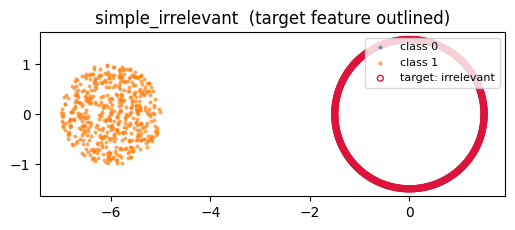

{'experiment': 'exp1_sanity_check',
 'dataset': 'simple_irrelevant',
 'arch': 'tanh_w5_d5',
 'n_models': 1,
 'n_epochs': 300,
 'target_acc': 1.0,
 'lr': 0.001,
 'batch_size': 64,
 'optimizer': 'adam',
 'weight_decay': 0.0,
 'resolution': 200,
 'target_feature': 'irrelevant',
 'primary_witness_column': 'is_structural_witness'}

In [5]:
lab_irrel = ExperimentLab("exp1_sanity_check", dataset="simple_irrelevant")
lab_irrel.show_dataset()
lab_irrel.config()

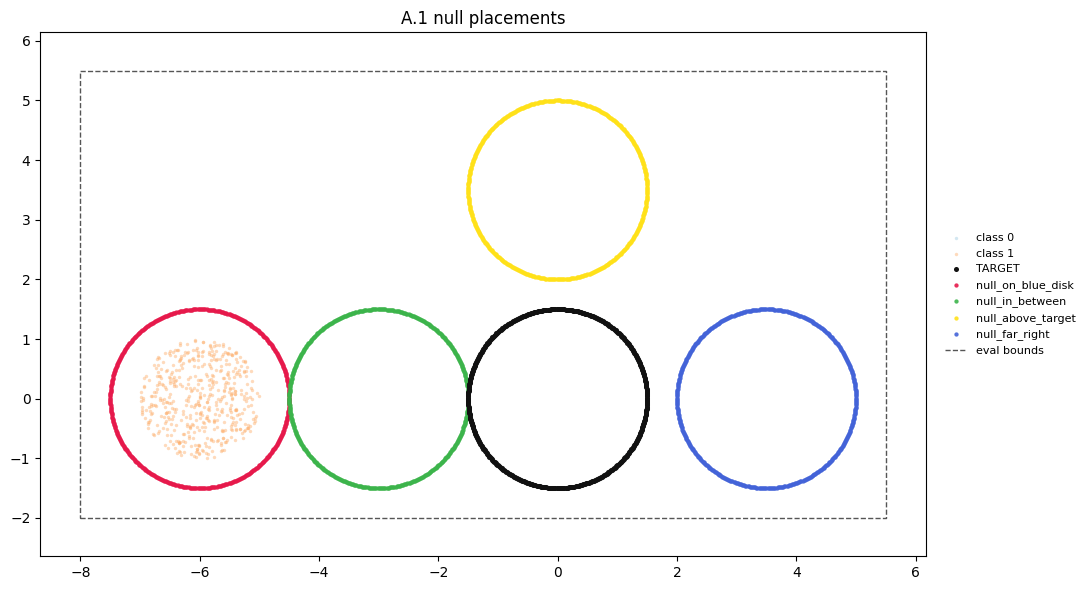

In [6]:
placements = [
    at( -6.0,  0.0, name="on_blue_disk"),   # прямо на данных противоположного класса
    at( -3.0,  0.0, name="in_between"),       # в пустом коридоре, на границе решения
    at( 0.0,  3.5, name="above_target"),   # рядом с целью, тот же режим
    at( 3.5, 0.0, name="far_right")
]

report = lab_irrel.set_null_placements(placements)

_ = preview(lab_irrel.dataset()["X"], lab_irrel.dataset()["y"],
            lab_irrel.feature_points(),      # цель
            lab_irrel.null_features,         # контроли
            bounds=lab_irrel.bounds())       # пунктир — область, на которой считается поле

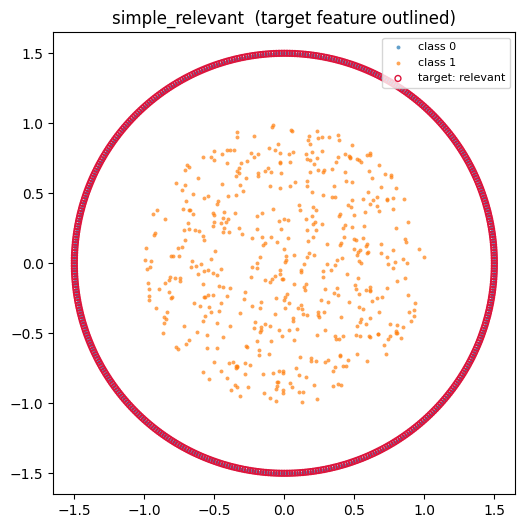

{'experiment': 'exp1_sanity_check',
 'dataset': 'simple_relevant',
 'arch': 'tanh_w5_d5',
 'n_models': 1,
 'n_epochs': 300,
 'target_acc': 1.0,
 'lr': 0.001,
 'batch_size': 64,
 'optimizer': 'adam',
 'weight_decay': 0.0,
 'resolution': 200,
 'target_feature': 'relevant',
 'primary_witness_column': 'is_structural_witness'}

In [7]:
lab_rel = ExperimentLab("exp1_sanity_check", dataset="simple_relevant")
lab_rel.show_dataset()
lab_rel.config()

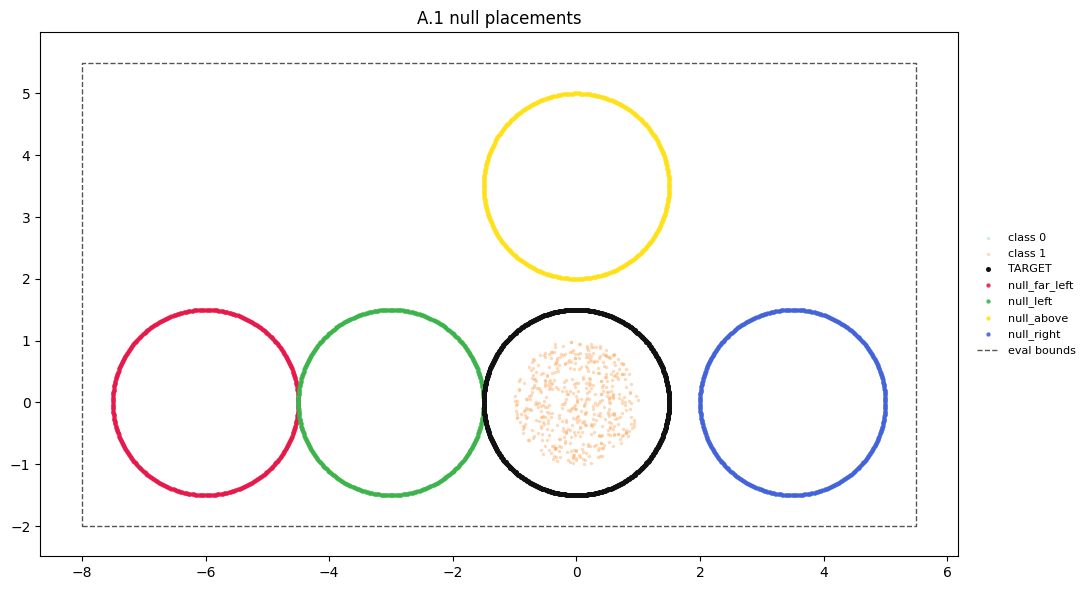

In [8]:
placements = [
    at( -6.0,  0.0, name="far_left"),   
    at( -3.0,  0.0, name="left"),
    at( 0.0,  3.5, name="above"), 
    at( 3.5, 0.0, name="right")
]

report_rel = lab_rel.set_null_placements(placements)

_ = preview(lab_rel.dataset()["X"], lab_irrel.dataset()["y"],
            lab_rel.feature_points(),      # цель
            lab_rel.null_features,         # контроли
            bounds=lab_rel.bounds())       # пунктир — область, на которой считается поле

----
## 1. Resolution sweep

Перебрать значения `resolution` при фиксированных `n_levels` и `level_eps`.

Для каждого значения посчитать:
- score идеального planted neuron;
- scores всех нейронов на `null_features`;
- scores всех нейронов на task-irrelevant feature датасета A;
- scores всех нейронов на task-relevant feature датасета B.

Проверить, выходит ли поведение критериев на плато и сохраняются ли основные качественные выводы.

---

In [9]:
lab_irrel.bounds(), lab_rel.bounds()

([(-8.0, 5.5), (-2.0, 5.5)], [(-8.0, 5.5), (-2.0, 5.5)])

In [10]:
# ── 0. Фиксируем всё, кроме resolution ────────────────────────────────────────
SPEC = EXPERIMENTS["exp1_sanity_check"]

# ОДИН бокс на оба датасета — иначе шаг сетки, а с ним и пол шкалы, различаются,
# и анализ E (selectivity) меряет дискретизацию наравне с task-relevance.
BOUNDS = [(-8.0, 5.5), (-2.0, 5.5)]        # ← ваши числа после выбора null-фич

RESOLUTIONS   = [25, 50, 100, 200, 400]
REFERENCE_RES = 200
ARCH_TAG      = "tanh_w5_d5_mass-train"
N_SWEEP_MODELS = 50        # ← главная ручка стоимости, см. оценку ниже
LAYER_IDS      = None     # None = все слои

# Только structural + homological: anchored сознательно исключён.
CRITS = {k: v for k, v in cal.criteria(SPEC.eval).items()
         if k in ("structural", "homological")}

# Порог структурного критерия — читается из спека, а не набирается руками.
TAU = SPEC.eval.structural_kwargs["threshold"]

In [11]:
# ── 1. Фичи: цель + нули. Окружность в обоих датасетах побитово одна и та же,
#      поэтому одни и те же placements дают буквально одинаковые нули. ─────────
# Список нулей выписан здесь явно, а не унаследован из ячеек выше: там переменная
# `placements` присваивается дважды (разметка та же, имена разные), и в PLACEMENTS
# попадало бы то, что выполнилось последним. Конфигурация свипа не должна зависеть
# от порядка запуска исследовательских ячеек — это те самые имена, под которыми
# посчитан sanity_resolution_sweep.csv.
PLACEMENTS = [
    at(-6.0, 0.0, name="on_blue_disk"),   # прямо на данных противоположного класса
    at(-3.0, 0.0, name="in_between"),     # пустой коридор, граница решения
    at( 0.0, 3.5, name="above_target"),   # рядом с целью, тот же режим
    at( 3.5, 0.0, name="far_right"),      # далеко справа
]

DATASETS = {
    "irrelevant": ("simple_irrelevant", "irrelevant"),
    "relevant":   ("simple_relevant",   "relevant"),
}

FEATURES, PATHS, DATA = {}, {}, {}
for tag, (ds_name, target) in DATASETS.items():
    d = load_dataset_instance(f"data/dataset_instances/{ds_name}/{ds_name}_0/",
                              reconstruct_data=False)
    DATA[tag] = d
    A = get_feature_points(d, target)
    FEATURES[tag] = {target: A, **build_null_features(A, PLACEMENTS)}
    PATHS[tag] = find_model_paths_for_dataset(ds_name, model_name=ARCH_TAG)
    print(f"{tag:11s}: {len(PATHS[tag]):3d} моделей | фичи: {list(FEATURES[tag])}")
    display(placement_report(A, {k: v for k, v in FEATURES[tag].items() if k != target},
                             X=d["X"], y=d["y"], bounds=BOUNDS))

irrelevant : 100 моделей | фичи: ['irrelevant', 'null_on_blue_disk', 'null_in_between', 'null_above_target', 'null_far_right']


,feature,centre,diam,separation,min_pair_sep,dist_to_data,nearest_class,in_bounds
0,TARGET,"(0.0, 0.0)",3.0,0.0000,NaN,0.0000,0,1.0
1,null_on_blue_disk,"(-6.0, 0.0)",3.0,1.5314,0.5636,0.5215,1,1.0
2,null_in_between,"(-3.0, 0.0)",3.0,0.5636,0.5636,1.0207,0,1.0
3,null_above_target,"(0.0, 3.5)",3.0,0.7209,1.0775,2.1627,0,1.0
4,null_far_right,"(3.5, 0.0)",3.0,0.7209,1.1880,2.1627,0,1.0


relevant   :  50 моделей | фичи: ['relevant', 'null_on_blue_disk', 'null_in_between', 'null_above_target', 'null_far_right']


,feature,centre,diam,separation,min_pair_sep,dist_to_data,nearest_class,in_bounds
0,TARGET,"(0.0, 0.0)",3.0,0.0000,NaN,0.0000,0,1.0
1,null_on_blue_disk,"(-6.0, 0.0)",3.0,1.5314,0.5636,4.5941,0,1.0
2,null_in_between,"(-3.0, 0.0)",3.0,0.5636,0.5636,1.6907,0,1.0
3,null_above_target,"(0.0, 3.5)",3.0,0.7209,1.0775,2.1627,0,1.0
4,null_far_right,"(3.5, 0.0)",3.0,0.7209,1.1880,2.1627,0,1.0


In [12]:
# ── 2. Оценка стоимости ДО запуска: время одного вычисления × число вычислений ─
probe_model, _ = load_model_instance(PATHS["relevant"][0])
n_neurons = sum(probe_model.blocks[l].linear.out_features
                for l in range(probe_model.n_layers))

t = time.perf_counter()
cal.measure(cal.trained_probe(probe_model, 0, 0, FEATURES["relevant"]["relevant"]),
            CRITS["structural"], BOUNDS, REFERENCE_RES)
per_eval = time.perf_counter() - t

n_evals = (len(RESOLUTIONS) * len(DATASETS) * N_SWEEP_MODELS
           * len(FEATURES["relevant"]) * n_neurons * len(CRITS))
print(f"нейронов на модель : {n_neurons}")
print(f"одно вычисление    : {per_eval:.2f} c (res={REFERENCE_RES})")
print(f"всего вычислений   : {n_evals}")
print(f"грубая оценка      : {n_evals * per_eval / 60:.0f} мин "
      f"(растёт ~R², так что верхние разрешения дороже среднего)")

нейронов на модель : 25
одно вычисление    : 0.30 c (res=200)
всего вычислений   : 125000
грубая оценка      : 635 мин (растёт ~R², так что верхние разрешения дороже среднего)


In [13]:
# ── 3. A: подсаженный нейрон — свип по resolution (секунды) ───────────────────
#     Известный ответ ДО измерения: этот нейрон — свидетель. Его score при каждом
#     R служит точкой отсчёта для всех остальных распределений, поэтому он тоже
#     кладётся на диск, рядом с ансамблем.
PLANTED_CSV = Path("analysis/results/calibration/sanity_resolution_planted.csv")

A_rel = FEATURES["relevant"]["relevant"]
planted = cal.planted_probe(probe_model, A_rel, layer_id=3, coord_id=0, name="planted")

if PLANTED_CSV.exists():
    df_A = cal.read_scores_csv(PLANTED_CSV)
    print(f"переиспользую {PLANTED_CSV}")
else:
    df_A = cal.scan([planted], CRITS, BOUNDS, REFERENCE_RES,
                    grid={"resolution": RESOLUTIONS}, verbose=True)
    PLANTED_CSV.parent.mkdir(parents=True, exist_ok=True)
    df_A.to_csv(PLANTED_CSV, index=False)

display(df_A.pivot_table(index="resolution", columns="criterion",
                         values=["score", "is_witness"]))

переиспользую analysis/results/calibration/sanity_resolution_planted.csv


is_witness                  score           
criterion  homological structural homological structural
resolution                                              
25                 1.0        0.0    0.347375   0.127846
50                 1.0        1.0    0.401333   0.094597
100                1.0        1.0    0.410869   0.074123
200                1.0        1.0    0.412388   0.034313
400                1.0        1.0    0.411859   0.020726

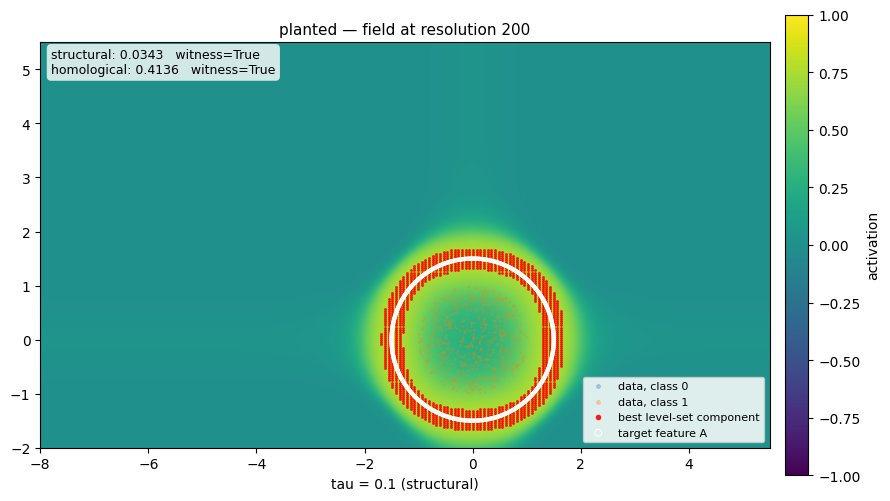

In [14]:
# ── 3b. Как выглядит подсаженный нейрон ──────────────────────────────────────
#     Его вердикт известен ДО измерения, поэтому картинка отвечает не «свидетель
#     ли он», а «что именно видит критерий»: где идёт гребень, какую компоненту
#     слоя уровня критерий выбирает и как она ложится на A.
#     Красное — выбранная компонента. Она КОЛЬЦО конечной толщины, а не кривая:
#     это eps-утолщение, и расстояние Чамфера от него до белой окружности и есть
#     накладные расходы инструмента (истинная геометрия гребня — 0.0016).
#     Поле нигде не насыщено (доходит до ~0.76, а не до 1) — так построен
#     plant_radial_neuron, и отсюда же скромный гомологический margin.
from visualization.calibration_plots import plot_probe_field

_ = plot_probe_field(planted, BOUNDS, REFERENCE_RES, criteria_specs=CRITS,
                     threshold=TAU,
                     X=DATA["relevant"]["X"], y=DATA["relevant"]["y"])

In [15]:
# ── 4. B/C/D: ансамбль × фичи × нейроны, для каждого resolution ───────────────
#     Каждая тройка (R, датасет, критерий) сохраняется СРАЗУ после подсчёта:
#     прогон целиком идёт часы, и падение ядра на последнем шаге не должно
#     стоить всех предыдущих. Уже посчитанные куски переиспользуются, так что
#     ячейку можно перезапускать сколько угодно — пересчитывается только то,
#     чего ещё нет. Чтобы пересчитать кусок заново, удалите его файл.
PARTS = Path("analysis/results/calibration/sweep_parts")
PARTS.mkdir(parents=True, exist_ok=True)
SWEEP_CSV = Path("analysis/results/calibration/sanity_resolution_sweep.csv")

frames = []
for res in RESOLUTIONS:
    for tag, (ds_name, target) in DATASETS.items():
        for cname, crit in CRITS.items():
            part = PARTS / f"res{res}_{tag}_{cname}.csv"
            if part.exists():
                # read_scores_csv, а не read_csv: pandas читает голое "null" в
                # колонке role как NaN и молча теряет ровно те строки, из
                # которых состоит пол.
                df = cal.read_scores_csv(part)
                print(f"res={res:4d} {tag:11s} {cname:12s} {len(df):5d} строк ← {part.name}")
            else:
                t0 = time.perf_counter()
                df = cal.ensemble_scores(
                    PATHS[tag][:N_SWEEP_MODELS], FEATURES[tag], BOUNDS, res,
                    crit, target_name=target, layer_ids=LAYER_IDS, verbose=False)
                df.to_csv(part, index=False)
                print(f"res={res:4d} {tag:11s} {cname:12s} {len(df):5d} строк за "
                      f"{time.perf_counter() - t0:.0f} c → {part.name}")
            df["resolution"], df["dataset"], df["criterion"] = res, tag, cname
            frames.append(df)

ens = pd.concat(frames, ignore_index=True)
ens.to_csv(SWEEP_CSV, index=False)
print(f"\nвсего {len(ens)} строк → {SWEEP_CSV}")

res=  25 irrelevant  structural    6250 строк ← res25_irrelevant_structural.csv
res=  25 irrelevant  homological   6250 строк ← res25_irrelevant_homological.csv
res=  25 relevant    structural    6250 строк ← res25_relevant_structural.csv
res=  25 relevant    homological   6250 строк ← res25_relevant_homological.csv
res=  50 irrelevant  structural    6250 строк ← res50_irrelevant_structural.csv
res=  50 irrelevant  homological   6250 строк ← res50_irrelevant_homological.csv
res=  50 relevant    structural    6250 строк ← res50_relevant_structural.csv
res=  50 relevant    homological   6250 строк ← res50_relevant_homological.csv
res= 100 irrelevant  structural    6250 строк ← res100_irrelevant_structural.csv
res= 100 irrelevant  homological   6250 строк ← res100_irrelevant_homological.csv
res= 100 relevant    structural    6250 строк ← res100_relevant_structural.csv
res= 100 relevant    homological   6250 строк ← res100_relevant_homological.csv
res= 200 irrelevant  structural    6250 ст

In [16]:
# ── 5. Свод: единица наблюдения — лучший нейрон пары (модель, фича) ──────────
#     Не доля свидетелей: она наследует множественность, растущую с шириной сети
#     по построению (CALIBRATION.md 3.1). И не «лучший из всех нулей»: у цели
#     одна фича, у пола — четыре размещения, и общий минимум дал бы полу
#     четырёхкратную множественность, которой у цели нет. Разброс МЕЖДУ
#     размещениями — это ширина пола, а не шум.
summary = cal.sweep_summary(ens)
contrast = pd.concat([
    cal.sweep_contrast(ens[ens.criterion == "structural"], threshold=TAU),
    cal.sweep_contrast(ens[ens.criterion == "homological"]),
], ignore_index=True)

summary.to_csv("analysis/results/calibration/sanity_resolution_summary.csv", index=False)
contrast.to_csv("analysis/results/calibration/sanity_resolution_contrast.csv", index=False)

for cname in CRITS:
    print("=" * 118)
    print(cname)
    display(summary[summary.criterion == cname].round(4))
    display(contrast[contrast.criterion == cname].round(4))

structural


,criterion,resolution,dataset,role,n_neurons,detected_neurons,neuron_median,neuron_q10,neuron_q90,n_units,detected_units,best_median,best_q10,best_q90,best_extreme,lower_is_better
20,structural,25,irrelevant,null,5000,1.0,0.4374,0.2286,0.6253,200,1.0,0.2453,0.1766,0.4325,0.1591,True
21,structural,25,irrelevant,target,1250,1.0,0.5673,0.4475,0.7502,50,1.0,0.4117,0.3027,0.4513,0.1765,True
22,structural,25,relevant,null,5000,1.0,0.4696,0.2271,0.7984,200,1.0,0.2243,0.1726,0.3696,0.1476,True
23,structural,25,relevant,target,1250,1.0,0.2307,0.0826,0.7078,50,1.0,0.0824,0.0702,0.1063,0.0613,True
24,structural,50,irrelevant,null,5000,1.0,0.3836,0.1873,0.5814,200,1.0,0.1971,0.1565,0.4011,0.1205,True
25,structural,50,irrelevant,target,1250,1.0,0.5371,0.4301,0.7044,50,1.0,0.4027,0.2133,0.4362,0.1722,True
26,structural,50,relevant,null,5000,1.0,0.3785,0.1945,0.6984,200,1.0,0.1957,0.1601,0.3241,0.1258,True
27,structural,50,relevant,target,1250,1.0,0.2054,0.0640,0.6451,50,1.0,0.0637,0.0498,0.0773,0.0429,True
28,structural,100,irrelevant,null,5000,1.0,0.3673,0.1910,0.5609,200,1.0,0.2070,0.1583,0.3810,0.0734,True
29,structural,100,irrelevant,target,1250,1.0,0.5224,0.4222,0.6636,50,1.0,0.3965,0.2028,0.4238,0.1614,True


,criterion,resolution,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
0,structural,25,irrelevant,0.4117,0.2453,null_far_right,0.1896,-0.1664,-0.2221,0.2089,0.00,0.000
1,structural,25,relevant,0.0824,0.2243,null_on_blue_disk,0.1954,0.1419,0.1130,0.9835,0.86,0.000
2,structural,50,irrelevant,0.4027,0.1971,null_far_right,0.1714,-0.2056,-0.2313,0.1861,0.00,0.000
3,structural,50,relevant,0.0637,0.1957,null_far_right,0.1702,0.1320,0.1065,0.9938,0.92,0.000
4,structural,100,irrelevant,0.3965,0.2070,null_far_right,0.1699,-0.1895,-0.2266,0.1922,0.00,0.005
5,structural,100,relevant,0.0486,0.1889,null_far_right,0.1660,0.1402,0.1174,0.9990,0.96,0.000
6,structural,200,irrelevant,0.3923,0.2259,null_far_right,0.1764,-0.1664,-0.2158,0.1991,0.00,0.005
7,structural,200,relevant,0.0349,0.1858,null_far_right,0.1650,0.1509,0.1300,0.9995,0.98,0.000
8,structural,400,irrelevant,0.3975,0.2321,null_far_right,0.1768,-0.1654,-0.2207,0.2007,0.00,0.005
9,structural,400,relevant,0.0311,0.1943,null_far_right,0.1729,0.1632,0.1419,0.9995,0.98,0.000


homological


,criterion,resolution,dataset,role,n_neurons,detected_neurons,neuron_median,neuron_q10,neuron_q90,n_units,detected_units,best_median,best_q10,best_q90,best_extreme,lower_is_better
0,homological,25,irrelevant,null,5000,0.0162,-0.0049,-0.0259,-0.0006,200,0.190,-0.0041,-0.0314,-0.0005,0.0178,False
1,homological,25,irrelevant,target,1250,0.0152,-0.0429,-0.0696,-0.0001,50,0.240,-0.0279,-0.0567,0.0027,0.0055,False
2,homological,25,relevant,null,5000,0.1010,-0.0529,-0.1108,-0.0066,200,0.505,-0.0269,-0.0640,-0.0025,0.0106,False
3,homological,25,relevant,target,1250,0.6280,0.7586,-0.0808,1.5828,50,1.000,1.6266,1.3762,1.7180,1.7474,False
4,homological,50,irrelevant,null,5000,0.0312,-0.0189,-0.0939,-0.0013,200,0.300,-0.0125,-0.0775,-0.0010,0.0199,False
5,homological,50,irrelevant,target,1250,0.0360,-0.0514,-0.0827,-0.0087,50,0.560,-0.0316,-0.0774,-0.0051,0.0057,False
6,homological,50,relevant,null,5000,0.1474,-0.0736,-0.1680,-0.0180,200,0.640,-0.0339,-0.0838,-0.0042,0.0133,False
7,homological,50,relevant,target,1250,0.6568,0.7077,-0.1097,1.5882,50,1.000,1.6311,1.4016,1.7200,1.7461,False
8,homological,100,irrelevant,null,5000,0.0396,-0.0108,-0.0515,-0.0015,200,0.380,-0.0093,-0.0522,-0.0014,0.0199,False
9,homological,100,irrelevant,target,1250,0.0416,-0.0564,-0.0890,-0.0138,50,0.600,-0.0402,-0.0822,-0.0022,0.0056,False


,criterion,resolution,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
10,homological,25,irrelevant,-0.0279,-0.0041,null_far_right,-0.0033,-0.0238,-0.0246,0.2873,NaN,NaN
11,homological,25,relevant,1.6266,-0.0269,null_on_blue_disk,-0.0086,1.6534,1.6352,1.0000,NaN,NaN
12,homological,50,irrelevant,-0.0316,-0.0125,null_far_right,-0.0030,-0.0191,-0.0286,0.3238,NaN,NaN
13,homological,50,relevant,1.6311,-0.0339,null_on_blue_disk,-0.0093,1.6651,1.6404,1.0000,NaN,NaN
14,homological,100,irrelevant,-0.0402,-0.0093,null_far_right,-0.0034,-0.0309,-0.0368,0.2535,NaN,NaN
15,homological,100,relevant,1.6261,-0.0349,null_on_blue_disk,-0.0049,1.6610,1.6310,1.0000,NaN,NaN
16,homological,200,irrelevant,-0.0332,-0.0183,null_far_right,-0.0061,-0.0150,-0.0271,0.3871,NaN,NaN
17,homological,200,relevant,1.6273,-0.0416,null_on_blue_disk,-0.0088,1.6689,1.6361,1.0000,NaN,NaN
18,homological,400,irrelevant,-0.0436,-0.0173,null_far_right,-0.0056,-0.0263,-0.0380,0.3322,NaN,NaN
19,homological,400,relevant,1.6431,-0.0333,null_on_blue_disk,-0.0076,1.6765,1.6507,1.0000,NaN,NaN


---
### Как читать гистограммы: что такое «единица» и по чему берётся медиана

На одной оси нарисованы **два разных объекта**, и путать их нельзя.

**Столбики — это все нейроны.** Каждый нейрон каждой модели, оценённый против каждой фичи:
1250 значений на цель (50 моделей × 25 нейронов) и 5000 на нули (те же 50 моделей × 25
нейронов × 4 размещения). Это описательная картина: что критерий вообще возвращает.

**Жирная вертикаль — это статистика, которой разрешено выносить вердикт.** Она строится в
два шага.

#### Шаг 1: внутри пары *(модель, фича)* берём ЛУЧШИЙ нейрон

Не среднее по нейронам и не долю нейронов-свидетелей. Три причины.

* **Гипотеза экзистенциальная.** Утверждение звучит «в сети *есть* нейрон, который свидетельствует
  о фиче», а не «типичный нейрон свидетельствует». Правильная статистика для «существует» —
  экстремум, а не среднее.
* **Множественность.** Если считать долю нейронов-свидетелей, то вероятность, что *хоть один*
  нейрон пересечёт порог случайно, растёт с числом нейронов по построению: при пороге,
  ошибающемся в 5 % случаев, 35 нейронов дают 0.83 шанса ложного срабатывания, а 63 нейрона —
  0.96 (`CALIBRATION.md` 3.1). То есть «доля свидетелей» — это величина, зависящая от ширины
  сети механически. А зависимость от ширины — предмет отдельного эксперимента (exp2), и зашивать
  её в статистику значит заранее его испортить. Взятие лучшего нейрона схлопывает 25 сравнений в
  одно и **убирает** множественность, а не поправляет её.
* **Нейроны внутри модели — не независимые наблюдения.** Они делят веса, данные и seed. Усреднять
  их — значит строить доверительный интервал для популяции, которой не существует. Поэтому
  единица бутстрэпа во всём репозитории — модель, а не нейрон (`CONVENTIONS["bootstrap_unit"]`).

Важно, что **то же самое делается и с нулями**: у нуля тоже берётся лучший нейрон из 25. Обе
стороны — «лучший из 25», сравнение честное.

#### Шаг 1а: почему единица — пара *(модель, фича)*, а не просто модель

У цели одна фича, у пола — четыре размещения. Если бы единицей была модель, то с нулевой стороны
получился бы «лучший из 100» (4 фичи × 25 нейронов) против «лучшего из 25» у цели — полу достался
бы четырёхкратный запас множественности, которого у цели нет. По парам обе стороны — «лучший из
25», а разброс **между размещениями** тогда сам становится содержательным: это ширина пола, а не
шум, который надо усреднить.

#### Шаг 2: медиана — по единицам

Не по нейронам и не по моделям в отдельности, а по парам *(модель, фича)*:

| | цель | нули |
|---|---|---|
| нейронов в гистограмме | 1250 | 5000 |
| **единиц** *(модель, фича)* | **50** = 50 × 1 | **200** = 50 × 4 |

Медиана, а не среднее: скор одной единицы — это минимум примерно по 200 комбинациям
(уровень, ε), то есть экстремальная статистика с длинным правым хвостом. Среднее такой хвост
тянет, медиана — нет. По той же причине отрыв цели от пола меряется непараметрически
(`p_superior`), а не t-тестом.

#### Насколько это разные числа

`relevant`, R = 200, структурный критерий:

| | цель | нули |
|---|---|---|
| медиана по всем нейронам (столбики) | 0.1697 | 0.3196 |
| **медиана лучшего по единице (жирная линия)** | **0.0349** | **0.1858** |

Разница почти в пять раз. Первая строка отвечает на вопрос «как выглядит типичный нейрон»,
вторая — «есть ли в модели свидетель». Вердикт эксперимента строится только на второй.

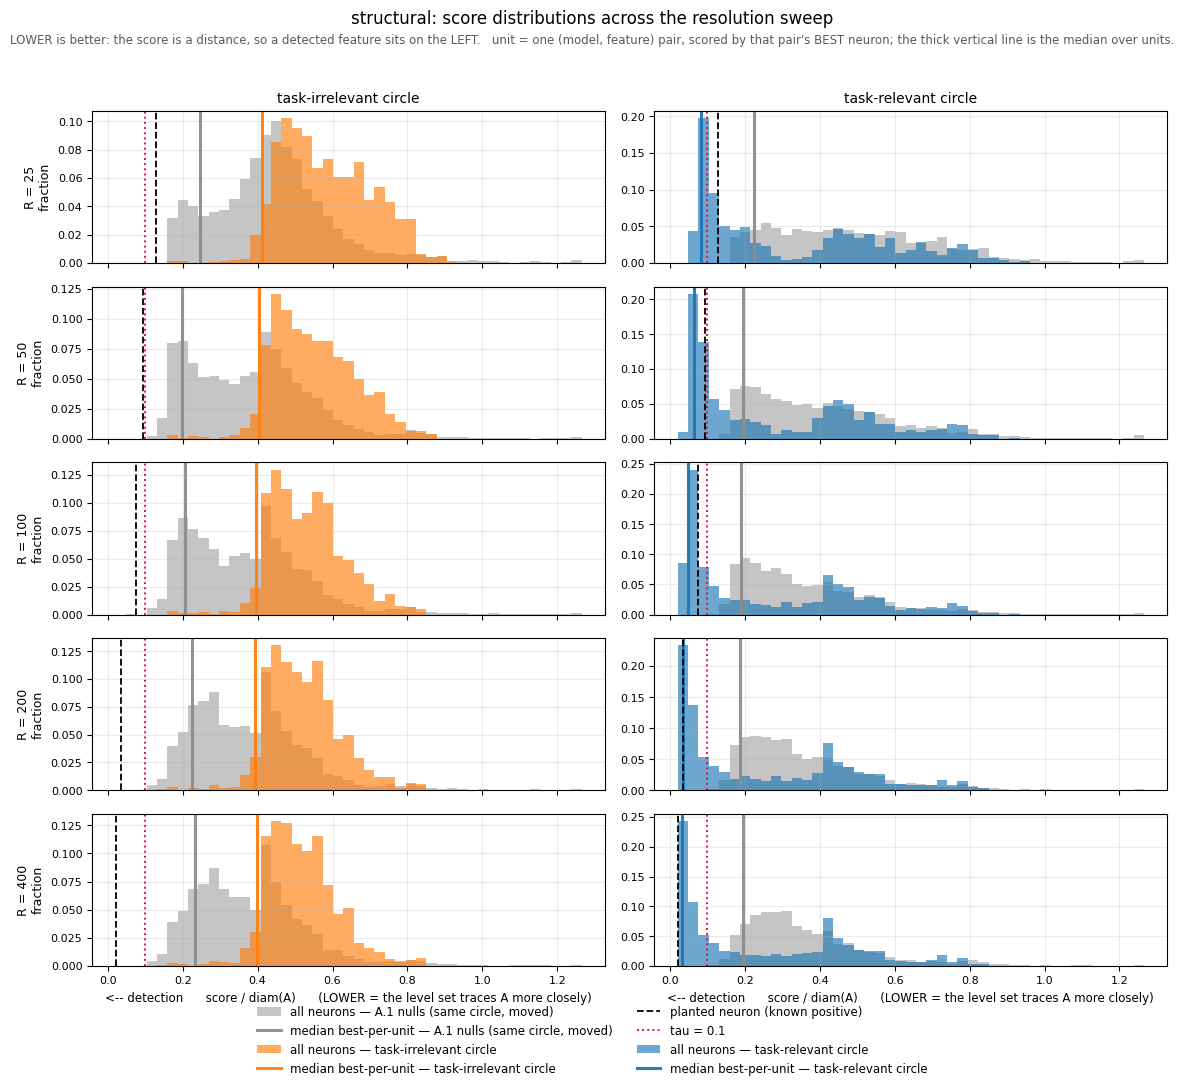

In [17]:
# ── 6. Двадцать распределений: 5 разрешений × 2 датасета × 2 критерия ────────
#     Строка — одно разрешение, столбец — одна задача. Серое — нули A.1,
#     цветное — цель; чёрный пунктир — подсаженный нейрон, малиновый — tau,
#     жирные вертикали — медиана лучшего нейрона на пару (модель, фича), то
#     есть единственная из трёх отметок, которой разрешено выносить вердикт.
#     Высота столбика — ДОЛЯ всех оценённых нейронов, а не плотность: критерий,
#     не вернувший числа (гомологический, NaN = не найдено ни одного бара
#     нужной размерности), показывает это недостающей площадью.
from visualization.calibration_plots import plot_sweep_distributions, plot_plateau_curves

if "df_A" not in globals():
    df_A = cal.read_scores_csv(PLANTED_CSV) if PLANTED_CSV.exists() else None

FIGDIR = Path("analysis/results/calibration/figures")
SAVE = False        # True — сохранить в FIGDIR вместо показа

plot_sweep_distributions(
    ens, "structural", planted=df_A, threshold=TAU,
    save_path=(FIGDIR / "sweep_dist_structural.png") if SAVE else None)

---
### Как устроен гомологический критерий и что значит 0 на его гистограмме

**Что фильтруется.** Надуровневые множества $\{f \ge c\}$. Уровень $c$ едет сверху вниз:
при $c=\max f$ множество пусто, при $c=\min f$ — это всё окно. По дороге в нём появляются
и заплывают дырки. Петля (класс $H_1$) *рождается* на уровне $b$ и *умирает* на уровне
$d<b$; её персистентность $p=b-d$ — это **ширина интервала уровней, на котором дырка
существует**.

**На чём это считается.** Не на континууме, а на конечном облаке:

* точки — те же точки поля, что у структурного критерия, но обрезанные окном радиуса
  `neighborhood_factor` = 1.5 × радиус фичи вокруг её центроида (чтобы петля где-то в
  другом конце бокса не засчиталась за эту фичу), и при переполнении прорежённые
  случайной подвыборкой до `max_sample_points` = 4000 с `seed = 0`;
* комплекс — Делоне (альфа-комплекс, `backend="delaunay"`), построенный по одной только
  геометрии точек;
* фильтрация — lower-star для $-f$: каждому симплексу приписывается максимум $-f$ по его
  вершинам. Это в точности надуровневая фильтрация $f$;
* считаются **обе ориентации**, $f$ и $-f$, и берётся лучшая: кольцо бывает гребнем
  (дырка в $\{f\ge c\}$) и краем ямы (дырка в $\{-f\ge c\}$);
* бесконечные бары обрезаются нижним просканированным уровнем.

**Как бар превращается в вердикт.** Для окружности требуется `feature_homology = {1: 1}`
— одна петля в размерности 1. Дальше (`analysis/homological.py:297`):

1. отсортировать бары размерности 1 по персистентности;
2. $p_k$ — самый длинный, $p_{\text{next}}$ — следующий, «шумовой»;
3. `floor` = `relative_floor` × (max f − min f) по выборке, при
   `relative_floor = 0.1` это 10 % размаха поля в окне;
4. **свидетель**, если выполнено всё сразу: $p_k>0$; $p_k \ge 2p_{\text{next}}$ (или
   второго бара нет); $p_k \ge \text{floor}$;
5. **margin** $= p_k - \max(p_{\text{next}},\ \text{floor})$ — это и есть скор на
   гистограмме.

Правило читается так: главная петля обязана быть **вдвое длиннее ближайшей конкурентки**
и **не короче 10 % размаха поля**. Первое отсекает «две одинаковые шумовые дырки», второе
— «все дырки крошечные».

**Что значит 0 на картинке.** Ноль — это в точности граница решения: главный бар ровно
такой же длины, как то из двух препятствий, которое больше. Справа от нуля бар длиннее
препятствия, слева короче.

Строго говоря, $\text{margin}\ge 0$ необходимо, но не достаточно: тест на двукратное
превосходство в margin не закодирован, и в принципе бывает $\text{margin}>0$ без вердикта
(когда $p_{\text{next}}>\text{floor}$, а $p_k$ лежит между $p_{\text{next}}$ и
$2p_{\text{next}}$). **На этих данных такого нет ни разу:** из 9614 строк с посчитанным
margin все 3334 с $\text{margin}\ge 0$ — свидетели, и все 6280 с $\text{margin}<0$ — нет.
Причина в том, что связывает здесь `floor` (≈ 0.18 при размахе ≈ 1.84), а второй бар
почти всегда крошечный: в окне радиуса 1.5·r_A физически помещается одна петля, а не две
сравнимые. Так что на этих гистограммах **знак margin и есть вердикт**.

**Пустое место — это не ноль.** Если бара нужной размерности не нашлось вообще, margin =
NaN, а не 0: «диаграмма пуста» и «бар был, но проиграл» — разные факты, и второй даёт
отрицательный margin. Столбики нормированы на **все** оценённые нейроны, поэтому
недостающая площадь и есть доля нейронов без бара, а её процент подписан в углу панели.

#### Почему у многих нейронов margin больше, чем у подсаженного

Коротко: **margin меряет контраст, а не геометрию, а подсаженный нейрон намеренно
построен тихим.**

* margin выражен в единицах значений самого нейрона. Для post-tanh $f\in[-1,1]$, значит
  шкала от 0 до 2. **Размер петли в margin не входит вовсе**: большая окружность не живёт
  дольше маленькой. Дольше живёт более резкий и глубокий гребень.
* Подсаженный нейрон: бар от $f=0.760$ до $f=0.272$, длина 0.488, margin 0.412.
  `plant_radial_neuron` нормирует шапку так, что её максимум равен 1, и специально держит
  последующие tanh в линейном режиме — в докстринге прямо: насыщение «flattens the profile
  and washes the level sets out». Поле подсаженного нейрона доходит до ≈ 0.76, а не до ±1.
* Обученный нейрон насыщен. У 835 relevant-нейронов с найденным баром при R = 200 медиана
  рождения 0.185, медиана смерти −0.814, медиана длины 0.823, максимум 1.945: кольцо
  выживает от «почти +1» до «почти −1».
* Крутить `sharpness` бесполезно: margin упирается в 0.685 (0.253 / 0.412 / 0.662 / 0.685
  / 0.685 при sharpness 1 / 2 / 4 / 8 / 16), а структурный скор при этом только портится,
  с 0.034 до 0.064 — слишком резкий край делает гребень тоньше сетки.

Отсюда правило чтения, уже сформулированное ниже в разделе «Чего из этих чисел читать
нельзя» → «Две разные роли подсаженного нейрона»: **для структурного критерия чёрная
линия — потолок, для гомологического — просто известный положительный.** «Правее чёрной
линии» на гомологической панели не означает «лучше идеала».

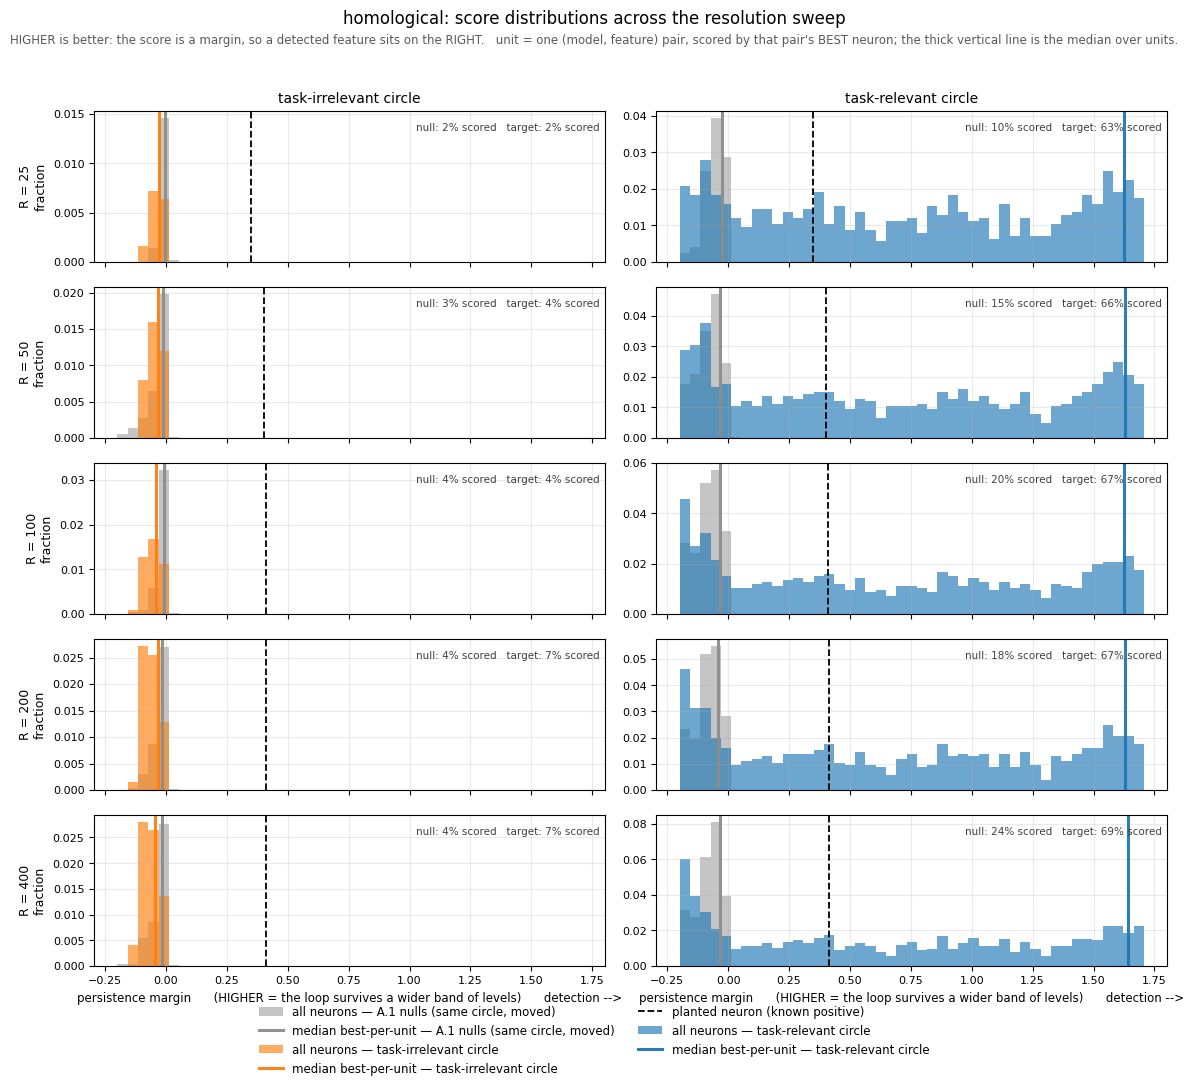

In [18]:
plot_sweep_distributions(
    ens, "homological", planted=df_A,
    save_path=(FIGDIR / "sweep_dist_homological.png") if SAVE else None)

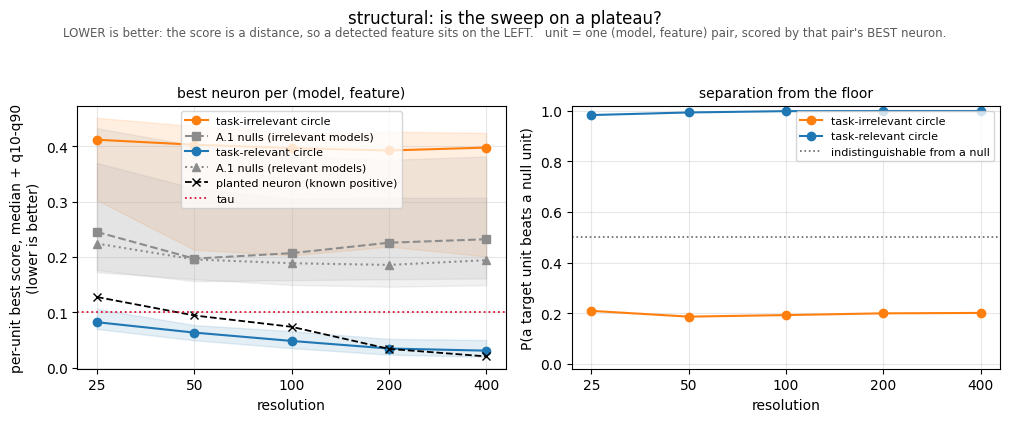

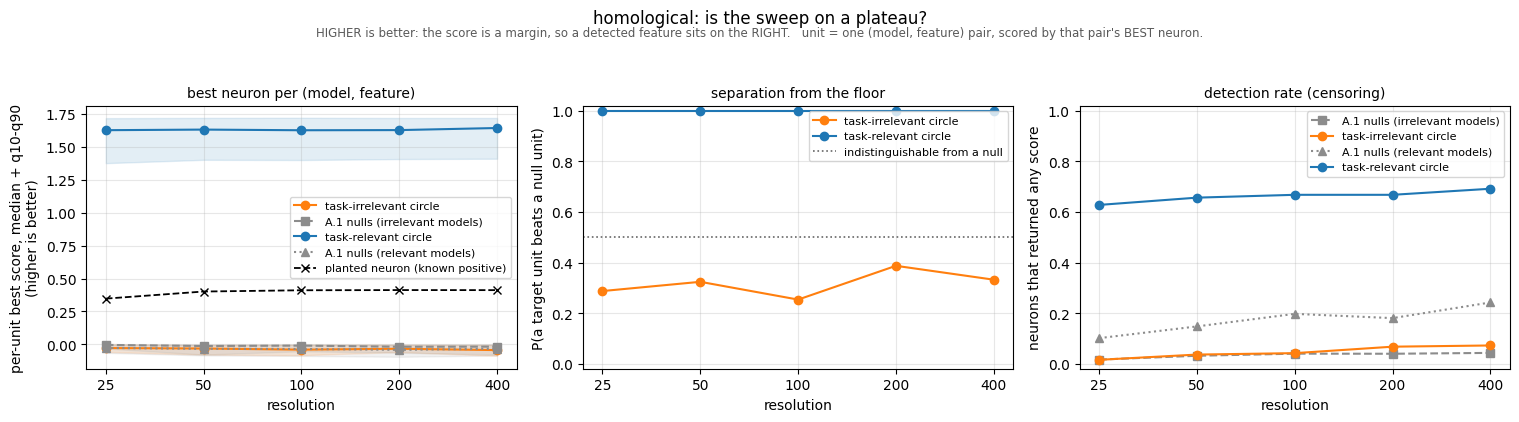

In [19]:
# ── 7. Тот же свип, свёрнутый к тому, из чего читается плато ─────────────────
#     Слева: лучший нейрон на пару (модель, фича), медиана и полоса q10–q90,
#     рядом — подсаженный нейрон. Кривая цели, падающая ВМЕСТЕ с подсаженной,
#     не улучшается: она идёт вниз за собственными накладными расходами
#     инструмента. В середине: P(цель обходит нуль) — вердикт без единиц
#     измерения, и именно он обязан перестать двигаться. Справа (когда есть
#     цензурирование): доля нейронов, для которых критерий вообще вернул число.
plot_plateau_curves(ens, "structural", planted=df_A, threshold=TAU, contrast=contrast,
                    save_path=(FIGDIR / "sweep_plateau_structural.png") if SAVE else None)
plot_plateau_curves(ens, "homological", planted=df_A, contrast=contrast,
                    save_path=(FIGDIR / "sweep_plateau_homological.png") if SAVE else None)

---
### Итоги свипа по resolution

Пять разрешений × два датасета × два критерия, 50 моделей на датасет, 25 нейронов на модель,
5 фич (цель + 4 нуля A.1) — 125 000 строк в `analysis/results/calibration/sanity_resolution_sweep.csv`,
сводки в `sanity_resolution_summary.csv` и `sanity_resolution_contrast.csv`.

**Единица наблюдения** здесь и всюду ниже — пара *(модель, фича)*, а её значение — лучший нейрон
этой пары. Не доля свидетелей: она наследует множественность, растущую с шириной сети по
построению. И не «лучший из всех нулей»: у цели одна фича, у пола — четыре размещения, и общий
минимум дал бы полу четырёхкратную множественность, которой у цели нет.

#### 1. Ответ эксперимента от разрешения не зависит

Окружность в обоих датасетах побитово одна и та же, различается только задача. Доля моделей,
у которых есть нейрон-свидетель при τ = 0.1:

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| task-relevant | 0.86 | 0.92 | 0.96 | **0.98** | 0.98 |
| task-irrelevant | 0.00 | 0.00 | 0.00 | **0.00** | 0.00 |
| нули A.1, relevant (200 единиц) | 0.000 | 0.000 | 0.000 | **0.000** | 0.000 |
| нули A.1, irrelevant (200 единиц) | 0.000 | 0.000 | 0.005 | **0.005** | 0.005 |

49 моделей из 50 против 0 из 50 — на одной и той же фиче. Ложных положительных на нулях: ни
одного из 200 на relevant при любом R, и ровно один из 200 на irrelevant при R ≥ 100. Вывод
держится даже при заведомо грубом R = 25.

Запас у обоих краёв большой, это не пограничный результат. Лучший нейрон **во всём**
irrelevant-ансамбле (1250 нейронов) при R = 200 набирает 0.1547 — это в полтора раза выше τ.
Единственная relevant-модель, не давшая свидетеля при R ≥ 200, — `model21` (0.1304), она
разобрана в «Песочнице» в конце ноутбука.

#### 2. Плато вердикта — с R = 100

`p_superior` = P(случайная целевая единица обходит случайную нулевую), величина без единиц
измерения, поэтому именно она обязана перестать двигаться:

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| relevant | 0.9835 | 0.9938 | 0.9990 | 0.9995 | 0.9995 |
| шаг \|Δ\| | — | 0.0103 | 0.0052 | 0.0005 | 0.0000 |
| irrelevant | 0.2089 | 0.1861 | 0.1922 | 0.1991 | 0.2007 |
| шаг \|Δ\| | — | 0.0228 | 0.0061 | 0.0069 | 0.0016 |

При допуске 0.01 первый уложившийся в него шаг — переход 50 → 100, и все последующие тоже.
Плато установлено начиная с **R = 100**, на обоих датасетах.

Доля свидетелей при τ ведёт себя грубее: её зернистость — 1/50 = 0.02, то есть один шаг это
одна модель. От R = 100 к R = 200 меняет вердикт ровно одна модель (`model7`, скор 0.1088 —
впритык к порогу), а от 200 к 400 — ни одной. Допуск 0.01 к этой величине неприменим, он
меньше её зерна; правильная формулировка — **при R ≥ 200 не проходит τ ровно одна модель, и
это устойчиво**.

#### 3. Гомологический критерий на плато сразу — но по другой причине

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| best margin, relevant / цель | 1.6266 | 1.6311 | 1.6261 | 1.6273 | 1.6431 |
| best margin, relevant / нули | −0.0269 | −0.0339 | −0.0349 | −0.0416 | −0.0333 |
| `p_superior`, relevant | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| `p_superior`, irrelevant | 0.2873 | 0.3238 | 0.2535 | 0.3871 | 0.3322 |

Медиана лучшего margin гуляет на 0.016 при отрыве цели от нулей 1.67 — около 1 %. Устойчивость
не случайна: концы бара — это **значения функции** (рождение ≈ +0.2, смерть ≈ −0.8 у насыщенного
tanh), а не свойства сетки. Как только облако вообще разрешает кольцо, добавление точек бар не
удлиняет.

### Чего из этих чисел читать нельзя

#### Абсолютный скор цели — не измерение сети

Подсаженный нейрон — окружность нужного радиуса в нужном месте; её истинная геометрическая
ошибка `ideal_score = 0.0016`, то есть практически ноль. Всё, что он набирает, есть накладные
расходы самого инструмента:

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| подсаженный (истина ≈ 0) | 0.1278 | 0.0946 | 0.0741 | **0.0343** | 0.0207 |
| медиана цели, relevant | 0.0824 | 0.0637 | 0.0486 | **0.0349** | 0.0311 |

При R = 200 цель стоит ровно на потолке инструмента: 0.0349 против 0.0343. При R = 400 инструмент
опускается до 0.0207, а цель — только до 0.0311; подсаженный падает примерно как R^−0.67, цель —
как R^−0.35. Собственная геометрическая ошибка нейронов не разрешена ни при одном разрешении
свипа. **Поэтому отчитываться надо контрастом (`gap`, `p_superior`), а не абсолютным скором
цели**; если абсолютное число всё же нужно, рядом обязана стоять строка подсаженного нейрона при
том же R.

#### Две разные роли подсаженного нейрона

* **structural — это потолок.** Правильный ответ известен и равен нулю, значит измеренное
  значение целиком есть разрешающая способность инструмента. Ничего осмысленного ниже этой
  линии оказаться не может, и разность «цель − подсаженный» — это то, что вообще можно
  приписать сети.
* **homological — это НЕ потолок, а «известный положительный, но тихий».** Margin меряется в
  единицах значений самого нейрона и равен ширине интервала уровней, на котором кольцо выживает,
  то есть **контрасту**, а не геометрии. Размер петли в него не входит вовсе: большие окружности
  не живут дольше. `plant_radial_neuron` по построению держит последующие tanh в линейном режиме
  (поле подсаженного доходит до ≈ 0.76, а не до ±1) — отсюда его margin 0.41 против 1.63 у
  насыщенного обученного нейрона. Обученные нейроны обходят подсаженный не потому, что они
  «лучше идеала», а потому, что они громче. Крутить `sharpness` бесполезно: margin упирается в
  0.685, а structural при этом только портится (0.034 → 0.064).

#### Пол шкалы не плоский — и это самая подвижная часть измерения

Медиана лучшего по единице, R = 200, irrelevant:

| размещение | `far_right` | `on_blue_disk` | `above_target` | `in_between` |
|---|---|---|---|---|
| медиана | 0.1764 | 0.2044 | 0.2590 | 0.3675 |

Одна и та же окружность даёт от 0.176 до 0.368 в зависимости только от того, куда её положили.
Разброс 0.19 больше самого `gap` (0.166). Поэтому вердикт обязан перебивать **самое мягкое**
размещение — `gap_vs_softest` = 0.130 для relevant при R = 200, — а не пул.

Пол при этом и есть наименее устойчивая часть измерения: пулированная медиана нулей на
irrelevant делает шаг 0.019 на переходе 100 → 200 и правилу «два подряд шага меньше 0.01» не
удовлетворяет, а отдельные размещения гуляют по R на 0.010–0.026 (максимум — `on_blue_disk`,
0.1780 → 0.2044). Это 10–26 % от τ. Вердикту не угрожает (gap 0.15), но **число пола всегда
надо приводить вместе с его разрешением**.

#### Detection rate гомологического критерия отчитывать нельзя ни при каком R

`resolution` для этого критерия — не дискретизация, а прокси размера выборки, и он насыщается:
`neighborhood_factor = 1.5` оставляет окно радиуса 1.5·r_A (≈ 15 % бокса), а
`max_sample_points = 4000` режет остаток случайной подвыборкой.

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| точек в фильтрации | 89 | 371 | 1515 | 4000 | 4000 |
| точек в сетке всего | 625 | 2 500 | 10 000 | 40 000 | 160 000 |

Выше R ≈ 160 меняется не разрешение, а то, какие именно 4000 точек вытянул `seed = 0` — один и
тот же для всех 50 моделей, поэтому его ошибка не усредняется по ансамблю.

Проверено отдельными прогонами (R = 200, 5–8 моделей, все нейроны, цель + `null_in_between`; в
ноутбук не входят): смена только `seed` двигает detection rate нулей с 0.128 до 0.240, а полное
снятие подвыборки (`max_sample_points = 7000`, все ≈ 6100 точек окна) — с 0.150 до 0.280. При
этом медиана лучшего margin цели двигается на 0.003, нулей на 0.001, и `p_superior` остаётся
1.0000 в обоих случаях.

Смысл: **счётчики событий на пороге неустойчивы, а вердикт — нет.** У нуля поле почти плоское, и
«появился ли вообще бар длиннее 0.1 размаха и вдвое длиннее следующего» решается на грани. У цели
кольцо — грубая черта функции, и его бар сошёлся давно. Если нужна «доля обнаружений», берите её
на уровне единиц: у цели она 1.000 при всех R.

### Решение: `resolution = 200`

| | R = 100 | **R = 200** | R = 400 |
|---|---|---|---|
| `p_superior`, relevant | 0.9990 | **0.9995** | 0.9995 |
| моделей не прошло τ (из 50) | 2 | **1** | 1 |
| пол, медиана нулей (relevant) | 0.1889 | 0.1858 | 0.1943 |
| structural, время на оба датасета | 1 663 c | **6 834 c** | 17 320 c |
| гомология: точек в окне / кэп 4000 | 1 515 / не режет | 6 107 / режет | 24 482 / режет |

R = 200 — наименьшее разрешение, при котором успокоились **обе** отчётные величины: `p_superior`
(с R = 100) и число не прошедших τ моделей (с R = 200). R = 400 стоит в 2.5 раза дороже и не
покупает ничего: `p_superior` +0.0000, моделей ±0, пол +0.009.

Вместе с этим в спек стоит поставить **`max_sample_points = 7000`** для гомологического критерия:

```python
extra_criteria_kwargs={"homological": {"backend": "delaunay", "max_sample_points": 7000}}
```

Это не исправление ошибки — измерено, что вердикт от такой замены не меняется, — а устранение
произвольной константы: при 4000 ответ зависит от одного фиксированного розыгрыша, при 7000
розыгрыша нет вообще (в окне ≈ 6100 точек). Цена ×1.6 по времени. **Пересчитывать свип не нужно:**
всё, что будет отчитываться, уже измерено и устойчиво.

#### Что остаётся открытым

`n_levels` — единственный ещё не зафиксированный гиперпараметр. Он касается **только структурного
критерия** (у гомологического дискретизации по уровню нет вообще) и не независим от ε: адаптивный
ε отсекается снизу величиной `0.5 · range(f)/(n_levels − 1)`, а сам он падает как 1/R. При R = 200
эта отсечка уже определяет ε примерно у трети нулевых нейронов, но ещё не у цели, — то есть
изменение `n_levels` двигает прежде всего **пол шкалы**. Следующая секция про это.

### Наблюдения по данным (мои) и разбор

> **для структурного скора:**
>
> 1) на релевантной фиче распределение бимодально, при чём одна мода явно детектирует фичу, а вторая повторяет распределение irrelevant фичи
> 2) на irrelevant датасете распределение на null-фиче бимодально - из-за того, что мы видим усреднённую по 4 фичам картину - просто на каких-то из них значения выше, а где-то ниже. При чём бимодальность начинает прослеживаться при увеличении разрешения
> 3) оказывается, что \tau=0.1 порога выбран хорошо — никто, или почти никто из нулевых и нерелвантных фичей не зажигает этот критерий, при этом почти в каждом из релевантных случаев он зажигается (находится хоть кто-то, кто зажигает). При этом есть два исключения: нашлась модель, которая зажигает нерелевантную / нуль-фичу, и, наоборот, где релевантная фича не зажгла критерий
>
> **Дальше конкретно про sweep по resolution:**
> (как для task-relevant, так и для task-irrelevant)
>
> 4) даже на самом низком разрешении нижняя граница structural скора на null-features находится в промежутке [0.1, 0.15], увеличение разрешения двигает её лишь при переходе с 25 к 50, далее значение не меняется.
> 5) значение же, посчитанное на planted neuron уменьшается в каждый раз при увеличении разрешения. В частности, при R=25 он вообще не детектируется, при R=50 едва заходит в детектируемую область, и лишь начиная с R=200 добирает достаточный margin по сравнению с минимальными значениями скора на null-features.
>
> **на task-relevant датасете**
>
> 6) значения скора на релевантной фиче приближаются к 0.025 уже начиная с разрешения R=50, но большая доля нейронов приобретают столь низкие значения также на разрешении R=200.

---

**(1) Согласен, и уточнение оказывается содержательным.** Бимодальность есть: при R = 200 доля
relevant-нейронов ниже 0.1 равна 0.42, остальные образуют вторую моду. Но вторая мода
irrelevant-распределение **не повторяет, а сдвинута ниже него**: медиана верхней моды (нейроны
со скором > 0.2) равна 0.443 против 0.513 у task-irrelevant цели. Разница 0.07 держится на всех
разрешениях (R = 50: 0.477 против 0.537; R = 400: 0.442 против 0.507).

Читается это так: даже «недетектирующие» нейроны релевантной сети систематически ближе к
окружности, чем любые нейроны нерелевантной. То есть task-relevance видна не только в лучшем
нейроне, но и во всей популяции — слабее, но видна. Это **новая информация**, я на неё не
смотрел. Как отдельный вердикт её брать нельзя (популяционная статистика возвращает ту самую
множественность, ради ухода от которой введена единица «модель × фича»), но как независимое
подтверждающее наблюдение она хороша, и это готовый кандидат в отдельный анализ.

**(2) Согласен, и механизм именно тот, что вы назвали.** Медианы по размещениям на уровне
нейронов, irrelevant, R = 200: `far_right` 0.280, `on_blue_disk` 0.271, `above_target` 0.372,
`in_between` 0.480. Четыре размещения группируются в две кучки (≈ 0.27 и ≈ 0.37–0.48), их смесь и
даёт две моды.

Про «бимодальность проявляется с ростом разрешения» — тоже верно, и причина не в том, что моды
разъезжаются, а в том, что **они сужаются**. Центры после R = 50 стоят на месте, а
внутригрупповой IQR падает: `on_blue_disk` 0.208 → 0.128, `far_right` 0.220 → 0.183 от R = 25 к
R = 400. Компоненты смеси становятся у́же при неподвижных центрах — смесь и начинает выглядеть
двугорбой. Это тоже **новая информация**: на внутригрупповой разброс я не смотрел.

**(3) Согласен, это ровно то, что измерено, — с одним уточнением по адресу.** Ложное
срабатывание одно, и оно на **null-фиче** (`model24`, L1n4, `null_above_target`), а не на
task-irrelevant цели: ни один нейрон нерелевантного ансамбля не пересёк τ ни при одном
разрешении. Обратное исключение — `model21`. Оба разобраны в «Песочнице».

Добавлю то, чего в наблюдении нет: запас сверху не огромный. Лучший нейрон **из всех 1250**
нерелевантного ансамбля при R = 200 набирает 0.1547, то есть τ = 0.1 отстоит от него всего на
55 %.

**(4) Согласен наполовину, и вторая половина важна.** Минимум по всем нейронам:

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| нули, **relevant** | 0.1476 | 0.1258 | 0.1187 | 0.1144 | 0.1093 |
| нули, **irrelevant** | 0.1591 | 0.1205 | **0.0734** | 0.0667 | 0.0673 |

Для relevant всё как вы говорите: диапазон [0.11, 0.15], основной шаг на переходе 25 → 50,
дальше почти не движется. Для **irrelevant это не так**: минимум уходит ниже 0.1, и главный шаг
приходится на **50 → 100** (0.121 → 0.073), а не на 25 → 50.

И это не мелочь: **ложное срабатывание порождено разрешением.** При R = 25 и R = 50 ложных
срабатываний на нулях ноль, начиная с R = 100 — ровно одно, и появляется оно именно потому, что
нижний край нулевого распределения на irrelevant проваливается ниже τ на этом шаге.

Из этого **не следует**, что грубое разрешение лучше: при R = 50 доля relevant-моделей со
свидетелем 0.92 против 0.98, то есть цена одного не-ложного срабатывания — три лишних пропуска.
Грубое разрешение не чище, оно слепее.

**(5) Согласен полностью, и это аргумент, которого у меня не было.** Подсаженный нейрон против
минимума по нулям (irrelevant):

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| подсаженный | 0.1278 | 0.0946 | 0.0741 | **0.0343** | 0.0207 |
| свидетель при τ? | **нет** | да | да | да | да |
| минимум по нулям | 0.1591 | 0.1205 | 0.0734 | 0.0667 | 0.0673 |

При R = 25 инструмент **не может подтвердить геометрически идеального свидетеля** — это,
пожалуй, самый жёсткий калибровочный факт всего свипа. При R = 100 подсаженный нейрон (0.0741)
и лучший нуль (0.0734) идут **вровень**: инструмент в этой точке не отличает идеал от лучшего
совпадения. И только при R = 200 появляется двукратный отрыв, при R = 400 — трёхкратный.

Это независимое основание для R ≥ 200, которого в моём разборе не было: я обосновывал выбор
плато вердикта и стабильностью доли свидетелей, а «когда потолок инструмента отрывается от
лучшего нуля» — отдельный и более строгий критерий, и он даёт ту же цифру.

**(6) Согласен по сути, цифра сдвинута на один шаг.** Минимум по relevant-цели: 0.0613 (R = 25),
0.0429 (50), 0.0272 (100), 0.0165 (200), 0.0117 (400) — к 0.025 он подходит на **R = 100**, а не
на R = 50. Про массу вы правы точно:

| доля relevant-нейронов | R=25 | R=50 | R=100 | R=200 | R=400 |
|---|---|---|---|---|---|
| со скором < 0.025 | 0.000 | 0.000 | 0.000 | 0.015 | 0.046 |
| со скором < 0.05 | 0.000 | 0.014 | 0.098 | **0.254** | 0.273 |
| со скором < 0.1 | 0.229 | 0.346 | 0.397 | **0.419** | 0.419 |

Масса очень низких значений появляется только к R = 200 и там же выходит на плато (0.254 → 0.273
и 0.419 → 0.419). До R = 100 отдельные нейроны уже опускаются низко, но популяции там ещё нет.

---

#### Что это меняет в выводах свипа по resolution

**Выбор R = 200 не меняется — он усиливается, причём двумя независимыми доводами.** Ваш пункт 5
даёт критерий, которого у меня не было: отрыв потолка инструмента от лучшего нуля появляется
именно при R = 200 (двукратный), тогда как при R = 100 они идут вровень. Пункт 6 даёт второй:
популяция низкоскоровых relevant-нейронов формируется и выходит на плато тоже к R = 200.
Раньше R = 200 выбирался по стабильности доли свидетелей, а плато `p_superior` наступало уже при
R = 100 — теперь видно, что R = 100 недостаточен по существу, а не только по осторожности.

**Одна формулировка требует поправки.** «Плато вердикта с R = 100» надо читать с сноской: на том
же шаге 50 → 100 появляется единственное ложное срабатывание, потому что нижний край нулевого
распределения на irrelevant проваливается с 0.121 до 0.073. `p_superior` этого не замечает — он
про типичную единицу, а не про хвост.

**Заголовочный результат не затронут.** 49 моделей из 50 против 0 из 50, `p_superior` 0.9995
против 0.199, один ложный положительный на 200 нулевых единиц — всё это остаётся.

**Появился кандидат в отдельный анализ:** сдвиг всей популяции relevant-нейронов относительно
irrelevant (пункт 1), а не только её лучшего представителя.

---
## 2. Свип по `n_levels`

`n_levels` — последний незафиксированный параметр структурного критерия: сколько уровней `c`
перебирается между `min f` и `max f`. Гомологический критерий уровни не перебирает вовсе
(фильтрация непрерывна), поэтому свип касается **только структурного**.

`level_eps` в свип **не входит**: он остаётся `"adaptive"`, это решение принято и не
пересматривается. Независимым он от этого не становится — нижняя отсечка адаптивного ε равна
половине шага по уровню, то есть `n_levels` двигает ε сам, и ровно у тех нейронов, что в отсечку
упёрлись. Поэтому свип по одному `n_levels` и есть тот самый совместный свип, только вдоль
единственной оси, по которой мы вправе двигаться; колонка `eps_clamped` показывает, для кого он
оказался свипом по ε.

Остальное зафиксировано: `resolution = 200` (свип выше), сетка уровней — наблюдённый размах
нейрона, бокс тот же самый. Нули — те же четыре размещения, но в свип берутся два из них,
самое мягкое и самое жёсткое (почему — ниже).


### Что именно нужно от этого свипа

`n_levels` — последний незафиксированный гиперпараметр. Он касается **только структурного
критерия**: у гомологического дискретизации по уровню нет, фильтрация непрерывна.

**Конвенция сетки уровней зафиксирована** (`CALIBRATION.md`, `docs/explanation.md`): уровни
берутся по наблюдённому размаху нейрона, `linspace(min f, max f, n_levels)`, то есть
`activation=None` в `structural_kwargs` — теперь это значение по умолчанию во всех спеках.
Отсюда шаг по уровню равен `range(f)/(n_levels − 1)`, а нижняя отсечка адаптивного ε —
`range(f)/(2·(n_levels − 1))`, обе **свои у каждого нейрона**.

#### Чего ожидать, и в чём подвох

Скор — это минимум по уровням, а сетки вложены точно (`linspace(a, b, 201)` содержит
`linspace(a, b, 101)`, и так далее для 51 и 26). **При фиксированном ε больше уровней могут
только понизить скор.** Но ε не фиксирован: с ростом `n_levels` отсечка падает, и у тех нейронов,
что в неё упёрлись, ε уменьшается вместе с ней. При R = 200 это ≈ 32 % нулевых нейронов и ≈ 1 %
целевых.

Значит движение будет разным по популяциям:

* **цель** уже стоит на потолке инструмента (0.0349 против 0.0343 у подсаженного нейрона), ей
  улучшаться некуда — её ε задаётся полем, монотонность работает, но упирается;
* **нули** имеют запас (0.186) и у трети из них ε поедет вместе с отсечкой — направление не
  гарантировано.

Отсюда главный риск и главный вопрос свипа: **лишние уровни могут только опускать скоры, а
опускать есть куда только у нулей и у нерелевантной цели.** То есть `n_levels` — это в первую
очередь стресс-тест на ложные срабатывания, а не настройка чувствительности. Запас сейчас:
лучший нейрон нерелевантного ансамбля 0.1547 при τ = 0.1, а нижний край нулей на irrelevant уже
и так провалился до 0.0667 (одно срабатывание). Если он поедет дальше — заголовочный результат
поедет вместе с ним.

#### Конфигурация

| | |
|---|---|
| разрешение | **200**, зафиксировано |
| `level_eps` | `"adaptive"`, не трогаем |
| сетка уровней | наблюдённый размах (по умолчанию) |
| `n_levels` | **{6, 26, 51, 101, 201, 401}** — вложенная цепочка целиком |
| выборка | **35 моделей × 5 фич × 25 нейронов на обоих датасетах** |
| `n_levels = 101` | **не считается**: это в точности конфигурация свипа по resolution при R = 200 |
| критерий | только structural |

* `{6, 26, 51, 101, 201, 401}` — точные вложенные подмножества одной сетки (шаги
  5 ⊂ 25 ⊂ 50 ⊂ 100 ⊂ 200 ⊂ 400), поэтому «больше уровней» означает буквально «те же уровни
  плюс новые». Нижний конец 6 нужен затем же, зачем в прошлом свипе был R = 25: показать, что
  у кривой вообще есть форма, а не только хвост.
* 401 не опция, а условие вычислимости вывода: правило плато требует **двух** подряд шагов
  меньше допуска, причём последний интервал обязан быть одним из них. Без 401 можно подтвердить
  плато самое позднее на 101, но не на 201.
* Форма выборки — та же, что у свипа по resolution (модели × 5 фич × 25 нейронов на обоих
  датасетах). Это не роскошь, а то, что делает столбец `n_levels = 101` бесплатным: он там уже
  посчитан, побитово в этой же конфигурации. Заодно пол получает всю свою ширину из четырёх
  размещений на обеих задачах, а не два размещения на одной.
* 35 моделей — это ручка бюджета, и единственная. Сравнение парное (набор моделей один и тот же
  в каждой ячейке), поэтому читается смещение, а не уровень, и 35 моделей × 25 нейронов хватает
  и медиане, и минимуму. Меньше моделей — короче прогон, прямо пропорционально.
* Дополнительная колонка `floor = 0.5·(max f − min f)/(n_levels − 1)` и флаг
  `best_level_eps == floor`: без неё нельзя отличить движение от плотности уровней от движения
  от ε.

Стоимость известна точно, а не оценена: полный проход при `n_levels = 101` и R = 200
(50 моделей × 5 фич × 2 датасета) уже сделан и занял **113.9 минуты** по сумме колонки
`seconds`. Всё остальное — пропорция: время ≈ 1.9 ч × (n_levels/101) × (моделей/50).

| моделей | вся цепочка, 101 переиспользован | из них 401 |
|---|---|---|
| 50 | 12.9 ч | 7.5 ч |
| 40 | 10.3 ч | 6.0 ч |
| **35** | **9.0 ч** | 5.3 ч |
| 30 | 7.7 ч | 4.5 ч |

Цикл идёт по возрастанию `n_levels`, поэтому всё, кроме 401, ложится на диск за первые ≈ 3.7 ч,
и прерванный прогон теряет только хвост. Механика частичных сохранений — та же, что в свипе по
resolution: каждая пара (`n_levels`, датасет) сохраняется сразу после подсчёта.

#### Как читать результат

1. **Жёсткая защита, смотреть первой:** минимум скора по всем нейронам нерелевантной цели и по
  всем нулям обеих задач. Если он подходит к 0.1 — останавливаемся на предыдущем `n_levels`,
  независимо от того, что показывает `gap`.
2. **Основное:** `p_superior` и `gap` с допуском 0.01. Плато — два подряд шага меньше допуска,
  причём последний интервал обязан быть одним из них.
3. **Атрибуция:** доля строк с активной отсечкой. Мала — двигалась плотность уровней; велика —
  двигался ε.
4. **Выбор:** наименьший `n_levels`, при котором `p_superior` и `gap` уже в пределах допуска от
  значений на максимальном протестированном, и минимум по irrelevant не приблизился к τ.

In [20]:
# ── 8. Конфигурация свипа по n_levels ────────────────────────────────────────
#     Меняется ОДИН параметр. resolution = 200 и сетка уровней по наблюдённому
#     размаху зафиксированы выше, level_eps остаётся "adaptive".
from dataclasses import replace

# Вложенная цепочка целиком: шаги 5 ⊂ 25 ⊂ 50 ⊂ 100 ⊂ 200 ⊂ 400, то есть
# «больше уровней» = «те же уровни плюс новые». 401 не опция: правило плато
# требует двух подряд шагов под допуском, и без 401 плато на 201 непроверяемо.
N_LEVELS_GRID = [6, 26, 51, 101, 201, 401]
NL_RES        = REFERENCE_RES        # 200
NL_CRIT       = CRITS["structural"]  # гомологический критерий уровни не перебирает

# n_levels = 101 при R = 200 — это в точности конфигурация свипа по resolution
# (101 — дефолт structural_criterion, остальные kwargs те же), поэтому он не
# считается заново, а берётся из его part-файлов. Проверка совпадения — в
# ячейке 11, на трёх пересчитанных строках.
NL_REUSE       = {101}
NL_REUSE_PARTS = Path("analysis/results/calibration/sweep_parts")

# ЕДИНСТВЕННАЯ ручка бюджета. Время ≈ 1.9 ч × (n_levels/101) × (моделей/50),
# где 1.9 ч — ИЗМЕРЕННОЕ время полного прохода при n_levels = 101 (сумма
# колонки seconds свипа по resolution при R = 200). Вся цепочка с
# переиспользованным 101: 50 моделей → 12.9 ч, 40 → 10.3 ч, 35 → 9.0 ч,
# 30 → 7.7 ч. Сравнение парное (набор моделей один и тот же в каждой ячейке),
# поэтому число моделей меняет точность, но не смещает сравнение поперёк
# n_levels.
N_MODELS_NL = 50

# Форма выборки — та же, что у свипа по resolution: все фичи на обоих
# датасетах. Именно это делает столбец n_levels = 101 бесплатным, и заодно
# даёт полу всю его ширину из четырёх размещений на обеих задачах.
NL_FEATURES = {tag: list(FEATURES[tag]) for tag in DATASETS}
NL_MODELS   = {tag: PATHS[tag][:N_MODELS_NL] for tag in DATASETS}

# Известный худший relevant-юнит (единственная модель, не прошедшая tau при
# R = 200) добавляется в выборку, если в первые N_MODELS_NL не попал: вопрос
# свипа — не уедет ли за tau именно край, а край должен быть в выборке, иначе
# колонка «худший юнит» пуста по построению. При N_MODELS_NL = 35 он входит и
# так, и блок ничего не делает; страховка нужна при меньшем числе моделей.
_ref = ens if "ens" in globals() else (          # свип по resolution: уже в памяти
    cal.read_scores_csv(SWEEP_CSV) if SWEEP_CSV.exists() else None)
if _ref is not None:
    _rel = _ref[(_ref.criterion == "structural") & (_ref.resolution == NL_RES)
                & (_ref.dataset == "relevant") & (_ref.role == "target")]
    _worst = (cal.best_per_unit(_rel, lower_is_better=True)
              .sort_values("best_score", ascending=False).iloc[0])
    if _worst.model_path not in NL_MODELS["relevant"]:
        NL_MODELS["relevant"] = NL_MODELS["relevant"] + [_worst.model_path]
        print(f"худший юнит при R={NL_RES} добавлен в выборку: "
              f"{Path(_worst.model_path).name} ({_worst.best_score:.4f})\n")

NL_FEAT = {tag: {k: FEATURES[tag][k] for k in names}
           for tag, names in NL_FEATURES.items()}

if "n_neurons" not in globals():        # если ячейка 2 в этот раз не запускалась
    _m, _ = load_model_instance(PATHS["relevant"][0])
    n_neurons = sum(_m.blocks[l].linear.out_features for l in range(_m.n_layers))

# Стоимость — из УЖЕ ЗАМЕРЕННОГО времени прошлого свипа (колонка seconds при
# R = 200, n_levels = 101), а не из нового пробного запуска: перебор уровней
# линеен по n_levels, поэтому множитель — отношение к 101.
_per_row = {}
for tag in NL_FEAT:
    _c = (_ref[(_ref.criterion == "structural") & (_ref.resolution == NL_RES)
               & (_ref.dataset == tag)] if _ref is not None else None)
    # СРЕДНЕЕ, а не медиана: полное время = строки × среднее по определению, а
    # у распределения времени тяжёлый правый хвост (relevant: медиана 0.57 с,
    # среднее 0.74). По медиане оценка занижена почти на 20 %.
    _per_row[tag] = float(_c["seconds"].mean()) if _c is not None and len(_c) else 0.5
_rows = {tag: len(NL_MODELS[tag]) * len(NL_FEAT[tag]) * n_neurons for tag in NL_FEAT}
_hour_at_101 = sum(_rows[tag] * _per_row[tag] for tag in NL_FEAT) / 3600

print(f"{sum(_rows.values())} строк на одно значение n_levels "
      f"({N_MODELS_NL} моделей × 5 фич × {n_neurons} нейронов × 2 датасета), "
      f"{_hour_at_101:.2f} ч при n_levels = 101")
_total = 0.0
for n in N_LEVELS_GRID:
    h = _hour_at_101 * n / 101
    if n in NL_REUSE:
        print(f"  n_levels={n:4d}: {h:5.2f} ч → переиспользуется из свипа по resolution")
    else:
        _total += h
        print(f"  n_levels={n:4d}: {h:5.2f} ч")
print(f"итого ≈ {_total:.1f} ч  (всё, кроме максимального n_levels, — за первые "
      f"{_total - _hour_at_101 * max(N_LEVELS_GRID) / 101:.1f} ч)")


12500 строк на одно значение n_levels (50 моделей × 5 фич × 25 нейронов × 2 датасета), 1.90 ч при n_levels = 101
  n_levels=   6:  0.11 ч
  n_levels=  26:  0.49 ч
  n_levels=  51:  0.96 ч
  n_levels= 101:  1.90 ч → переиспользуется из свипа по resolution
  n_levels= 201:  3.78 ч
  n_levels= 401:  7.53 ч
итого ≈ 12.9 ч  (всё, кроме максимального n_levels, — за первые 5.3 ч)


In [21]:
# ── 9. Размах поля каждого нейрона: то, из чего сделаны и уровни, и отсечка ──
#     Уровни = linspace(min f, max f, n_levels), значит шаг = range/(n_levels−1),
#     а нижняя отсечка адаптивного ε — половина шага. И то и другое СВОЁ у
#     каждого нейрона, поэтому без этой таблицы движение от плотности уровней
#     не отличить от движения от ε. Сетка ровно та же, что у критерия, так что
#     числа не «похожие», а те самые. Считается один раз (минуты), кладётся на
#     диск и переиспользуется.
from analysis.fields import evaluate_field_on_grid
from models.NN_analysis import get_hidden_dim

NL_RANGES_CSV = Path("analysis/results/calibration/sanity_nlevels_field_ranges.csv")

if NL_RANGES_CSV.exists():
    ranges = pd.read_csv(NL_RANGES_CSV)
    print(f"переиспользую {NL_RANGES_CSV} ({len(ranges)} нейронов)")
else:
    t0, rows = time.perf_counter(), []
    for tag, paths in NL_MODELS.items():
        for path in paths:
            model, _ = load_model_instance(path)
            for layer_id in range(model.n_layers):
                for coord_id in range(get_hidden_dim(model, layer_id)):
                    v = evaluate_field_on_grid(
                        cal.neuron_function(model, layer_id, coord_id),
                        bounds=BOUNDS, resolution=NL_RES).values
                    rows.append({"model_path": str(path), "dataset": tag,
                                 "layer_id": layer_id, "coord_id": coord_id,
                                 "field_min": float(v.min()),
                                 "field_max": float(v.max())})
    ranges = pd.DataFrame(rows)
    NL_RANGES_CSV.parent.mkdir(parents=True, exist_ok=True)
    ranges.to_csv(NL_RANGES_CSV, index=False)
    print(f"{len(ranges)} нейронов за {time.perf_counter() - t0:.0f} c → {NL_RANGES_CSV}")

ranges["field_range"] = ranges.field_max - ranges.field_min
display(ranges.groupby(["dataset", "layer_id"])[["field_min", "field_max", "field_range"]]
        .median().round(3))


переиспользую analysis/results/calibration/sanity_nlevels_field_ranges.csv (2500 нейронов)


field_min  field_max  field_range
dataset    layer_id                                   
irrelevant 0            -0.996      0.996        1.988
           1            -0.740      0.750        1.441
           2            -0.684      0.701        1.348
           3            -0.713      0.715        1.414
           4            -0.716      0.724        1.432
relevant   0            -1.000      1.000        2.000
           1            -0.879      0.842        1.704
           2            -0.777      0.779        1.453
           3            -0.914      0.916        1.768
           4            -0.978      0.972        1.936

In [22]:
# ── 10. A: подсаженный нейрон вдоль n_levels (секунды) ───────────────────────
#     Потолок инструмента: его истинная геометрическая ошибка ≈ 0
#     (ideal_score = 0.0016), поэтому его score — это накладные расходы самого
#     критерия при данном n_levels. Кривая цели, идущая вниз ВМЕСТЕ с ним, не
#     улучшается: она следует за инструментом.
NL_PLANTED_CSV = Path("analysis/results/calibration/sanity_nlevels_planted.csv")

if "planted" not in globals():          # если ячейка 3 в этот раз не запускалась
    probe_model, _ = load_model_instance(PATHS["relevant"][0])
    planted = cal.planted_probe(probe_model, FEATURES["relevant"]["relevant"],
                                layer_id=3, coord_id=0, name="planted")

if NL_PLANTED_CSV.exists():
    df_A_nl = cal.read_scores_csv(NL_PLANTED_CSV)
    print(f"переиспользую {NL_PLANTED_CSV}")
else:
    df_A_nl = cal.scan([planted], {"structural": NL_CRIT}, BOUNDS, NL_RES,
                       grid={"n_levels": N_LEVELS_GRID}, verbose=True)
    df_A_nl.to_csv(NL_PLANTED_CSV, index=False)

display(df_A_nl[["n_levels", "score", "ideal_score", "is_witness", "best_level_eps",
                 "best_adaptive_eps_quantile", "seconds"]].round(4))


переиспользую analysis/results/calibration/sanity_nlevels_planted.csv


,n_levels,score,ideal_score,is_witness,best_level_eps,best_adaptive_eps_quantile,seconds
0,6,0.0526,0.0016,True,0.0762,1.00,0.1359
1,26,0.0343,0.0016,True,0.0252,0.95,0.3030
2,51,0.0343,0.0016,True,0.0252,0.95,0.5696
3,101,0.0343,0.0016,True,0.0252,0.95,1.0905
4,201,0.0343,0.0016,True,0.0252,0.95,2.0576
5,401,0.0343,0.0016,True,0.0252,0.95,4.1190


In [23]:
# ── 11. B/C: ансамбль × фичи × нейроны, для каждого n_levels ─────────────────
#     Механика та же, что в свипе по resolution: каждая пара (n_levels, датасет)
#     ложится на диск СРАЗУ после подсчёта, уже посчитанное переиспользуется,
#     ячейку можно перезапускать сколько угодно — считается только то, чего ещё
#     нет. Чтобы пересчитать кусок, удалите его файл.
#     ВНИМАНИЕ: имя куска кодирует (n_levels, resolution, датасет, критерий) и
#     НИЧЕГО не знает про остальные kwargs критерия. Меняете спек (level_eps,
#     activation, quantile, порог) — удаляйте каталог целиком, иначе прогон
#     молча смешает две конфигурации.
NL_PARTS = Path("analysis/results/calibration/nlevels_parts")
NL_PARTS.mkdir(parents=True, exist_ok=True)
NL_SWEEP_CSV = Path("analysis/results/calibration/sanity_nlevels_sweep.csv")

frames = []
for n in N_LEVELS_GRID:
    # n_levels подставляется в kwargs самого критерия, а не в вызов: так строки
    # получают ровно ту конфигурацию, под которой посчитаны.
    crit = replace(NL_CRIT, kwargs={**NL_CRIT.kwargs, "n_levels": n})
    for tag in NL_FEATURES:
        part = NL_PARTS / f"nlev{n}_res{NL_RES}_{tag}_structural.csv"
        reuse_src = NL_REUSE_PARTS / f"res{NL_RES}_{tag}_structural.csv"
        if part.exists():
            df = cal.read_scores_csv(part)
            print(f"n_levels={n:4d} {tag:11s} {len(df):5d} строк ← {part.name}")
        elif n in NL_REUSE and reuse_src.exists():
            # Те же строки уже посчитаны свипом по resolution: n_levels = 101 —
            # дефолт structural_criterion, R, бокс, фичи и остальные kwargs
            # совпадают. Берём их оттуда, но СНАЧАЛА проверяем на трёх строках,
            # что конфигурация действительно та же: с тех пор менялись и
            # activation, и max_sample_points, а имя part-файла об этом молчит.
            src = cal.read_scores_csv(reuse_src)
            df = src[src.model_path.isin(NL_MODELS[tag])
                     & src.feature.isin(NL_FEAT[tag])].copy()
            for _, r in df.sample(min(3, len(df)), random_state=0).iterrows():
                _m, _ = load_model_instance(r.model_path)
                _got = cal.measure(
                    cal.trained_probe(_m, int(r.layer_id), int(r.coord_id),
                                      NL_FEAT[tag][r.feature]),
                    crit, BOUNDS, NL_RES)
                assert abs(_got["score"] - r.score) < 1e-6, (
                    f"{reuse_src.name}: {r.probe} даёт {_got['score']:.6f} вместо "
                    f"{r.score:.6f} — конфигурация разошлась, переиспользовать нельзя")
            assert len(df) == len(NL_MODELS[tag]) * len(NL_FEAT[tag]) * n_neurons, (
                f"{reuse_src.name}: {len(df)} строк вместо ожидаемых "
                f"{len(NL_MODELS[tag]) * len(NL_FEAT[tag]) * n_neurons}")
            df.to_csv(part, index=False)
            print(f"n_levels={n:4d} {tag:11s} {len(df):5d} строк ← {reuse_src.name} "
                  f"(переиспользовано, 3 строки пересчитаны и сошлись)")
        else:
            t0 = time.perf_counter()
            df = cal.ensemble_scores(NL_MODELS[tag], NL_FEAT[tag], BOUNDS, NL_RES,
                                     crit, target_name=DATASETS[tag][1],
                                     layer_ids=LAYER_IDS, verbose=False)
            df.to_csv(part, index=False)
            print(f"n_levels={n:4d} {tag:11s} {len(df):5d} строк за "
                  f"{time.perf_counter() - t0:.0f} c → {part.name}")
        df["n_levels"], df["resolution"] = n, NL_RES
        df["dataset"], df["criterion"] = tag, "structural"
        frames.append(df)

nl = pd.concat(frames, ignore_index=True)

# Отсечка и её флаг: floor = 0.5 · range/(n_levels − 1), ровно половина шага по
# уровню. Это и есть та величина, по которой видно, чем вызвано движение —
# плотностью уровней или поехавшим вместе с ней ε.
nl = nl.merge(ranges[["model_path", "layer_id", "coord_id", "field_range"]],
              on=["model_path", "layer_id", "coord_id"], how="left")
assert nl.field_range.notna().all(), "нет размаха поля для части нейронов — перезапустите ячейку 9"
nl["level_step"] = nl.field_range / (nl.n_levels - 1)
nl["eps_floor"] = 0.5 * nl.level_step
nl["eps_clamped"] = nl.best_level_eps <= nl.eps_floor * (1 + 1e-9)

nl.to_csv(NL_SWEEP_CSV, index=False)
print(f"\nвсего {len(nl)} строк → {NL_SWEEP_CSV}")


n_levels=   6 irrelevant   6250 строк ← nlev6_res200_irrelevant_structural.csv
n_levels=   6 relevant     6250 строк ← nlev6_res200_relevant_structural.csv
n_levels=  26 irrelevant   6250 строк ← nlev26_res200_irrelevant_structural.csv
n_levels=  26 relevant     6250 строк ← nlev26_res200_relevant_structural.csv
n_levels=  51 irrelevant   6250 строк ← nlev51_res200_irrelevant_structural.csv
n_levels=  51 relevant     6250 строк ← nlev51_res200_relevant_structural.csv
n_levels= 101 irrelevant   6250 строк ← nlev101_res200_irrelevant_structural.csv
n_levels= 101 relevant     6250 строк ← nlev101_res200_relevant_structural.csv
n_levels= 201 irrelevant   6250 строк ← nlev201_res200_irrelevant_structural.csv
n_levels= 201 relevant     6250 строк ← nlev201_res200_relevant_structural.csv
n_levels= 401 irrelevant   6250 строк ← nlev401_res200_irrelevant_structural.csv
n_levels= 401 relevant     6250 строк ← nlev401_res200_relevant_structural.csv

всего 75000 строк → analysis/results/calibratio

In [24]:
# ── 12. Свод, жёсткая защита и атрибуция ─────────────────────────────────────
#     Три вещи, читать в этом порядке:
#       guard    — минимум по ВСЕМ нейронам популяций, которым пересекать tau
#                  нельзя (нули и нерелевантная цель). Подошёл к tau —
#                  останавливаемся на предыдущем n_levels, что бы ни показывал gap.
#       contrast — p_superior и gap, допуск 0.01 = tau/10, по обоим датасетам:
#                  на relevant это отделение цели от пола, на irrelevant —
#                  уровень случайности (цель ХУЖЕ собственных нулей).
#       eps_clamped — доля строк с активной отсечкой: мала — двигалась плотность
#                  уровней, велика — двигался ε.
nl_summary  = cal.sweep_summary(nl, by=("criterion", "n_levels", "dataset"))
nl_contrast = cal.sweep_contrast(nl, by=("criterion", "n_levels", "dataset"),
                                 threshold=TAU)
nl_summary.to_csv("analysis/results/calibration/sanity_nlevels_summary.csv", index=False)
nl_contrast.to_csv("analysis/results/calibration/sanity_nlevels_contrast.csv", index=False)

_units = cal.best_per_unit(nl, lower_is_better=True,
                           unit=("model_path", "feature", "n_levels", "dataset"))
guard = (nl.groupby(["dataset", "role", "n_levels"], sort=True)
           .agg(n_neurons=("score", "size"),
                min_score=("score", "min"),
                neurons_below_tau=("score", lambda s: int((s <= TAU).sum())),
                eps_clamped=("eps_clamped", "mean"),
                med_eps=("best_level_eps", "median"),
                med_eps_floor=("eps_floor", "median"))
           .reset_index()
           .merge(_units.groupby(["dataset", "role", "n_levels"])["best_score"]
                  .agg(unit_median="median", unit_worst="max",
                       units_below_tau=lambda s: int((s <= TAU).sum()))
                  .reset_index(),
                  on=["dataset", "role", "n_levels"]))

print("жёсткая защита (нули и нерелевантная цель не должны приближаться к tau = "
      f"{TAU}):")
display(guard.round(4))
print("контраст цели против собственного пола:")
display(nl_contrast.round(4))


жёсткая защита (нули и нерелевантная цель не должны приближаться к tau = 0.1):


,dataset,role,n_levels,n_neurons,min_score,neurons_below_tau,eps_clamped,med_eps,med_eps_floor,unit_median,unit_worst,units_below_tau
0,irrelevant,null,6,5000,0.1566,0,0.5752,0.1508,0.1508,0.2922,0.4912,0
1,irrelevant,null,26,5000,0.1124,0,0.4670,0.0305,0.0302,0.2251,0.4612,0
2,irrelevant,null,51,5000,0.0900,1,0.3360,0.0166,0.0151,0.2250,0.4577,1
3,irrelevant,null,101,5000,0.0667,1,0.1802,0.0100,0.0075,0.2259,0.4558,1
4,irrelevant,null,201,5000,0.0582,1,0.0838,0.0097,0.0038,0.2257,0.4558,1
5,irrelevant,null,401,5000,0.0482,3,0.0452,0.0097,0.0019,0.2239,0.4558,3
6,irrelevant,target,6,1250,0.1900,0,0.5752,0.1508,0.1508,0.4408,0.5150,0
7,irrelevant,target,26,1250,0.1574,0,0.4056,0.0308,0.0302,0.4010,0.4666,0
8,irrelevant,target,51,1250,0.1549,0,0.0632,0.0215,0.0151,0.4023,0.4641,0
9,irrelevant,target,101,1250,0.1547,0,0.0024,0.0213,0.0075,0.3923,0.4641,0


контраст цели против собственного пола:


,criterion,n_levels,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
0,structural,6,irrelevant,0.4408,0.2922,null_on_blue_disk,0.1825,-0.1486,-0.2583,0.1947,0.00,0.000
1,structural,6,relevant,0.0478,0.2402,null_far_right,0.1795,0.1924,0.1316,0.9907,0.92,0.000
2,structural,26,irrelevant,0.4010,0.2251,null_far_right,0.1714,-0.1759,-0.2296,0.1957,0.00,0.000
3,structural,26,relevant,0.0363,0.2093,null_far_right,0.1754,0.1730,0.1391,0.9998,0.96,0.000
4,structural,51,irrelevant,0.4023,0.2250,null_far_right,0.1732,-0.1773,-0.2291,0.1943,0.00,0.005
5,structural,51,relevant,0.0353,0.1958,null_far_right,0.1672,0.1604,0.1319,0.9996,0.96,0.000
6,structural,101,irrelevant,0.3923,0.2259,null_far_right,0.1764,-0.1664,-0.2158,0.1991,0.00,0.005
7,structural,101,relevant,0.0349,0.1858,null_far_right,0.1650,0.1509,0.1300,0.9995,0.98,0.000
8,structural,201,irrelevant,0.3923,0.2257,null_far_right,0.1819,-0.1665,-0.2104,0.1994,0.00,0.005
9,structural,201,relevant,0.0349,0.1810,null_far_right,0.1638,0.1461,0.1289,0.9995,0.98,0.000


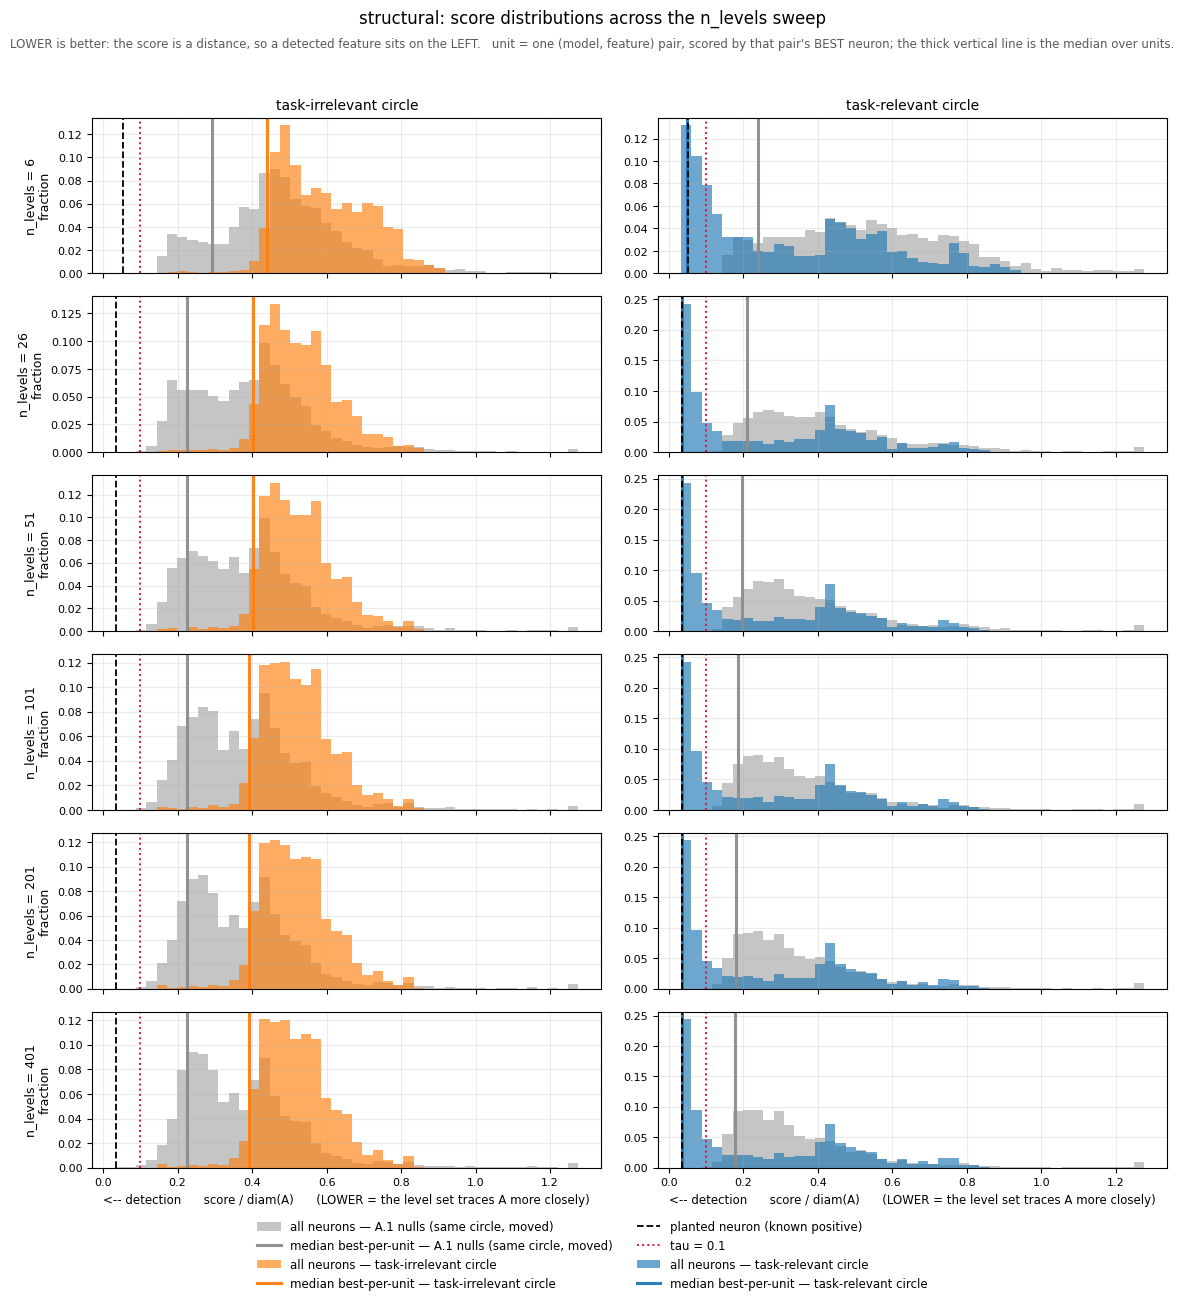

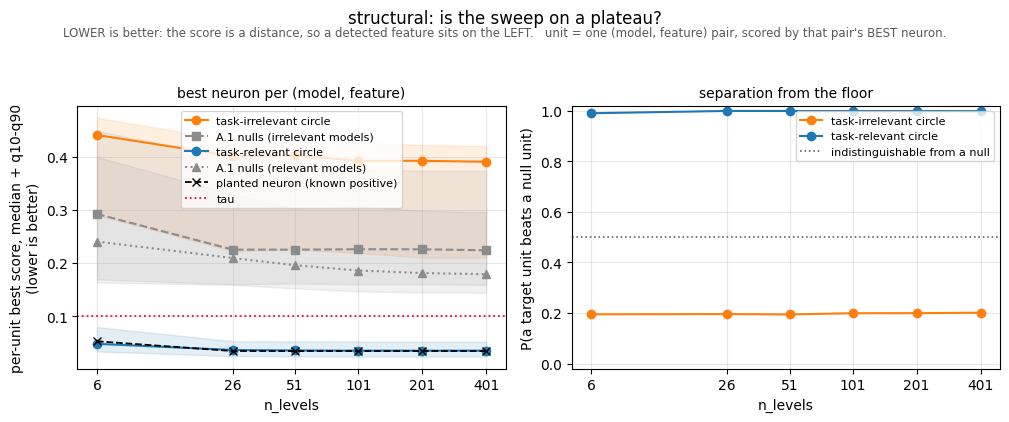

In [25]:
# ── 13. Те же две картинки, что и для resolution, но вдоль n_levels ─────────
#     axis="n_levels" — параметр, а не переименование колонки: плато читается
#     одинаково, чем бы ни свипали, и второй копии этих функций быть не должно.
from visualization.calibration_plots import plot_sweep_distributions, plot_plateau_curves

plot_sweep_distributions(
    nl, "structural", planted=df_A_nl, threshold=TAU, axis="n_levels",
    save_path=(FIGDIR / "nlevels_dist_structural.png") if SAVE else None)

plot_plateau_curves(
    nl, "structural", planted=df_A_nl, threshold=TAU, contrast=nl_contrast,
    axis="n_levels",
    save_path=(FIGDIR / "nlevels_plateau_structural.png") if SAVE else None)


---
### Итоги свипа по `n_levels`

Шесть значений × два датасета, 50 моделей на датасет, 25 нейронов на модель, 5 фич
(цель + 4 нуля A.1) — 75 000 строк в `analysis/results/calibration/sanity_nlevels_sweep.csv`,
сводки в `sanity_nlevels_summary.csv` и `sanity_nlevels_contrast.csv`. Столбец `n_levels = 101`
не считался: это в точности конфигурация свипа по resolution при R = 200, и совпадение
проверено пересчётом шести строк (расхождение 0.0e+00 … 5.6e−17). Остальные пять значений —
9 ч 49 мин счёта.

#### 1. Ответ эксперимента от `n_levels` не зависит

Доля моделей, у которых есть нейрон-свидетель при τ = 0.1:

| `n_levels` | 6 | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|---|
| task-relevant | 0.92 | 0.96 | 0.96 | **0.98** | 0.98 | 0.98 |
| task-irrelevant | 0.00 | 0.00 | 0.00 | **0.00** | 0.00 | 0.00 |
| нули A.1, relevant (200 единиц) | 0.000 | 0.000 | 0.000 | **0.000** | 0.000 | 0.000 |
| нули A.1, irrelevant (200 единиц) | 0.000 | 0.000 | 0.005 | **0.005** | 0.005 | 0.015 |

49 моделей из 50 против 0 из 50 на одной и той же окружности — при любом числе уровней, вплоть
до заведомо грубых шести. Как и в свипе по resolution, вывод не пограничный: `p_superior`
на relevant равен 0.991 при шести уровнях и 0.999 при всех остальных, на irrelevant — 0.19–0.20
(цель ХУЖЕ собственных нулей, это и есть уровень случайности).

#### 2. Цель упирается в потолок инструмента уже на `n_levels = 26`

| | 6 | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|---|
| подсаженный нейрон (истинная ошибка ≈ 0) | 0.0526 | 0.0343 | 0.0343 | **0.0343** | 0.0343 | 0.0343 |
| цель, медиана лучшего на юнит | 0.0478 | 0.0363 | 0.0353 | **0.0349** | 0.0349 | 0.0349 |
| худший relevant-юнит (`model21`) | 0.2318 | 0.1304 | 0.1304 | **0.1304** | 0.1297 | 0.1294 |

Подсаженный нейрон перестаёт меняться после 26 и дальше стоит намертво: его 0.0343 — это
накладные расходы инструмента при R = 200, и они задаются **разрешением**, а не плотностью
уровней. Медиана цели совпадает с ним с точностью 0.0006. Улучшаться цели больше некуда, и
именно поэтому её кривая на графике лежит на чёрной пунктирной.

#### 3. Пол на плато НЕ выходит — он монотонно едет вниз

Это главный результат свипа и он асимметричен предыдущему пункту:

| | 6 | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|---|
| медиана пола (relevant) | 0.2402 | 0.2093 | 0.1958 | **0.1858** | 0.1810 | 0.1788 |
| `gap` = пол − цель | 0.1924 | 0.1730 | 0.1604 | **0.1509** | 0.1461 | 0.1438 |
| **минимум по всем 10 000 нулевых нейронов** | 0.1443 | 0.1124 | 0.0900 | **0.0667** | 0.0582 | **0.0482** |
| второй и третий снизу | 0.146 / 0.151 | 0.114 / 0.114 | 0.113 / 0.114 | **0.111 / 0.113** | 0.110 / 0.111 | **0.075 / 0.095** |
| нулевых нейронов ниже 0.15 | 2 | 61 | 84 | **101** | 122 | 136 |
| ложных срабатываний (score ≤ τ) | 0 | 0 | 1 | **1** | 1 | **3** |

Механизм элементарный и предсказан был заранее: **скор — это минимум по уровням, поэтому больше
уровней = больше попыток.** Цель воспользоваться лишними попытками не может — она стоит на
потолке инструмента; полу есть куда падать (0.18 против порога 0.10), и он падает. `n_levels`
поэтому не ручка чувствительности, а стресс-тест на ложные срабатывания.

#### 4. Формальное плато: связывает пол, а не цель

Допуск 0.01 = τ/10; плато — два подряд шага меньше допуска, последний интервал обязан быть одним
из них.

| величина | шаги 6→26→51→101→201→401 | плато с |
|---|---|---|
| цель, медиана юнита | 0.0116 · 0.0009 · 0.0004 · 0.0000 · 0.0000 | 26 |
| `p_superior` (relevant) | 0.0091 · 0.0002 · 0.0001 · 0.0000 · 0.0002 | 26 |
| `gap_vs_softest` | 0.0075 · 0.0072 · 0.0019 · 0.0011 · 0.0002 | 6 |
| **пол, медиана юнита** | 0.0310 · 0.0135 · 0.0100 · 0.0048 · 0.0023 | **101** |
| **`gap`** | 0.0194 · 0.0126 · 0.0096 · 0.0048 · 0.0023 | **51–101** |
| минимум по нулям | 0.0319 · 0.0224 · 0.0233 · 0.0086 · 0.0100 | не выходит |

Шаг 51 → 101 у пола и у `gap` сидит ровно на допуске (0.0096–0.0100), поэтому связывающая
величина — пол, и её плато начинается на 101.

#### 5. Атрибуция: с какого `n_levels` ε задаётся полем, а не сеткой уровней

Доля нейронов, у которых `best_level_eps` упёрся в отсечку `0.5 · range(f)/(n_levels − 1)`:

| `n_levels` | 6 | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|---|
| relevant / цель | 0.547 | 0.080 | 0.009 | **0.001** | 0.000 | 0.000 |
| irrelevant / цель | 0.575 | 0.406 | 0.063 | **0.002** | 0.000 | 0.000 |
| relevant / нули | 0.587 | 0.403 | 0.243 | **0.148** | 0.098 | 0.061 |
| irrelevant / нули | 0.575 | 0.467 | 0.336 | **0.180** | 0.084 | 0.045 |

Это и есть ответ на вопрос, чем именно двигали. При `n_levels = 26` у 40–47 % нейронов ε задаёт
**сетка уровней**, а не поле: «адаптивный» ε там не адаптивный. К 101 у цели этого не остаётся
(0.1 %), у пола остаётся шестая часть. Дальше 101 меняется только плотность уровней — медианный
ε уже не движется (0.0176 → 0.0174 → 0.0173 на нулях relevant), а минимум по нулям всё равно
продолжает падать. То есть весь эффект после 101 — чистая множественность попыток.


### Чего из этих чисел читать нельзя

**Три ложных срабатывания при 401 — это не «критерий стал лучше находить окружности».**
Поимённо: `model24 L1n4` на `null_above_target` (тот самый эллипс из «Песочницы», разобран там
через лемму Морса) держится ниже τ начиная с 51 и уезжает 0.0900 → 0.0667 → 0.0582 → 0.0482;
при 401 к нему добавляются `model4 L3n4` (0.0754) и `model49 L3n1` (0.0946), оба на
`null_far_right`. Ни один из них не «увидел» нуль лучше — просто при 400 уровнях у каждого
нейрона в четыре раза больше попыток попасть, чем при 100. У `model4 L3n4` при этом
`field_range = 0.167` при медиане 1.51 по ансамблю: это почти мёртвый нейрон (таких 1.2 %),
и его уровни просто очень частые.

**Само число «1 ложное срабатывание» при 51/101/201 неразличимо между этими тремя.** Это один
нейрон из 5000, зернистость счётчика — единица. Различима другая величина: как весь нижний
хвост пола сползает к порогу — 2 → 61 → 84 → 101 → 122 → 136 нейронов ниже 0.15, и 0.1-й
процентиль 0.158 → 0.120 → 0.120 → 0.116 → 0.115 → 0.114. Хвост едет монотонно и без плато.

**Доля моделей-свидетелей (0.92 → 0.98) имеет зерно 1/50 = 0.02**, допуск 0.01 к ней
неприменим. Правильная формулировка: при `n_levels ≥ 101` не проходит τ ровно одна модель
(`model21`), при 26–51 — две, при 6 — четыре.

**`gap` сжимается с ростом `n_levels` (0.192 → 0.144), но это не ухудшение разделения.**
Сжимается он только потому, что пол опускается, тогда как цель стоит; безразмерный `p_superior`
при этом не движется вовсе (0.9998 → 0.9993), и `gap_vs_softest` — тоже (0.139 → 0.129).
Утверждение «цель отделена от пола» от `n_levels` не зависит; зависит от него запас до порога.

**Медиана нерелевантной цели тоже едет (0.4408 → 0.3904), но её минимум — нет:** 0.1900 →
0.1574 → 0.1549 → 0.1547 → 0.1539 → 0.1539, то есть лучший нейрон всего irrelevant-ансамбля
(1250 нейронов) при любом `n_levels` в полтора раза выше τ. Нерелевантная цель порогу не
угрожает ни при каком числе уровней; угрожают ему нули.


### Почему этот свип беднее свипа по resolution

Формы распределений почти не двигаются, и это не случайность выборки — у двух параметров
разный порядок влияния.

Скор — это `min по c от D(c)`, где `D(c)` — нормированное расстояние Чамфера от лучшей
компоненты слоя `{|f − c| ≤ ε}` до A.

* **`resolution` меняет сам `D(c)`, при каждом `c`.** Кривую на сетке нельзя локализовать
  точнее шага `h`, компоненты на грубой сетке рвутся и слипаются — то есть измеряемый объект
  другой. Эффект **первого порядка** по `h`.
* **`n_levels` меняет только то, как густо мы пробуем `c`.** `D(c)` гладко зависит от `c`, а мы
  ищем её минимум; вблизи гладкого минимума `D(c* + δ) − D(c*) = O(δ²)`. Удвоение числа уровней
  уменьшает недобор **вчетверо** — и упирается в пол, поставленный сеткой. Эффект **второго
  порядка**, и он затухает.

Проверяется прямо в данных: медиана цели при R = 200 замирает на 0.0349, а подсаженный нейрон —
на 0.0343. Это и есть пол сетки; ниже него уровни увести скор не могут, сколько их ни добавляй.

Отсюда предсказание про взаимодействие двух параметров: **чем мельче сетка, тем больше стоят
лишние уровни** — пол, в который они упираются, ниже. При R = 400 плато по `n_levels`, вероятно,
наступает позже, чем при R = 200. Мы этого не мерили, и при смене разрешения на это стоит
посмотреть заново.

#### Что этот свип всё-таки дал — четыре наблюдения, которых не было

**1. Нули в четыре-шесть раз чувствительнее к дискретизации, чем цель.** Доля нейронов, у
которых скор отличается от эталона (n = 401) больше чем на 0.01, при n = 51:

| | цель | нули |
|---|---|---|
| relevant | 9.1 % | 55.5 % |
| irrelevant | 13.7 % | 47.7 % |

Причина содержательная: у цели есть **правильный уровень** — минимум `D(c)` острый и
определённый, поэтому сгущение сетки его не двигает. У нуля минимума по существу нет, ландшафт
плоский, и при каждом числе уровней побеждает другой `c`. То есть **устойчивость скора к
дискретизации сама по себе является признаком детекции** — сигнал, которым критерий не
пользуется, и кандидат в отдельный инструмент.

**2. Личность лучшего нейрона держится куда хуже, чем его значение.** Тот же нейрон остаётся
лучшим у пары (модель, фича): 54.6 % при 26 → 51, **67.8 % при 51 → 101**, 75.0 % при 101 → 201,
83.4 % при 201 → 401. Утверждение «у этой модели есть свидетель» устойчиво; утверждение «вот
этот нейрон — свидетель» — заметно слабее. Для абляции (эксперимент 7), которая бьёт по
конкретному нейрону, это прямое ограничение.

**3. Скор худшего нулевого нейрона задаёт не поле, а отсечка ε.** У единственного ложного
срабатывания (`model24 L1n4`) `best_level_eps` в точности равен `eps_floor` и при 51 (0.0103), и
при 101 (0.0051), а его скор падает ровно так же, как отсечка: 0.0900 → 0.0667 → 0.0582 → 0.0482.
Вот почему у жёсткой защиты нет плато — она отслеживает `range(f)/(2(n − 1))`, а не сеть.

**4. Пол убывает по степенному закону, а не выходит на полку.** Минимум по 10 000 нулевых
нейронов: 0.1443 → 0.1124 → 0.0900 → 0.0667 → 0.0582 → 0.0482, что близко к `n^(−0.28)` на всём
диапазоне от 6 до 401. Это измеренная **чувствительность пола к числу попыток**, и она
понадобится в эксперименте 2 — см. раздел про перенос нулей ниже.


### Решение: `n_levels = 101`

| | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|
| `p_superior`, relevant | 0.9998 | 0.9996 | **0.9995** | 0.9995 | 0.9993 |
| моделей не прошло τ (из 50) | 2 | 2 | **1** | 1 | 1 |
| ложных срабатываний на нулях | 0 | 1 | **1** | 1 | 3 |
| минимум по нулям (запас до τ) | 0.1124 | 0.0900 | **0.0667** | 0.0582 | 0.0482 |
| ε задан сеткой: цель / нули | 0.41 / 0.44 | 0.06 / 0.29 | **0.002 / 0.16** | 0 / 0.09 | 0 / 0.05 |
| время на оба датасета | 0.6 ч | 0.9 ч | **1.9 ч** | 2.9 ч | 5.0 ч |

**Почему не 26 и не 51.** Не по числам, а по режиму: там у 40 % (26) и 25–34 % (51) нейронов
адаптивный ε упирается в отсечку по сетке уровней, то есть измеряется не то, что заявлено —
не локальный масштаб поля, а шаг перебора. Заодно `gap` там ещё не устоялся (0.173 и 0.160
против 0.144 при 401, отклонение 0.029 и 0.017 при допуске 0.01).

**Почему не 201 и не 401.** Они не покупают ничего измеримого: `p_superior` ±0.0002, медиана
цели ±0.0000, тот же 49/50. Платится за это временем (×1.5 и ×2.6) и запасом до порога:
минимум по нулям 0.0667 → 0.0582 → 0.0482, а при 401 ложных срабатываний становится три вместо
одного. Единственная величина, которая от них меняется, — та, которую мы не хотим менять.

**Почему 101.** Это последнее значение, на котором пол ещё на плато (шаг 51 → 101 ровно на
допуске, дальше 0.005 и 0.002) и одновременно первое, на котором ε цели полностью задаётся
полем, а не сеткой (0.1 % против 6 % при 51). Плюс два практических следствия: 101 — **дефолт
`structural_criterion`**, так что в спеке ничего менять не нужно, и весь уже посчитанный
`sanity_resolution_sweep.csv` сделан ровно при этой настройке, то есть остаётся в силе целиком.

#### Пересмотр: а не взять ли 51 и не считать вдвое быстрее?

Аргумент за 51 серьёзный: структурный критерий — **70.8 %** времени этого эксперимента
(гомология — остальные 29.2 %), значит `n_levels = 51` экономит около трети каждого будущего
прогона, а там, где гомология не считается, — ровно половину.

> **Главный довод против 51 — один.** При 51 пол приподнят самой дискретизацией, и приподнят
> в ту сторону, которая нам льстит.
>
> Механика: когда адаптивный ε упирается в нижнюю отсечку `0.5·range(f)/(n − 1)`, он
> **увеличивается** против того, что подсказало поле. Более толстый слой `{|f − c| ≤ ε}` даёт
> более жирную линию уровня, а значит **больший** скор. Теперь смотрим, у кого отсечка активна:
>
> | | цель relevant | цель irrelevant | нули relevant | нули irrelevant |
> |---|---|---|---|---|
> | n = 51 | 0.9 % | 6.3 % | **24.3 %** | **33.6 %** |
> | n = 101 | 0.1 % | 0.2 % | 14.8 % | 18.0 % |
>
> Цель при 51 практически не задета, а четверть-треть пола — задета. Пол раздувается, цель нет,
> и разрыв между ними растёт: `gap` = **0.1604** при 51, 0.1509 при 101, 0.1438 при 401.
> **Чем грубее сетка уровней, тем лучше выглядит наш результат** — и ровно на ту величину,
> которая создана отсечкой, а не сетью.
>
> Поэтому «при 51 пол безопаснее» — не довод за 51, а симптом. Выбирать значение гиперпараметра
> потому, что при нём результат выглядит убедительнее, нельзя; выбирать надо то, при котором
> этого артефакта меньше за разумную цену. Остаток артефакта относительно эталона n = 401:
> **0.0166** при 51, **0.0070** при 101, 0.0023 при 201. Сто первый уровень убирает больше
> половины за 2× цены; двести первый убрал бы ещё 0.0047 за ещё 1.5×.

Всё остальное ниже — проверка, что этот довод не перевешивается чем-то более важным. Не
перевешивается: по вердикту 51 и 101 неразличимы.

**По вердикту не теряется ничего.** Вердикт `score ≤ τ` расходится у **2 нейронов из 12 500**
(0.016 %), и оба сидят на пороге с точностью до четвёртого знака:

| нейрон | n = 51 | n = 101 | n = 401 |
|---|---|---|---|
| `model7 L4n3` | 0.1002 | 0.0953 | 0.0953 |
| `model36 L3n2` | 0.1007 | 0.0966 | 0.0956 |

Из-за первого из них моделей, не прошедших τ, при 51 две, а при 101 одна. Но `model7` не
проходит на **0.0002** — это не разница в чувствительности, это монета, вставшая на ребро. Ставить
на такой разнице выбор гиперпараметра нельзя.

**По полу 51 даже безопаснее:** минимум по нулям 0.0900 против 0.0667, `gap` 0.1604 против
0.1509, ложное срабатывание одно и то же. `p_superior` 0.9996 против 0.9995.

**Теряется понейронная воспроизводимость скора.** Отклонение от эталона n = 401:

| | медиана \|Δ\| | 90-й проц. | \|Δ\| > 0.01 |
|---|---|---|---|
| n = 51 | 0.0069 | 0.0745 | **43.5 %** |
| n = 101 | 0.0023 | 0.0392 | **27.0 %** |

Важно, что это **систематический сдвиг, а не шум**: сетки вложены, поэтому более густая может
найти только не худший минимум, и `score(51) ≥ score(101)` у 86.2 % нейронов при медиане
разности +0.0010. Систематический сдвиг одинаков во всех ячейках и в сравнениях сокращается —
он портит только абсолютные утверждения и сопоставление с числами, посчитанными при другом
`n_levels`.

**И довод из врезки только усиливается с разрешением.** Сырой ε масштабируется как `|∇f|·h`, а
отсечка — как `range(f)/(2(n−1))` и от сетки не зависит вовсе, поэтому чем мельче сетка, тем
чаще отсечка побеждает. При R = 400 и n = 101 она уже определяет ε у 55 % нулевых нейронов; при
n = 51 определяла бы у большинства. Раз будущие эксперименты пойдут на разных разрешениях (см.
следующий раздел), 51 привязывает пол к сетке уровней ровно в том режиме, куда мы идём.

**Итого.** Остаётся 101 — но честная формулировка такая: *по вердикту 51 и 101 — один и тот же
детектор*, и если конкретный прогон упирается в вычислительный бюджет, `n_levels = 51` не поменяет
ни одного вывода при условии, что **всё внутри этого прогона посчитано при одном и том же
`n_levels`** (иначе систематический сдвиг +0.001…+0.007 перестаёт сокращаться). Значения между
ними — 65, 81 — не измерены: их нет во вложенной цепочке, сравнить со свипом их нельзя, а
выигрыш они дают частичный. Выбирать стоит из двух измеренных.

Замечу, что вдвое быстрее можно стать и не трогая `n_levels` вовсе — следующий раздел про то, что
сетка сейчас в 1.8 раза гуще по одной оси, чем по другой, и это чистая переплата.

#### Замороженная конфигурация детектора

```python
resolution      = 200          # свип по resolution
n_levels        = 101          # этот свип; дефолт structural_criterion
level_eps       = "adaptive"   # решение принято, не перебиралось
levels          = linspace(min f, max f, n_levels)   # activation=None, наблюдённый размах
threshold τ     = 0.1
# гомологический критерий:
backend = "delaunay", max_sample_points = 7000
```

Про запас до порога стоит помнить при интерпретации любого следующего эксперимента: пол — это
не «нуль», а величина 0.18 с нижним краем 0.067 при τ = 0.1. Один нейрон из 5000 на нуле
критерий проходит, и это свойство инструмента, а не сети.


---
## Перенос калибровки на другие масштабы

Два свипа выше зафиксировали числа для **этого** бокса и **этой** окружности. Перебирать
гиперпараметры в каждом эксперименте мы не собираемся, поэтому вопрос стоит так: какие из
зафиксированных величин безразмерны и переносятся как есть, а какие привязаны к масштабу и
требуют пересчёта.

### Что уже безразмерно и не требует ничего

| величина | почему переносится |
|---|---|
| **τ = 0.1** | скор делится на `diam(A)`, то есть порог — это «доля диаметра фичи». Круг вдвое больше — и допуск вдвое больше в абсолютных единицах. |
| **`n_levels = 101`** | уровни строятся по `linspace(min f, max f, n)`, а `f` у нейрона всегда в (−1, 1). Число уровней — это доля размаха, к геометрии отношения не имеет. Именно поэтому вопрос переноса для `n_levels` не стоит. |
| **`level_eps = "adaptive"`** | сырой ε берётся из локальных скачков поля, то есть `≈ \|∇f\|·h`, и масштабируется вместе с сеткой сам. Нижняя отсечка `0.5·range(f)/(n−1)` тоже безразмерна. |
| **`neighborhood_factor = 1.5`** у гомологии | окно уже задано в радиусах фичи. |

### Что привязано к масштабу: `resolution`

Сейчас `resolution = 200` на боксе 13.5 × 7.5 при `diam(A) = 3.0`. Отсюда два факта, которые
видно только в безразмерном виде.

**Факт первый: ячейки не квадратные.** `resolution` — одно число на обе оси, а бокс вытянут в
1.8 раза, поэтому

| R | 25 | 50 | 100 | **200** | 400 |
|---|---|---|---|---|---|
| `h_x` | 0.5625 | 0.2755 | 0.1364 | **0.0678** | 0.0338 |
| `h_y` | 0.3125 | 0.1531 | 0.0758 | **0.0377** | 0.0188 |
| `h_x / h_y` | 1.80 | 1.80 | 1.80 | **1.80** | 1.80 |

Локализация кривой ограничена **грубой** осью (`grid_step_from_bounds_resolution` так и
устроена — она возвращает максимум по осям), значит по `y` мы считаем 1.8 лишних точки на каждую
полезную. Это чистая переплата: при квадратной ячейке то же эффективное разрешение
(`h = 0.0678` по обеим осям) стоит 200 × 112 = 22 400 точек вместо 40 000 — **в 1.8 раза
дешевле при том же результате**.

**Факт второй: правильная безразмерная величина — сколько шагов сетки укладывается в диаметр
фичи.** Обозначим `N_A = diam(A) / max(h_x, h_y)`. Тогда весь свип по resolution переписывается
без всякой привязки к боксу:

| R | 25 | 50 | 100 | **200** | 400 |
|---|---|---|---|---|---|
| `N_A` | 5.3 | 10.9 | 22.0 | **44.2** | 88.7 |
| подсаженный нейрон | 0.1278 ✗ | 0.0946 | 0.0741 | **0.0343** | 0.0207 |
| `p_superior` (relevant) | 0.9835 | 0.9938 | 0.9990 | **0.9995** | 0.9995 |
| моделей не прошло τ | 7 | 4 | 2 | **1** | 1 |

Читается это так:

* **`N_A < 6` — инструмент не работает вовсе.** При R = 25 подсаженный нейрон, чья истинная
  геометрическая ошибка ≈ 0, набирает 0.1278 и **не проходит собственный порог**. Пять точек на
  диаметр — это не окружность, это пиксель.
* **`N_A ≈ 22` — порядковый вердикт уже устойчив** (`p_superior` вышел на плато).
* **`N_A ≈ 44` — устойчив и счётный вердикт** (число моделей без свидетеля перестало меняться).
* **`N_A ≈ 89` не даёт ничего**: `p_superior` +0.0000, моделей ±0.

Почему кривая ложится, видно из простой модели: скор складывается из **ошибки дискретизации**
(∝ `h`, то есть ∝ `1/N_A`) и **несовпадения формы** — уровень нейрона не круг, и это от сетки не
зависит. Минимум по relevant-целям идёт как `h^0.59`, то есть уже не как `h`: при `N_A ≳ 44`
дискретизация перестаёт быть главным слагаемым, и дальше мы уточняем то, что и так уже не мешает.

### Практическое правило для нового эксперимента

```python
h = diam(A) / 40                                  # 40 шагов на диаметр фичи
resolution = tuple(int(np.ceil((b - a) / h)) + 1  # по одному числу на ось
                   for a, b in BOUNDS)
```

Для нашего бокса это даёт `(181, 101)` вместо `200`: **18 281 точка против 40 000, в 2.2 раза
дешевле**, при `N_A = 40` против нынешних 44.2 — то есть на рабочей точке, а не выше неё. Переход
на поосевое разрешение даёт тот же двукратный выигрыш, что и `n_levels = 51`, но платит за него
величиной, которая на плато, а не режимом работы адаптивного ε.

Границы применимости правила:

* `N_A = 40` — рабочая точка, `N_A = 20` — минимум, на котором ещё держится порядковый вывод,
  `N_A < 6` — отказ инструмента. Между 20 и 40 меняется счётный вердикт у пограничных моделей.
* Всё это измерено на **окружности**. Для фичи с более мелкой деталью (волнистая окружность,
  дуга) связывающий масштаб — не диаметр, а размер детали, и `N_A` надо считать по нему.
* Бокс должен оставаться достаточно большим: здесь он 4.5 × 2.5 диаметра фичи, и в нём помещены
  четыре нуля. Уменьшать его до «фича плюс поля» нельзя — нулям негде будет стоять.
* **`max_sample_points` гомологического критерия тоже привязан к масштабу.** Точек сетки в его
  окне: `π·(1.5·diam/2)² / (h_x·h_y)`, при квадратной ячейке это `≈ 1.77·N_A²` — около 2 800 при
  `N_A = 40`. Наши 7 000 покрывают это с запасом 2.4×; при существенно большем `N_A` значение
  надо поднимать, иначе вернётся подвыборка со своим фиксированным розыгрышем.


#### Что из поведения нулей переносится на другие эксперименты

Вопрос практический и денежный: четыре нуля — это ×5 по числу фич в оценке. Можно ли из этой
калибровки унести правило, которое позволит в следующих экспериментах ставить меньше нулей и
знать, что набор всё ещё репрезентативен.

#### Сначала — что упорядочивает пол, а что нет

Медиана лучшего нейрона на пару (модель, фича), `n_levels = 101`:

| размещение | центр | расстояние до цели | irrelevant | relevant |
|---|---|---|---|---|
| `far_right` | (3.5, 0) | 3.5 | **0.1764** | **0.1650** |
| `on_blue_disk` | (−6, 0) | 6.0 | 0.2044 | 0.1748 |
| `above_target` | (0, 3.5) | 3.5 | 0.2590 | 0.1968 |
| `in_between` | (−3, 0) | 3.0 | **0.3675** | **0.2997** |

Первое, что отсюда следует: **расстояние — не тот признак**. `far_right` и `above_target` стоят
на одном и том же расстоянии 3.5 от центра цели, они переводятся друг в друга поворотом на 90°,
и оба — копии одной окружности. Полы у них различаются на **47 %** (irrelevant). Значит пол
зависит не от того, *как далеко* стоит нуль, а от того, *в каком направлении* — то есть от
геометрии самой сети, а не от абстрактной близости к данным. Соображение вида «нуль рядом с
данными, поэтому нейроны там ненасыщены, поэтому сравнивать надо с такими же» разбивается об эту
пару: одинаковое расстояние, разный пол.

#### А что упорядочивает — видно по слоям

Медиана скора по слоям (все нейроны, `n_levels = 101`, irrelevant):

| размещение | L0 | L1 | L2 | L3 | L4 |
|---|---|---|---|---|---|
| `far_right` | 0.422 | 0.273 | 0.254 | **0.228** | 0.272 |
| `on_blue_disk` | 0.426 | 0.276 | 0.257 | 0.251 | **0.238** |
| `above_target` | 0.500 | 0.363 | 0.343 | **0.341** | 0.344 |
| `in_between` | 0.462 | 0.468 | 0.487 | 0.489 | 0.490 |

Картина однозначная. **Везде, кроме коридора, глубина покупает кривизну** и скор падает на 40 %
от слоя 0 к глубоким: линия уровня нейрона первого слоя — прямая (точно), глубже она гнётся и
может замкнуться. **В коридоре `in_between` глубина не покупает ничего**: 0.462 → 0.490, плоско.

Механизм отсюда читается прямо, и он обратен наивному. В коридоре между классами проходит
граница решения, и там **все** нейроны считают, по существу, одно и то же — разделение вдоль оси
задачи. Их линии уровня почти параллельны друг другу и границе, компонента получается длинной
дугой через весь коридор, а замкнутого круга радиуса 1.5 из неё не сделать никакой глубиной.
Вдали от границы такой согласованности нет, разные нейроны дают по-разному изогнутые линии, и
среди двадцати пяти попыток находится подходящая.

**То есть пол в точке определяется не насыщенностью и не близостью к данным, а разнообразием
семейства линий уровня в окрестности. И оно минимально ровно там, где живёт задача.** Область,
где сеть «активнее всего», — самая трудная для случайного совпадения, а не самая лёгкая.

#### Побочно: глубина совпадения сама по себе — сигнал

Из какого слоя приходит лучший нейрон (`n_levels = 101`, relevant):

| | L0 | L1 | L2 | L3 | L4 |
|---|---|---|---|---|---|
| **цель** | 0.00 | 0.00 | 0.02 | **0.52** | **0.46** |
| нули (среднее по 4 размещениям) | 0.09 | 0.35 | 0.32 | 0.19 | 0.05 |

98 % задача-релевантных свидетелей живут в двух последних слоях; у нулей туда попадает 20–28 %.
Критерий этой информацией не пользуется — он берёт лучший нейрон, откуда бы тот ни был. Вместе
с наблюдением 1 предыдущего раздела (устойчивость скора к дискретизации) это второй бесплатный
признак, отличающий настоящее совпадение от случайного, и кандидат в отдельный инструмент.

#### Guideline: какой минимальный набор нулей считать репрезентативным

Требование к набору — **покрытие**, а не подгонка под цель (подгонка ведёт к регрессу,
заканчивающемуся самой целью; см. коммит «A null owes the target its shape and coverage»).
Вопрос, который здесь решён, — *что именно* набор обязан покрыть. Ответ: не диапазон расстояний
до данных, а **диапазон разнообразия линий уровня**, и он в первую очередь **направленный**.

Минимальный набор — **два** размещения, если отчитываться по `gap_vs_softest` (сравнение цели с
самым мягким полом — то, что реально связывает вердикт):

1. **вдали от границы решения, вдоль оси задачи** — здесь разнообразие максимально и пол самый
   мягкий. У нас это `far_right`, и он был мягчайшим при каждом разрешении и каждом `n_levels`;
2. **на том же расстоянии, но поперёк оси задачи** — это не дубль, а проверка того, что мягкое
   направление найдено: у нас та же пара разошлась на 47 %.

Третье размещение — **в коридоре у границы решения** — нужно, только если отчитываться шириной
пола: оно даёт жёсткий конец (0.37 против 0.18) и никогда не связывает вердикт. Размещение на
данных противоположного класса (`on_blue_disk`) в наших данных ничего не добавило: оно легло
между двумя мягкими и не стало ни максимумом, ни минимумом.

Два условия, без которых это правило не работает:

* **Проверка допустимости.** Размещение в мёртвой области, где `f` почти постоянна, даёт не
  «мягкий пол», а отсутствие измерения: линий уровня там нет, компонента — вся окрестность, скор
  огромен. Для этого в репозитории есть `field_grad_norm_on_feature` — проверка «а возможно ли
  здесь срабатывание вообще», применяемая к розыгрышу, а не к цели.
* **Сигнал тревоги.** Если два размещения дали пол, совпадающий с точностью до нескольких
  процентов, — вероятнее всего, они оба попали в один режим, и покрытия нет. Тогда нужен третий.

Экономия: два нуля вместо четырёх — это ×3 по числу фич вместо ×5, то есть **−40 % времени
оценки**. Это сопоставимо со всем, что можно выиграть на `n_levels` и на поосевом разрешении
вместе взятых.

#### Чего переносить нельзя

**Абсолютного значения пола на другую задачу.** У нас два датасета дали близкие полы (0.186 и
0.226 суммарно, 7–32 % по совпадающим размещениям), но это **не** свидетельство переносимости:
датасеты специально построены так, чтобы делить одни и те же объекты и одни и те же положения
нулей, и различаться только тем, какая часть геометрии нужна задаче. Это одна геометрия, взятая
дважды, а не две задачи. **Про перенос пола между разными задачами у нас нет данных вообще**, и
пол надо мерить заново в каждом эксперименте.

**Минимума по нулям.** Он задан отсечкой ε, а не сетью (наблюдение 3 предыдущего раздела): у
худшего нулевого нейрона `best_level_eps` в точности равен `0.5·range(f)/(n−1)`. Это величина
инструмента. Переносить стоит медианы по размещениям.

**Пола под другой множественностью.** Скор — минимум по уровням и нейронам, то есть статистика
экстремума, и свип по `n_levels` измерил её чувствительность напрямую: ×7.9 попыток при
неизменной сети сдвинули медиану пола на −8.7 %, минимум — на −46 % (примерно `N^(−0.28)`), а
ложные срабатывания с 1 до 3. Уровни внутри нейрона сильно скоррелированы, разные нейроны — куда
меньше, поэтому та же кратность, набранная **нейронами**, сдвинет пол сильнее: измеренный закон
— нижняя оценка. Отсюда прямое следствие для эксперимента 2: **доля ложных срабатываний на нулях
растёт с шириной по построению**, той же множественностью, что и доля свидетелей, поэтому долю
свидетелей при ширине W можно сравнивать только с полом, измеренным при **той же** ширине.

**Пола для другой формы фичи.** Окружность — жёсткая мишень: нужна замкнутая кривая
определённого радиуса, и именно поэтому глубина так помогает, а коридор так труден. Для дуги
(`calibration.arc_feature`) или для области баланс будет другим, и из наших чисел про них не
следует ничего.


## 3. Detector validity

Проанализировать score идеального planted neuron для всех протестированных конфигураций.

**Задача:** показать, что критерий в принципе способен обнаружить заведомо существующую целевую геометрию и что выбранная область гиперпараметров не уничтожает эту способность.


In [26]:
# ── A: подсаженный нейрон — известный положительный ──────────────────────────
#     Всё из уже сохранённых таблиц: свип по resolution считал его при каждом R,
#     свип по n_levels — при каждом n. Ничего не пересчитывается.
if "df_A_nl" not in globals():
    df_A_nl = cal.read_scores_csv(NL_PLANTED_CSV)

_s = df_A[df_A.criterion == "structural"]
_h = df_A[df_A.criterion == "homological"]
_val = float(_s[_s.resolution == REFERENCE_RES].score.iloc[0])
_ideal = float(_s[_s.resolution == REFERENCE_RES].ideal_score.iloc[0])

print(f"при замороженной конфигурации (R = {REFERENCE_RES}, n_levels = 101):")
print(f"  истинная геометрическая ошибка конструкции : {_ideal:.4f}")
print(f"  structural score                           : {_val:.4f}  "
      f"(= {_val/TAU:.2f} tau, свидетель: {bool(_s[_s.resolution==REFERENCE_RES].is_witness.iloc[0])})")
print(f"  из них накладные расходы инструмента       : {_val - _ideal:.4f} "
      f"({(_val - _ideal)/_val:.0%} скора)")
print(f"  homological margin                         : "
      f"{float(_h[_h.resolution == REFERENCE_RES].score.iloc[0]):.4f}")

display(pd.concat([
    _s.set_index("resolution")[["score", "is_witness"]].add_prefix("R: "),
], axis=1).T)
display(df_A_nl.set_index("n_levels")[["score", "is_witness"]].add_prefix("n_levels: ").T)

# Поле подсаженного нейрона нарисовано выше, в ячейке 3b свипа по resolution:
# там же видно, какую именно компоненту уровня критерий выбрал и с чем сравнил.


при замороженной конфигурации (R = 200, n_levels = 101):
  истинная геометрическая ошибка конструкции : 0.0016
  structural score                           : 0.0343  (= 0.34 tau, свидетель: True)
  из них накладные расходы инструмента       : 0.0327 (95% скора)
  homological margin                         : 0.4124


resolution,25,50,100,200,400
R: score,0.127846,0.094597,0.074123,0.034313,0.020726
R: is_witness,False,True,True,True,True


n_levels,6,26,51,101,201,401
n_levels: score,0.052644,0.034313,0.034313,0.034313,0.034313,0.034313
n_levels: is_witness,True,True,True,True,True,True



> **Поправка от 2026-08-28 (по результатам эксперимента 2).** Формулировка «потолок инструмента»
> ниже **неверна** и отменяется. На том же боксе и при том же `R = 200` эксперимент 2 находит
> **1 876 нейронов из 17 800 ниже 0.0343**, минимум **0.0165**, причём доля таких растёт с шириной
> (4.9 % при `w3 d5` → 24.7 % при `w20 d5`). Накладные расходы зависят от профиля поля: у
> подсаженного нейрона шапка нормирована на единицу, поле доходит лишь до ≈ 0.76 и остаётся
> пологим, поэтому адаптивная ε у него широкая; у обученного нейрона с крутым кольцом полоса
> уровня тоньше. Правильное прочтение 0.0343 — **пример низкого значения на заведомом свидетеле**,
> ровно в том же смысле, в каком гомологический margin этого же нейрона назван ниже «известным
> положительным, а не потолком»: величина зонда, а не критерия. Переносится метод разложения, а не
> число.

**Вывод раздела 3 (часть 1): инструмент способен обнаружить заведомо существующую геометрию.**

Подсаженный нейрон — это радиальная конструкция, вписанная в реальную обученную сеть на слое 3, у
которой целевая окружность лежит в её линии уровня **по построению**. Её истинная геометрическая
ошибка — **0.0016**, то есть практически ноль. Измеренный скор при замороженной конфигурации —
**0.0343**, вердикт «свидетель» при τ = 0.1 с запасом в **2.9 раза**.

Отсюда сразу два прочтения, и второе важнее первого:

1. **Базовая работоспособность подтверждена.** Детектор находит окружность, которая там есть.
2. **0.0343 — это уровень накладных расходов измерения на ЭТОМ зонде, а не свойство нейрона** (в первой редакции здесь стояло «потолок инструмента», см. поправку выше). Из них 0.0016 — сама геометрия, а
   **0.0327 (95 % скора)** — накладные расходы измерения: конечная сетка, конечный набор уровней,
   толщина слоя ε. Ни один нейрон, каким бы идеальным он ни был, при R = 200 не получит меньше.
   Поэтому медиана task-relevant цели **0.0349** (раздел 6) — не «почти идеально», а **упёрлась в
   то же значение**: разница с подсаженным нейроном 0.0006, то есть 2 % от накладных расходов.

**Зависимость от конфигурации — и один отказ, который стоит запомнить:**

| R | 25 | 50 | 100 | **200** | 400 |
|---|---|---|---|---|---|
| score | **0.1278** | 0.0946 | 0.0741 | **0.0343** | 0.0207 |
| свидетель | **нет** | да | да | **да** | да |

При R = 25 подсаженный нейрон **не проходит собственный порог**. Это самая ясная формулировка
того, зачем нужен раздел про разрешение: при пяти точках на диаметр фичи отрицательный ответ
критерия не значит ничего — он говорит о сетке, а не о сети. Порог применим только там, где
инструмент проходит собственную проверку.

По `n_levels` (при R = 200) картина иная: 0.0526 при шести уровнях, дальше **0.0343 и без
изменений** от 26 до 401. Потолок задаётся разрешением, а не плотностью уровней — ровно как и
предсказывает разбор в разделе 2.

**Гомологический критерий здесь ведёт себя иначе, и это не дефект.** Его margin на подсаженном
нейроне — 0.4124, тогда как обученные нейроны дают до 1.63. Причина в конструкции: `plant_radial_neuron`
нормирует шапку на максимум 1 и оставляет последующий tanh в линейном режиме, поэтому поле
доходит лишь до ≈0.76 и бар получается коротким. Для структурного критерия подсаженный нейрон —
**потолок**, для гомологического — только **известный положительный**: он показывает, что
критерий срабатывает, но не задаёт планку.

## 4. False-positive behaviour

Проанализировать распределения скоров на 4–5 заранее зафиксированных `null_features`.

**Задача:** установить baseline поведения критерия на заведомо отрицательных объектах и проверить отсутствие патологических режимов при изменении гиперпараметров.


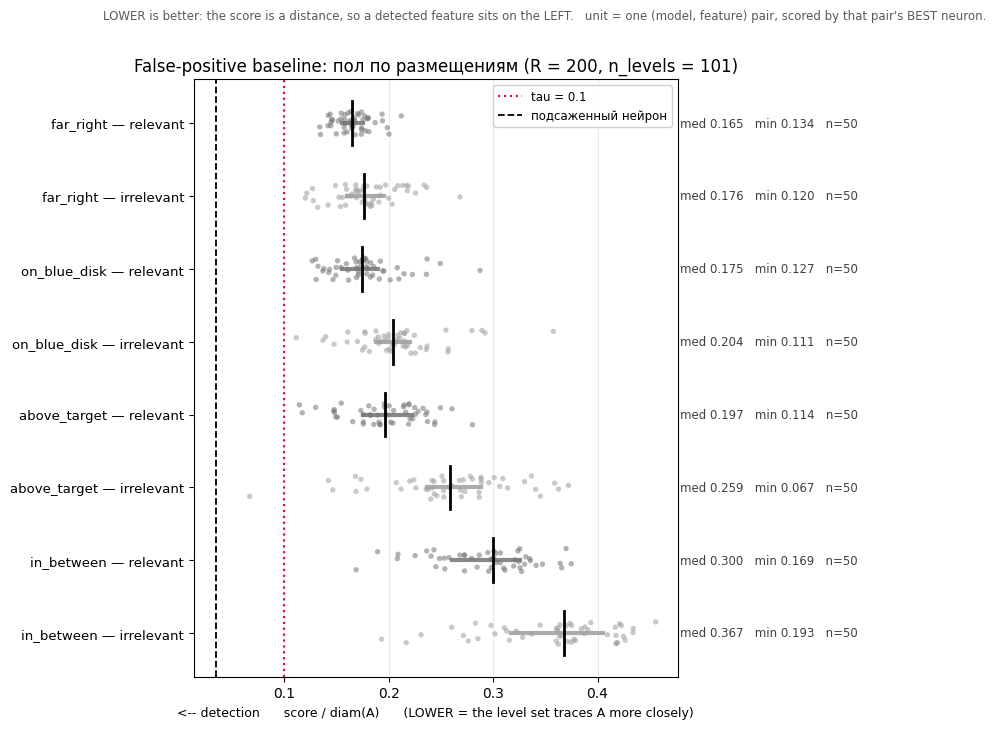

медиана     q25     q75  минимум  юнитов
feature           dataset                                             
null_above_target irrelevant   0.2590  0.2363  0.2886   0.0667      50
                  relevant     0.1968  0.1756  0.2222   0.1144      50
null_far_right    irrelevant   0.1764  0.1598  0.1957   0.1201      50
                  relevant     0.1650  0.1551  0.1749   0.1339      50
null_in_between   irrelevant   0.3675  0.3172  0.4055   0.1930      50
                  relevant     0.2997  0.2603  0.3253   0.1688      50
null_on_blue_disk irrelevant   0.2044  0.1876  0.2205   0.1113      50
                  relevant     0.1748  0.1555  0.1896   0.1266      50

юнитов ниже tau: 1 из 400   |   нейронов ниже tau: 1 из 10000
ширина пола (max−min по восьми ячейкам): 0.2025


In [28]:
# ── Замороженная конфигурация: дальше всё считается ТОЛЬКО при ней ───────────
#     R = 200, n_levels = 101 — выбор разделов выше. Свипы уже ответили на
#     вопрос «зависит ли ответ от параметров»; разделы 4-7 отвечают на вопрос
#     «каков ответ» тем детектором, который поедет в следующие эксперименты.
#     Устойчивость каждого утверждения — одной строкой в его выводе, системно —
#     в разделе 8.
from visualization.calibration_plots import plot_populations, plot_unit_strips

if "ens" not in globals():
    ens = cal.read_scores_csv(SWEEP_CSV)
if "df_A" not in globals():
    df_A = cal.read_scores_csv(PLANTED_CSV)

FROZEN     = ens[ens.resolution == REFERENCE_RES]
PLANTED_200 = df_A[df_A.resolution == REFERENCE_RES]
PLANTED_AT = float(PLANTED_200[PLANTED_200.criterion == "structural"].score.iloc[0])
CONTRAST   = cal.sweep_contrast(FROZEN[FROZEN.criterion == "structural"],
                                by=("criterion", "dataset"), threshold=TAU)
CONTRAST_H = cal.sweep_contrast(FROZEN[FROZEN.criterion == "homological"],
                                by=("criterion", "dataset"))
_units = cal.best_per_unit(FROZEN[FROZEN.criterion == "structural"],
                           lower_is_better=True, unit=("model_path", "feature", "dataset"))

# ── B: пол — это распределение по размещениям, а не число ────────────────────
_NULLS = ["null_far_right", "null_on_blue_disk", "null_above_target", "null_in_between"]
plot_unit_strips(FROZEN, "structural",
    [(f"{p.replace('null_', '')} — {d}", {"dataset": d, "feature": p},
      "0.45" if d == "relevant" else "0.62")
     for p in _NULLS for d in ("relevant", "irrelevant")],
    threshold=TAU, planted=PLANTED_AT,
    title="False-positive baseline: пол по размещениям (R = 200, n_levels = 101)",
    save_path=(FIGDIR / "s4_floor_by_placement.png") if SAVE else None)

_n = _units[_units.role == "null"]
display(_n.groupby(["feature", "dataset"])["best_score"]
        .agg(медиана="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75),
             минимум="min", юнитов="size").round(4))
_nn = FROZEN[(FROZEN.criterion == "structural") & (FROZEN.role == "null")]
print(f"юнитов ниже tau: {int((_n.best_score <= TAU).sum())} из {len(_n)}   |   "
      f"нейронов ниже tau: {int((_nn.score <= TAU).sum())} из {len(_nn)}")
print(f"ширина пола (max−min по восьми ячейкам): "
      f"{_n.groupby(['feature','dataset'])['best_score'].median().max() - _n.groupby(['feature','dataset'])['best_score'].median().min():.4f}")


**Вывод раздела 4.** Пол — не число, а распределение по размещениям. Восемь ячеек
(4 размещения × 2 датасета) дают медианы от **0.1650** (`far_right`, relevant) до **0.3675**
(`in_between`, irrelevant) — разброс **0.2025**, то есть больше, чем отрыв цели от пола
(`gap` = 0.1509). Отсюда правило отчётности: вердикт сравнивается с **самым мягким** размещением
(`gap_vs_softest`), а не со средним по полу.

**Эмпирический baseline ложных срабатываний при τ = 0.1: 1 юнит из 400** (0.25 %) и **1 нейрон из
10 000**. Единственное срабатывание — `model24 L1n4` на `null_above_target`, 0.0667; в «Песочнице»
показано, что это замкнутая линия уровня эллиптической формы у нейрона слоя 1, и объяснено, почему
она там вообще может быть (лемма Морса: вблизи невырожденного максимума линии уровня — эллипсы;
для окружности нужно кратное собственное значение, а ширина 5 даёт лишь 2 независимых направления
из 3 нужных для изотропии).

Два ограничения, о которых нельзя забывать при переносе этих чисел:

* **Минимум по нулям — величина инструмента, а не сети.** У худшего нулевого нейрона
  `best_level_eps` в точности равен отсечке `0.5·range(f)/(n−1)`, и его скор падает вместе с ней
  при росте `n_levels`. Переносить стоит медианы по размещениям, они устойчивы.
* **Ложные срабатывания растут с числом попыток.** ×7.9 уровней сдвинули их с 1 до 3 при
  неизменной сети; та же кратность, набранная нейронами (ширина, глубина), сдвинет сильнее.

Устойчивость по свипам: ни одного ложного срабатывания на relevant-нулях при любом R и любом
`n_levels`; на irrelevant-нулях — 0 при R ≤ 50 и ровно одно при R ≥ 100.

## 5. Task irrelevance

Проанализировать scores на task-irrelevant feature датасета A и сравнить их с соответствующим null baseline.

**Задача:** показать, что наличие геометрической фичи, не требуемой задачей, не приводит к систематической детекции по сравнению с null-features.

---

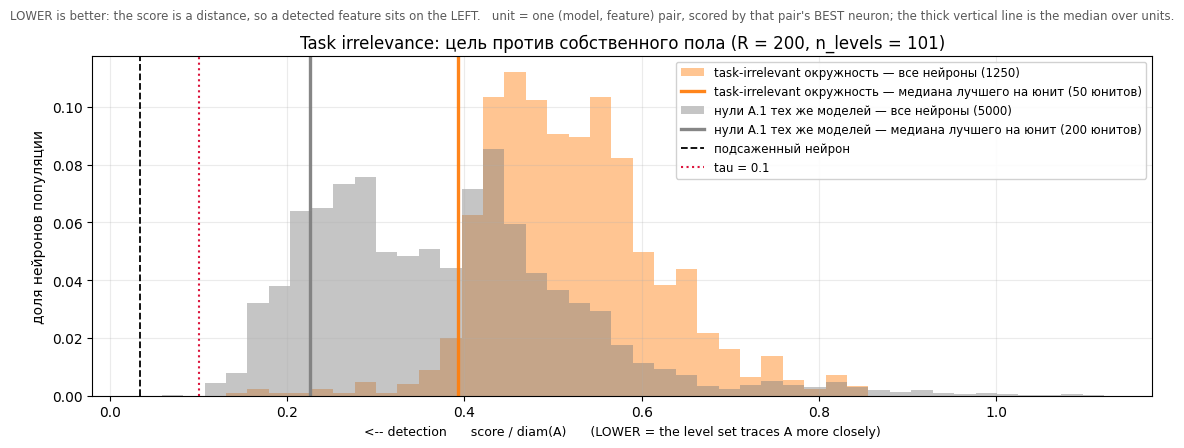

,criterion,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
0,structural,irrelevant,0.3923,0.2259,null_far_right,0.1764,-0.1664,-0.2158,0.1991,0.0,0.005


лучший нейрон ВО ВСЁМ ансамбле (1250 нейронов): 0.1547 = 1.55 tau
нейронов ниже tau: 0 из 1250


In [29]:
# ── C: task-irrelevant окружность против собственного пола ───────────────────
plot_populations(FROZEN, "structural", [
    ("task-irrelevant окружность", {"dataset": "irrelevant", "role": "target"}, "tab:orange"),
    ("нули A.1 тех же моделей",    {"dataset": "irrelevant", "role": "null"},   "0.5"),
], planted=PLANTED_200, threshold=TAU,
   title="Task irrelevance: цель против собственного пола (R = 200, n_levels = 101)",
   save_path=(FIGDIR / "s5_task_irrelevance.png") if SAVE else None)

display(CONTRAST[CONTRAST.dataset == "irrelevant"].round(4))
_i = FROZEN[(FROZEN.criterion == "structural") & (FROZEN.dataset == "irrelevant")
            & (FROZEN.role == "target")]
print(f"лучший нейрон ВО ВСЁМ ансамбле (1250 нейронов): {_i.score.min():.4f} "
      f"= {_i.score.min()/TAU:.2f} tau")
print(f"нейронов ниже tau: {int((_i.score <= TAU).sum())} из {len(_i)}")


**Вывод раздела 5.** Геометрия присутствует в данных, но задаче не нужна — и систематической
детекции не возникает. Медиана лучшего нейрона на модель **0.3923** против пола **0.2259**, то
есть `gap` = **−0.1664**: task-irrelevant окружность набирает **хуже**, чем её же собственная
копия, положенная в другое место. `p_superior` = **0.1991** — случайная целевая единица обходит
случайную нулевую лишь в одном случае из пяти. Свидетеля нет **ни у одной** из 50 моделей, а
лучший нейрон во всём ансамбле из 1250 набирает 0.1547 — в полтора раза выше τ.

Отдельно стоит объяснить, **почему уровень случайности здесь 0.20, а не 0.50.** Если бы «цель, не
нужная задаче» была неотличима от произвольного размещения, `p_superior` был бы около 0.5. Он
ниже, и это согласуется с тем, что мы нашли в разделе про перенос нулей: пол определяется
**разнообразием линий уровня** в окрестности, и оно минимально там, где живёт задача. Целевая
окружность стоит ровно посреди данных — в самой «занятой» области, где линии уровня всех нейронов
согласованы между собой и с границей решения. Это трудное место для случайного совпадения, труднее
трёх из четырёх нулевых размещений. Иначе говоря, 0.20 — это не слабость критерия, а измеренное
свойство места.

Практическое следствие: **уровень случайности нельзя брать равным 0.5 «по умолчанию»** — его
нужно измерять, и здесь он измерен.

## 6. Task relevance

Проанализировать scores на task-relevant feature датасета B и сравнить их с соответствующим null baseline.

**Задача:** показать, что критерий способен обнаруживать геометрию, которая действительно необходима для решения задачи.


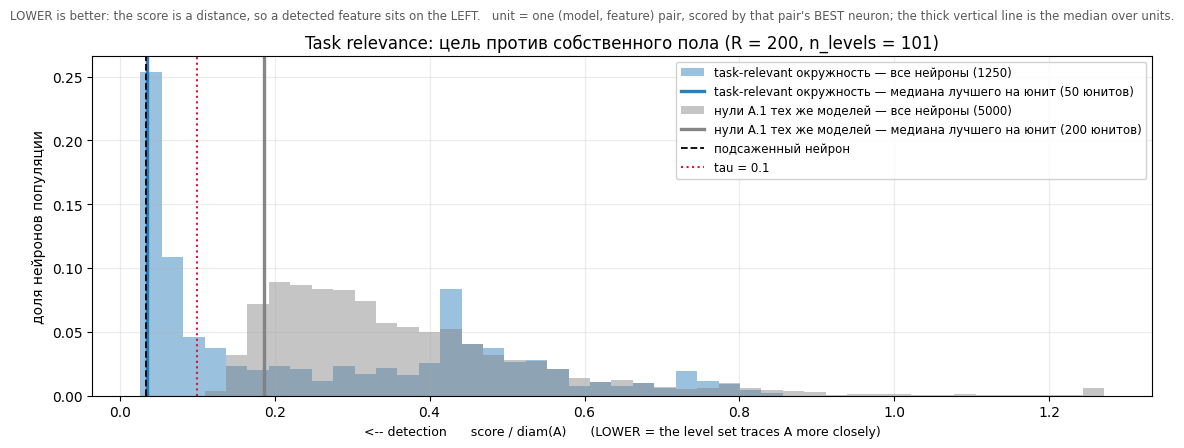

,criterion,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
1,structural,relevant,0.0349,0.1858,null_far_right,0.165,0.1509,0.13,0.9995,0.98,0.0


медиана лучшего нейрона на модель: 0.0349  90 % ДИ [0.0339, 0.0395]   |   подсаженный нейрон: 0.0343
доля ВСЕХ нейронов ниже tau: 0.419
гомологический критерий, независимо:


,criterion,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior
1,homological,relevant,1.6273,-0.0416,null_on_blue_disk,-0.0088,1.6689,1.6361,1.0


In [30]:
# ── D: task-relevant окружность против собственного пола ─────────────────────
plot_populations(FROZEN, "structural", [
    ("task-relevant окружность", {"dataset": "relevant", "role": "target"}, "tab:blue"),
    ("нули A.1 тех же моделей",  {"dataset": "relevant", "role": "null"},   "0.5"),
], planted=PLANTED_200, threshold=TAU,
   title="Task relevance: цель против собственного пола (R = 200, n_levels = 101)",
   save_path=(FIGDIR / "s6_task_relevance.png") if SAVE else None)

display(CONTRAST[CONTRAST.dataset == "relevant"].round(4))
_t = _units[(_units.dataset == "relevant") & (_units.role == "target")].best_score.to_numpy()
_e, _lo, _hi = cal.bootstrap_over_models(list(_t), lambda xs: float(np.median(xs)))
print(f"медиана лучшего нейрона на модель: {_e:.4f}  90 % ДИ [{_lo:.4f}, {_hi:.4f}]"
      f"   |   подсаженный нейрон: {PLANTED_AT:.4f}")
print(f"доля ВСЕХ нейронов ниже tau: "
      f"{(FROZEN[(FROZEN.criterion=='structural') & (FROZEN.dataset=='relevant') & (FROZEN.role=='target')].score <= TAU).mean():.3f}")
print("гомологический критерий, независимо:")
display(CONTRAST_H[CONTRAST_H.dataset == "relevant"].round(4))


**Вывод раздела 6.** Медиана лучшего нейрона на модель — **0.0349** (90 % ДИ 0.0339–0.0395) при
подсаженном нейроне **0.0343**. Это совпадение не случайно и его стоит проговорить: подсаженный
нейрон построен так, что его истинная геометрическая ошибка ≈ 0, поэтому его скор — **потолок
инструмента** при данном разрешении. Задача-релевантная окружность детектируется настолько
хорошо, насколько инструмент вообще способен; выше этого потолка не поднялся бы и идеальный
свидетель.

Отрыв от собственного пола: `gap` = **+0.1509**, `gap_vs_softest` = **+0.1300** (против
`far_right`, самого мягкого размещения), `p_superior` = **0.9995**. Свидетель есть у **49 из 50**
моделей. Ниже τ лежит **41.9 % всех** нейронов ансамбля, а не только лучшие — то есть это
свойство популяции, а не одного удачного нейрона на модель.

Единственная модель без свидетеля — `model21` (0.1304). Она разобрана в «Песочнице»: при 100 %
точности её решающая граница и глубокие линии уровня — **скруглённый квадрат**, топологически
верный и геометрически мимо.

**Гомологический критерий подтверждает независимо и жёстче:** медиана лучшего margin **1.6273**
против пола **−0.0416**, `p_superior` = **1.0000**, и бар нужной размерности нашёлся у **всех 50**
юнитов против 84 % на нулях. Это другой инструмент — он смотрит на контраст, а не на геометрию, —
и он даёт тот же ответ.

## 7. Selectivity

Сравнить scores на task-relevant feature датасета B и task-irrelevant feature датасета A.

**Задача:** показать, что критерий реагирует именно на task relevance, а не просто на наличие или геометрическую форму окружности.


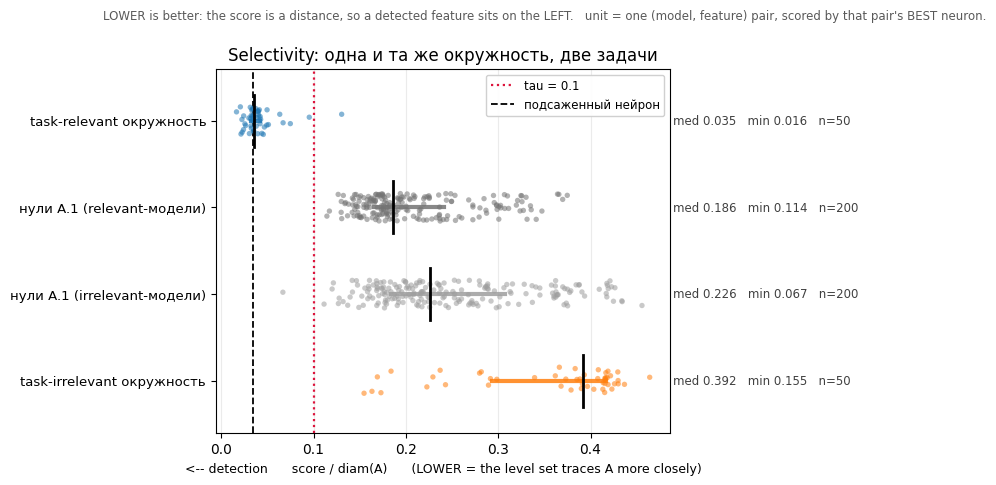

relevant  : медиана 0.0349  худший юнит 0.1304  прошло tau 49/50
irrelevant: медиана 0.3923  лучший юнит 0.1547  прошло tau 0/50
p_superior(relevant над irrelevant) = 1.0000   зазор между худшим relevant и лучшим irrelevant = +0.0243
  доля моделей со свидетелем, relevant  : 0.980  90 % ДИ [0.940, 1.000]
  доля моделей со свидетелем, irrelevant: 0.000  90 % ДИ [0.000, 0.000]


In [31]:
# ── E: тот же круг, две задачи ────────────────────────────────────────────────
#     Единственная картинка, которая содержит весь эксперимент: четыре
#     популяции при замороженной конфигурации, каждая точка — одна пара
#     (модель, фича), то есть лучший нейрон этой пары.
plot_unit_strips(FROZEN, "structural", [
    ("task-relevant окружность",   {"dataset": "relevant",   "role": "target"}, "tab:blue"),
    ("нули A.1 (relevant-модели)", {"dataset": "relevant",   "role": "null"},   "0.45"),
    ("нули A.1 (irrelevant-модели)", {"dataset": "irrelevant", "role": "null"}, "0.62"),
    ("task-irrelevant окружность", {"dataset": "irrelevant", "role": "target"}, "tab:orange"),
], threshold=TAU, planted=PLANTED_AT,
   title="Selectivity: одна и та же окружность, две задачи",
   save_path=(FIGDIR / "s7_selectivity_strips.png") if SAVE else None)

_rel = _units[(_units.dataset == "relevant")   & (_units.role == "target")].best_score.to_numpy()
_irr = _units[(_units.dataset == "irrelevant") & (_units.role == "target")].best_score.to_numpy()

print(f"relevant  : медиана {np.median(_rel):.4f}  худший юнит {_rel.max():.4f}  "
      f"прошло tau {int((_rel <= TAU).sum())}/50")
print(f"irrelevant: медиана {np.median(_irr):.4f}  лучший юнит {_irr.min():.4f}  "
      f"прошло tau {int((_irr <= TAU).sum())}/50")
print(f"p_superior(relevant над irrelevant) = "
      f"{cal.superiority_probability(_rel, _irr):.4f}   "
      f"зазор между худшим relevant и лучшим irrelevant = {_irr.min() - _rel.max():+.4f}")
for _name, _v in [("relevant", _rel), ("irrelevant", _irr)]:
    _e, _lo, _hi = cal.bootstrap_over_models(
        list(_v), lambda xs: float(np.mean([x <= TAU for x in xs])))
    print(f"  доля моделей со свидетелем, {_name:10s}: {_e:.3f}  90 % ДИ [{_lo:.3f}, {_hi:.3f}]")


**Вывод раздела 7.** Окружность в двух датасетах побитово одна и та же — те же 500 точек, тот
же радиус, то же место. Различается только то, нужна ли она задаче.

| | task-relevant | task-irrelevant |
|---|---|---|
| медиана лучшего нейрона на модель | **0.0349** | **0.3923** |
| моделей со свидетелем при τ = 0.1 | **49 / 50** (90 % ДИ 0.94–1.00) | **0 / 50** (ДИ 0.00–0.00) |
| худший / лучший юнит | 0.1304 | 0.1547 |

**Разделение полное.** `p_superior = 1.0000`: худшая relevant-модель (0.1304) лучше, чем лучшая
irrelevant-модель (0.1547), с зазором **+0.0243**. Ни одна из 2 500 пар не пересекается — это не
«статистически значимое различие», а два непересекающихся множества.

Существенно, что при этом **полы у двух ансамблей близки** — 0.1858 против 0.2259. То есть
relevant-сети не «богаче линиями уровня вообще»: случайную окружность на стороне они ловят
примерно так же плохо, как и irrelevant-сети. Отличается ровно одно место — то, где окружность
нужна для решения задачи.

Это и есть основной научный результат ноутбука: **критерий реагирует на task relevance, а не на
наличие геометрии.**


## 8. Numerical stability and frozen methodological specification

Обобщить результаты всех предыдущих разделов и определить область устойчивости по `resolution`, `n_levels` и `level_eps`.

Проверить, что при изменении гиперпараметров:
- scores не меняются существенно в пределах заранее заданной численной погрешности;
- сохраняются выводы о null, task-irrelevant и task-relevant features;
- сохраняется их качественное соотношение.

Выбрать рабочую конфигурацию из устойчивой области и зафиксировать её как `DetectorSpec` для всех последующих экспериментов.



In [ ]:
# ── F: держатся ли выводы разделов 4-7 во ВСЕХ точках обоих свипов ──────────
#     Разделы 4-7 отчитались при одной конфигурации. Здесь проверяется, что
#     выбор этой конфигурации ничего не решил: каждое утверждение проверяется
#     во всех пяти разрешениях и всех шести значениях n_levels.
if "nl" not in globals():
    nl = cal.read_scores_csv(NL_SWEEP_CSV)

def stability_grid(scores, axis, threshold=TAU):
    """Одна строка на точку свипа: все отчётные величины разом."""
    s = scores[scores.criterion == "structural"]
    con = cal.sweep_contrast(s, by=("criterion", axis, "dataset"), threshold=threshold)
    sel = cal.selectivity(s, by=(axis,), threshold=threshold)
    rel = con[con.dataset == "relevant"].set_index(axis)
    irr = con[con.dataset == "irrelevant"].set_index(axis)
    return pd.DataFrame({
        "доля relevant":        rel.target_rate,
        "доля irrelevant":      irr.target_rate,
        "ложных на нулях rel":  rel.null_rate,
        "ложных на нулях irr":  irr.null_rate,
        "p_sup relevant":       rel.p_superior,
        "p_sup irrelevant":     irr.p_superior,
        "gap relevant":         rel.gap,
        "gap irrelevant":       irr.gap,
        "p_sup selectivity":    sel.set_index(axis).p_superior,
        "зазор selectivity":    sel.set_index(axis).margin,
        "мягчайшее размещение": rel.null_softest.str.replace("null_", "", regex=False),
    })

GRID_RES = stability_grid(ens, "resolution")
GRID_NL  = stability_grid(nl,  "n_levels")
print("по resolution (n_levels = 101):"); display(GRID_RES.round(4))
print("по n_levels (R = 200):");          display(GRID_NL.round(4))

_all = pd.concat([GRID_RES, GRID_NL])
print(f"конфигураций проверено: {len(_all)}")
print(f"  доля irrelevant  : всегда {sorted(_all['доля irrelevant'].unique())}")
print(f"  ложных на нулях relevant: всегда {sorted(_all['ложных на нулях rel'].unique())}")
print(f"  доля relevant    : от {_all['доля relevant'].min():.2f} до {_all['доля relevant'].max():.2f}")
print(f"  p_sup relevant   : от {_all['p_sup relevant'].min():.4f} до {_all['p_sup relevant'].max():.4f}")
print(f"  gap relevant > 0 : {(_all['gap relevant'] > 0).all()}   |   "
      f"gap irrelevant < 0: {(_all['gap irrelevant'] < 0).all()}")
print(f"  полное разделение (p_sup selectivity = 1): "
      f"{int((_all['p_sup selectivity'] >= 1.0).sum())} из {len(_all)} конфигураций")


**Вывод раздела 8: выбор конфигурации не решил ничего.**

Одиннадцать строк — пять разрешений при `n_levels = 101` и шесть значений `n_levels` при
R = 200, из них рабочая точка (R = 200, `n_levels` = 101) общая, то есть **десять различных
конфигураций**. В каждой проверены все отчётные величины разделов 4–7.

| | по resolution 25→400 | по n_levels 6→401 |
|---|---|---|
| доля relevant-моделей со свидетелем | 0.86 → 0.98 | 0.92 → 0.98 |
| **доля irrelevant-моделей** | **0.00 везде** | **0.00 везде** |
| ложных срабатываний на нулях relevant | **0 везде** | **0 везде** |
| ложных срабатываний на нулях irrelevant | 0 … 0.005 | 0 … 0.015 |
| `p_superior` relevant | 0.9835 → 0.9995 | 0.9907 → 0.9993 |
| `p_superior` irrelevant | 0.186 … 0.209 | 0.194 … 0.201 |
| `gap` relevant | всегда **> 0** | всегда **> 0** |
| `gap` irrelevant | всегда **< 0** | всегда **< 0** |

**Ни одного исключения ни в одной конфигурации.** Ноль ложных свидетелей на task-irrelevant
окружности — это 500 пар (модель, конфигурация) подряд. Знак `gap` не меняется нигде: цель
всегда лучше своего пола на relevant и всегда хуже него на irrelevant.

**Полное разделение — утверждение более сильное, и оно требует минимума разрешения.**
`p_superior` между двумя целями равен **1.0000** в восьми строках из одиннадцати; не дотягивают
три: R = 25 (зазор −0.0870), R = 50 (−0.0024, то есть популяции ровно соприкасаются) и
`n_levels` = 6 (−0.0418). Иначе говоря, **разделение полное при R ≥ 100 и `n_levels` ≥ 26**, а
ниже этого популяции перекрываются — на две модели при R = 25 и буквально на одну точку при
R = 50. Существенно, что даже там, где перекрытие есть, все остальные утверждения держатся:
доля irrelevant по-прежнему 0.00, знаки `gap` те же, `p_superior` relevant 0.98+.

Мягчайшее размещение пола — `far_right` в девяти конфигурациях из десяти (`on_blue_disk` на двух
краях сетки, R = 25 и `n_levels` = 401).

**Что от параметров всё-таки зависит** — и это ровно то, о чём предупреждали разделы 2 и 4:
абсолютный уровень пола (`gap` relevant гуляет 0.132…0.192), число ложных срабатываний на нулях
(0…3 из 200) и абсолютный уровень скора. Не зависит ничего из того, что мы отчитываем: ни один
знак, ни один порядок, ни один вердикт.

### Замороженная методологическая спецификация

```python
# структурный критерий
resolution   = 200          # или, для другого масштаба: N_A = diam(A)/max(h) ≈ 40, по числу на ось
n_levels     = 101          # дефолт structural_criterion
levels       = linspace(min f, max f, n_levels)    # activation=None: наблюдённый размах
level_eps    = "adaptive"   # с нижней отсечкой 0.5·range(f)/(n_levels − 1)
threshold τ  = 0.1          # score / diam(A)
kind         = "pre"        # соглашение проекта

# гомологический критерий
backend           = "delaunay"
max_sample_points = 7000    # > числа точек сетки в окне; при другом N_A пересчитать как ≈ 1.8·N_A²

# протокол отчётности
единица наблюдения = пара (модель, фича), её значение — лучший нейрон пары
пол                = распределение по размещениям A.1; вердикт сравнивается с самым мягким
нули               = минимум два размещения в разных направлениях от цели, обе вдали от границы решения
```

Спецификация проверяется машинно: `cal.check_conventions(SPEC.eval)` сверяет её с тем, что
реально стоит в `EXPERIMENTS["exp1_sanity_check"]`, и падает, если они разошлись.

## 9. Summary

Сводная таблица по критериям и выбранной конфигурации гиперпараметров.

Зафиксировать:
- рабочие значения `resolution`, `n_levels`, `level_eps`;
- evidence for detector validity;
- false-positive baseline;
- результаты для task-irrelevant и task-relevant features;
- итоговый вывод о selectivity.

**После этого `DetectorSpec` считается замороженным и не изменяется в последующих экспериментах.**

In [ ]:
# ── Сводка: одна строка на утверждение ──────────────────────────────────────
_rows = []
for _ds, _label in [("relevant", "task-relevant"), ("irrelevant", "task-irrelevant")]:
    _c = CONTRAST[CONTRAST.dataset == _ds].iloc[0]
    _t = _units[(_units.dataset == _ds) & (_units.role == "target")].best_score
    _rows.append({
        "датасет": _label,
        "медиана цели": _c.target_median,
        "медиана пола": _c.null_median,
        "gap": _c.gap,
        "gap vs softest": _c.gap_vs_softest,
        "p_superior": _c.p_superior,
        "моделей со свидетелем": f"{int((_t <= TAU).sum())}/50",
        "лучший юнит": _t.min(),
        "худший юнит": _t.max(),
    })
display(pd.DataFrame(_rows).round(4))

_sel = cal.selectivity(FROZEN[FROZEN.criterion == "structural"], threshold=TAU).iloc[0]
print(f"selectivity: p_superior = {_sel.p_superior:.4f}, "
      f"зазор между популяциями = {_sel.margin:+.4f} "
      f"({'не пересекаются' if _sel.margin > 0 else 'перекрываются'})")
print(f"подсаженный нейрон (потолок инструмента) = {PLANTED_AT:.4f} "
      f"при истинной ошибке {float(PLANTED_200[PLANTED_200.criterion=='structural'].ideal_score.iloc[0]):.4f}")
print()
display(cal.conventions_table())
display(cal.check_conventions(SPEC.eval))


### Итог калибровки

**Что установлено.** Одна и та же окружность — те же 500 точек, тот же радиус, то же место —
детектируется у **49 из 50** моделей, когда она нужна задаче, и у **0 из 50**, когда не нужна.
Популяции не пересекаются: `p_superior = 1.0000`, зазор между худшей relevant-моделью и лучшей
irrelevant-моделью **+0.0243**. Ложных срабатываний на нулях A.1 — **1 юнит из 400**. Всё это
устойчиво по всем десяти протестированным конфигурациям (раздел 8).

**Три опоры шкалы, каждая измерена, а не назначена:**

| рунг | что это | значение |
|---|---|---|
| заведомый свидетель (не потолок, см. поправку в разделе A) | подсаженный нейрон, истинная ошибка 0.0016 | **0.0343** |
| порог | τ, назначен заранее | **0.1** |
| пол | нули A.1, медиана по размещениям | **0.165 … 0.368** |

Медиана task-relevant цели (**0.0349**) совпадает со значением на заведомом свидетеле; медиана task-irrelevant
цели (**0.3923**) — за полом, то есть **хуже**, чем копия той же окружности, положенная в
случайное место.

**Чего калибровка НЕ даёт.**

* Она не про величину эффекта и не про то, что на неё влияет: вердикт бинарен, «есть фича или
  нет». Зависимость скора от геометрии — предмет отдельного эксперимента (заготовка лежит в
  песочнице).
* Пол **не переносится** на другую задачу, другую архитектуру, другую форму фичи и другую
  множественность. Мерить его надо в каждом эксперименте заново; переносится конструкция набора
  нулей, а не его числа.
* Уровень случайности здесь **0.20, а не 0.50** — это свойство места, где стоит цель, и его
  тоже надо мерить, а не предполагать.
* Порог применим только там, где инструмент проходит собственную проверку: при `N_A < 6`
  подсаженный нейрон не проходит τ, и отрицательный ответ критерия там не значит ничего.

### Что переносится в следующие эксперименты

**1. Не `resolution = 200`, а `N_A ≈ 40`.** Двести — число этого бокса и этой окружности, оно не
переносится никуда: при другом боксе или другом размере фичи те же двести точек означают другую
дискретизацию. Переносится безразмерная величина — **сколько шагов сетки укладывается в диаметр
фичи**, `N_A = diam(A) / max(h_x, h_y)`. Именно по ней читается весь свип: при `N_A ≈ 22`
порядковый вердикт уже устойчив, при `N_A ≈ 44` устойчив и счётный, при `N_A ≈ 89` не меняется
ничего, а при `N_A < 6` подсаженный нейрон не проходит собственный порог и любой отрицательный
ответ бессмыслен. Рабочая точка — 40, и считать её надо **по одному числу на ось**, иначе одна
ось окажется переплачена (у нас бокс вытянут в 1.8 раза, и по `y` мы считаем 1.8 лишней точки на
каждую полезную):

```python
h = diam(A) / 40
resolution = tuple(int(np.ceil((b - a) / h)) + 1 for a, b in BOUNDS)
```

Вместе с этим по масштабу пересчитывается `max_sample_points` гомологического критерия: точек
сетки в его окне примерно `1.8·N_A²`, то есть ≈ 2 800 при `N_A = 40`; наши 7 000 покрывают это с
запасом, но при существенно большем `N_A` значение надо поднять. Остальное в спецификации
безразмерно и переносится как есть: τ (это доля `diam(A)`), `n_levels` (доля размаха самого
нейрона), adaptive ε (масштабируется с сеткой сам), `neighborhood_factor` (задан в радиусах фичи).

**2. Минимальный набор нулей — два размещения, но не любые два.** Пол зависит не от расстояния до
данных, а от **направления**: `far_right` и `above_target` стоят на одном и том же расстоянии 3.5
от центра цели и различаются на 47 %. Поэтому оба размещения берутся **вдали от границы решения**
(там разнообразие линий уровня максимально и пол мягче всего — именно он связывает вердикт) и в
**двух разных направлениях от цели**: вдоль оси задачи и поперёк неё. Второе — не дубль, а
проверка того, что мягкое направление найдено. Третье размещение, в коридоре у границы решения,
нужно только если отчитываться шириной пола: оно даёт жёсткий конец и вердикт не связывает
никогда. Каждое размещение проходит проверку допустимости `field_grad_norm_on_feature` — в
мёртвой области получится не мягкий пол, а отсутствие измерения. И сигнал тревоги: если два
размещения дали пол, совпадающий с точностью до нескольких процентов, они, скорее всего, попали
в один режим, и покрытия нет — нужен третий.

**3. Протокол сравнения.** Долю свидетелей при ширине W сравнивать только с полом, измеренным
**при той же ширине** (пол падает с числом попыток как ≈ `N^(−0.28)`, и рост доли свидетелей с
шириной частично воспроизводится полом). Единица наблюдения — пара (модель, фича), её значение —
лучший нейрон пары. Вердикт сравнивается с самым мягким размещением, а не со средним по полу.

---
## Песочница

Разбор отдельных моделей руками. Ничего отсюда не идёт в отчёт — это место,
где смотрят глазами на то, что таблицы показали числом.

In [32]:
# ── Кто из relevant-моделей НЕ проходит tau? Ищем в уже посчитанной таблице,
#     а не вписываем путь руками — иначе при перепрогоне свипа он протухнет.
SANDBOX_RES = 200

_best = cal.best_per_unit(ens[ens.criterion == "structural"], lower_is_better=True,
                          unit=("model_path", "feature", "resolution", "dataset"))
miss = (_best[(_best.dataset == "relevant") & (_best.role == "target")
              & (_best.resolution == SANDBOX_RES) & (_best.best_score > TAU)]
        .sort_values("best_score", ascending=False))
display(miss[["model_path", "best_score"]])
assert len(miss), f"при R={SANDBOX_RES} все relevant-модели прошли tau"

BAD = miss.model_path.iloc[0]
print("разбираем:", BAD)

# Как она выглядит по обоим критериям на всех разрешениях.
_m = ens[(ens.model_path == BAD) & (ens.feature == "relevant")]
_agg = []
for (cname, res), g in _m.groupby(["criterion", "resolution"]):
    sc = g["score"].dropna()
    _agg.append({"criterion": cname, "resolution": res,
                 "best": (sc.min() if cal.DIRECTIONS[cname] else sc.max())
                          if len(sc) else float("nan")})
display(pd.DataFrame(_agg).pivot(index="criterion", columns="resolution",
                                 values="best").round(4))
for cname, lower in (("structural", True), ("homological", False)):
    g = _m[(_m.criterion == cname) & (_m.resolution == SANDBOX_RES)]
    g = g.sort_values("score", ascending=lower).head(5)
    print(f"\n{cname}: 5 лучших нейронов при R={SANDBOX_RES}")
    print(g[["layer_id", "coord_id", "score", "is_witness"]].to_string(index=False))

,model_path,best_score
1820,models/runs/simple_relevant/simple_relevant_0/...,0.1304


разбираем: models/runs/simple_relevant/simple_relevant_0/simple_relevant_0_tanh_w5_d5_mass-train_model21


resolution,25,50,100,200,400
criterion,,,,,
homological,0.4323,0.4712,0.4768,0.4766,0.4785
structural,0.2635,0.1746,0.1390,0.1304,0.1308



structural: 5 лучших нейронов при R=200
 layer_id  coord_id    score  is_witness
        3         2 0.130400       False
        3         4 0.133045       False
        3         3 0.142772       False
        4         3 0.181702       False
        4         1 0.188568       False

homological: 5 лучших нейронов при R=200
 layer_id  coord_id     score  is_witness
        4         4  0.476648        True
        4         3  0.419463        True
        1         1 -0.059053       False
        1         2 -0.078725       False
        3         1 -0.117003       False


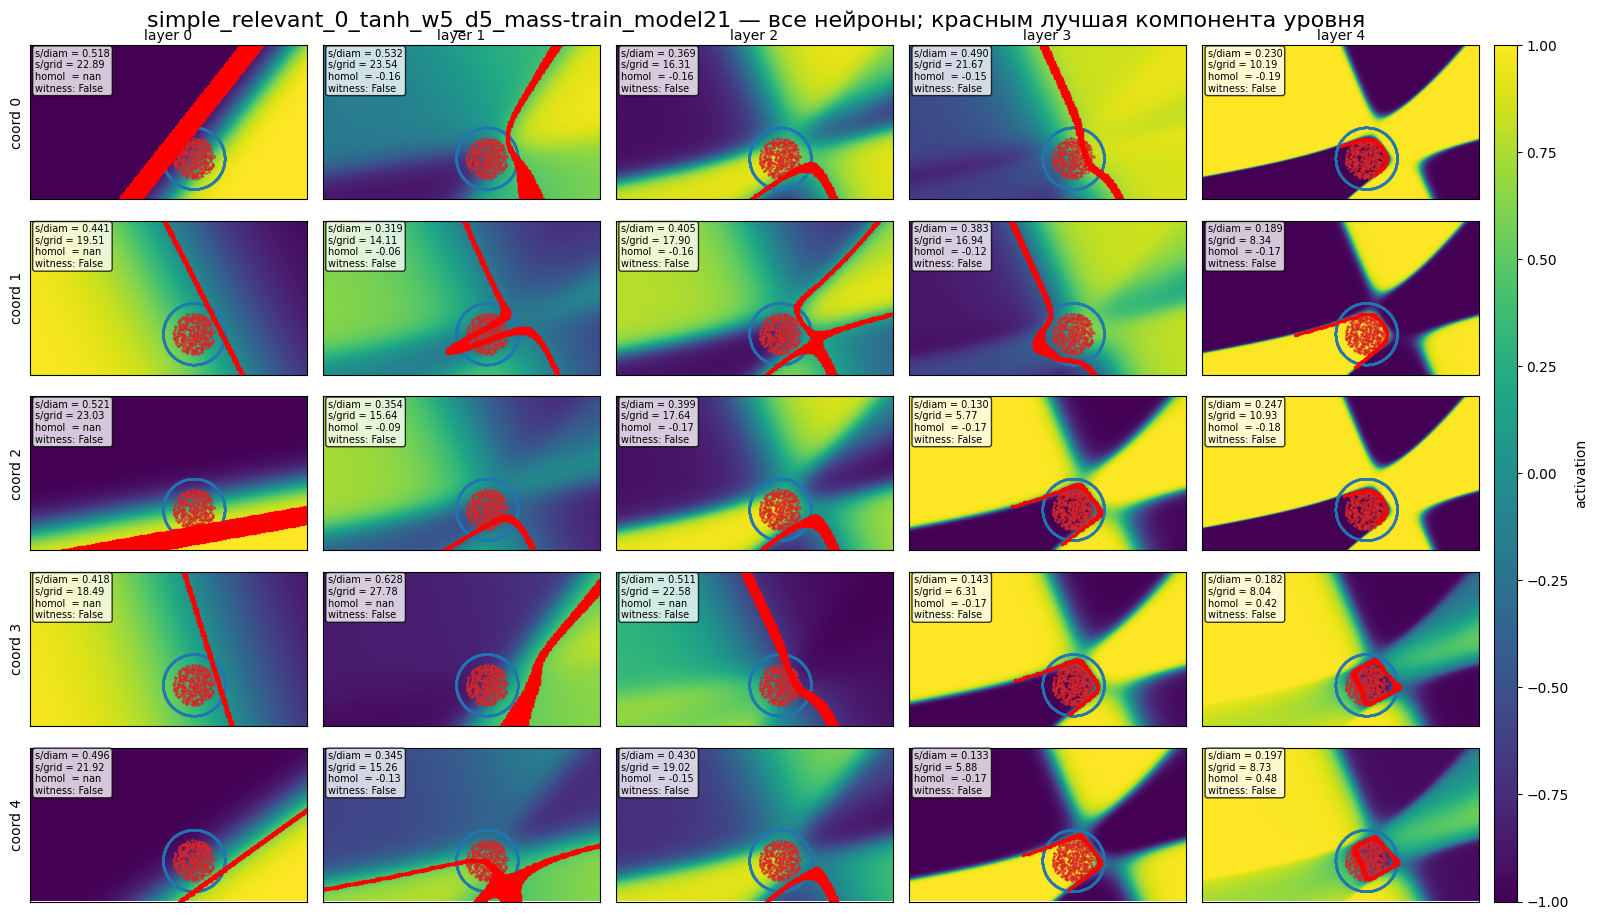

In [33]:
# ── Все нейроны этой модели: поле + данные + лучшая компонента уровня ────────
#     Тот же бокс и то же разрешение, что в свипе, иначе картинка объясняет
#     не то число, которое стоит в таблице.
from analysis.criterions import evaluate_neurons_on_feature
from visualization.plot_point_clouds import plot_all_hidden_neuron_fields_2d_with_criteria
from experiments import runner

bad_model, _ = load_model_instance(BAD)
d_rel = load_dataset_instance("data/dataset_instances/simple_relevant/simple_relevant_0/",
                              reconstruct_data=False)

rows_bad = evaluate_neurons_on_feature(
    model=bad_model,
    feature_points=FEATURES["relevant"]["relevant"],
    bounds=BOUNDS,
    resolution=SANDBOX_RES,
    kinds=SPEC.eval.kinds,
    structural_kwargs={**SPEC.eval.structural_kwargs,
                       "return_best_component_points": True},
    run_structural=True,
    run_tubular=False,
    extra_criteria=runner._resolve_extra_criteria(SPEC.eval) or None,
    return_full_result_structural=True,
    verbose=False,
)

_ = plot_all_hidden_neuron_fields_2d_with_criteria(
    bad_model, rows_bad, BOUNDS,
    X=d_rel["X"], y=d_rel["y"],
    kind=SPEC.eval.kinds[0],
    resolution=SANDBOX_RES,
    title=f"{BAD.split('/')[-1]} — все нейроны; красным лучшая компонента уровня")

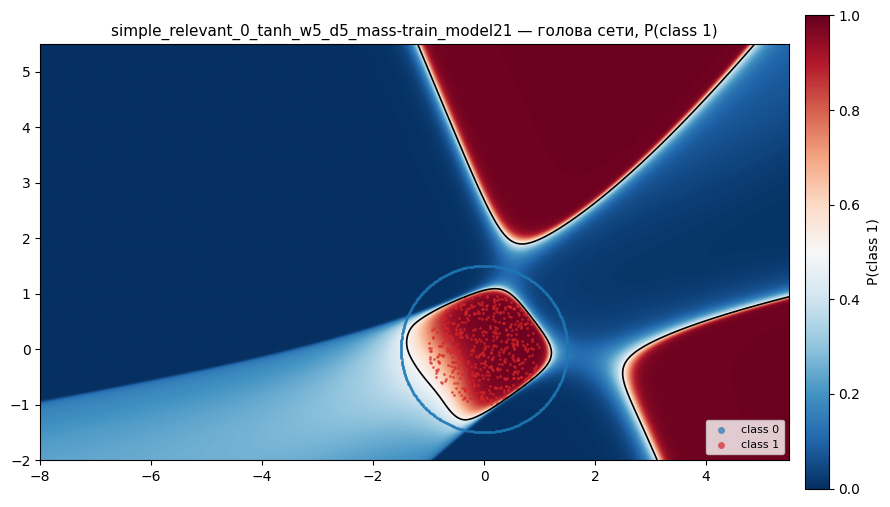

In [34]:
# ── Голова той же сети: то, что модель реально вычисляет ─────────────────────
#     Нейроны наследуют форму от неё, поэтому смотреть их в отрыве от головы
#     бессмысленно. Граница решения здесь — скруглённый квадрат, и ровно эту
#     форму повторяют множества уровня в слоях 3-4.
from visualization.plot_point_clouds import plot_decision_boundary_2d

_ = plot_decision_boundary_2d(
    bad_model, BOUNDS, X=d_rel["X"], y=d_rel["y"], resolution=400,
    title=f"{BAD.split('/')[-1]} — голова сети, P(class 1)")

эталон: models/runs/simple_relevant/simple_relevant_0/simple_relevant_0_tanh_w5_d5_mass-train_model18


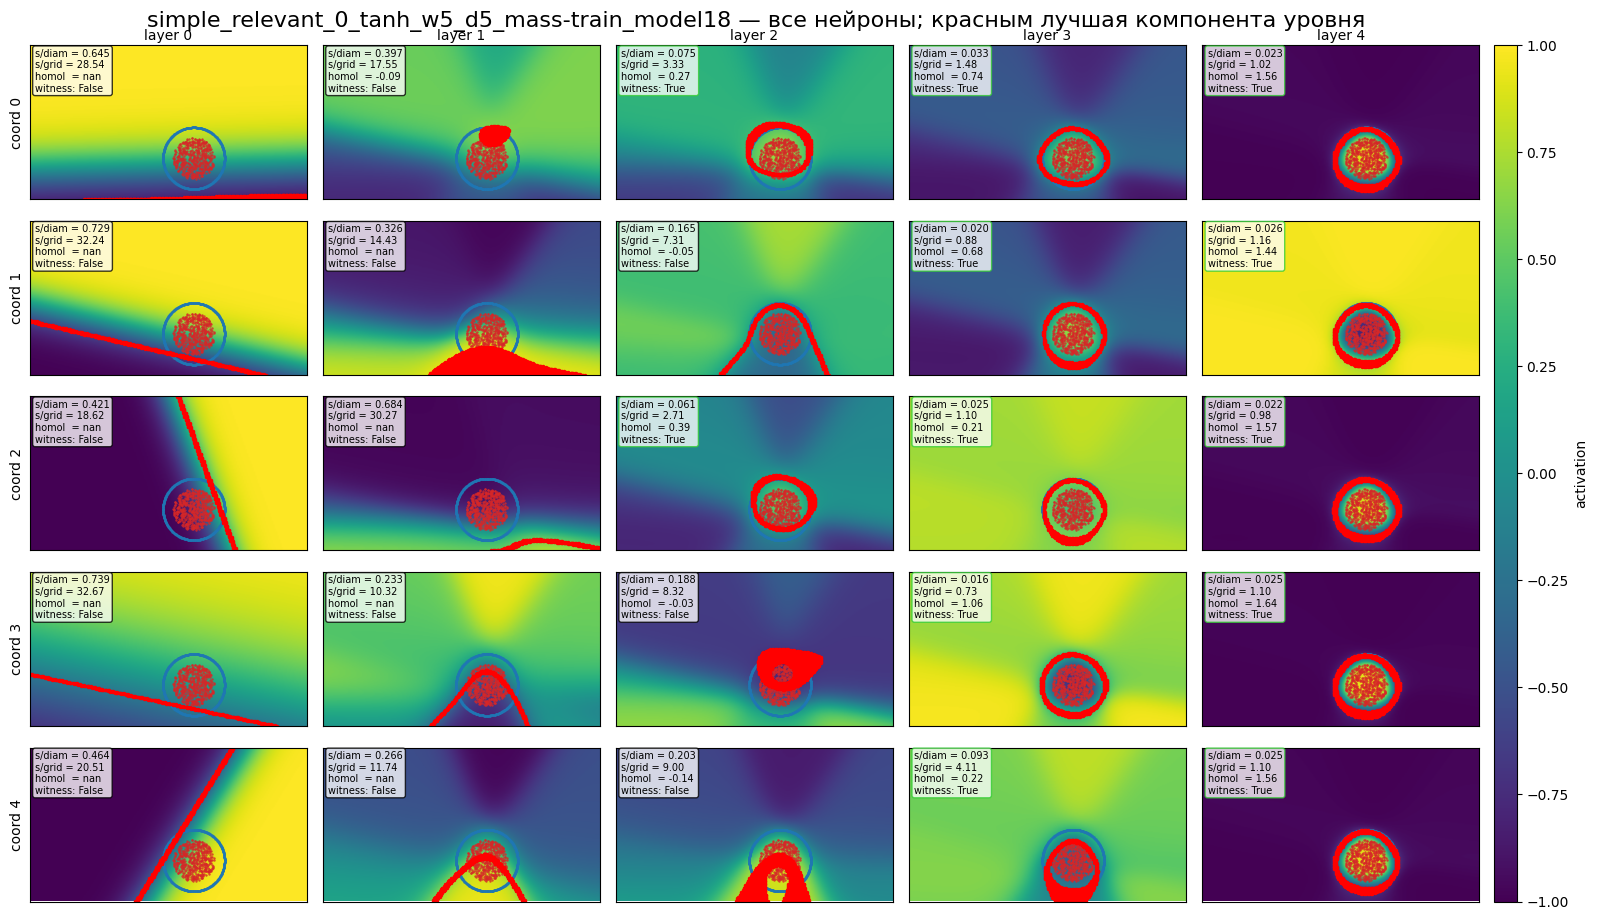

In [35]:
# ── Для сравнения: лучшая relevant-модель тем же взглядом ───────────────────
GOOD = (_best[(_best.dataset == "relevant") & (_best.role == "target")
              & (_best.resolution == SANDBOX_RES)]
        .sort_values("best_score").model_path.iloc[0])
print("эталон:", GOOD)

good_model, _ = load_model_instance(GOOD)
rows_good = evaluate_neurons_on_feature(
    model=good_model,
    feature_points=FEATURES["relevant"]["relevant"],
    bounds=BOUNDS, resolution=SANDBOX_RES, kinds=SPEC.eval.kinds,
    structural_kwargs={**SPEC.eval.structural_kwargs,
                       "return_best_component_points": True},
    run_structural=True, run_tubular=False,
    extra_criteria=runner._resolve_extra_criteria(SPEC.eval) or None,
    return_full_result_structural=True, verbose=False,
)
_ = plot_all_hidden_neuron_fields_2d_with_criteria(
    good_model, rows_good, BOUNDS, X=d_rel["X"], y=d_rel["y"],
    kind=SPEC.eval.kinds[0], resolution=SANDBOX_RES,
    title=f"{GOOD.split('/')[-1]} — все нейроны; красным лучшая компонента уровня")

In [36]:
# ── Единственное ложное срабатывание: нейрон, поймавший НУЛЬ ─────────────────
#     Ищем по всей таблице сразу, по всем разрешениям и датасетам.
fp = ens[(ens.criterion == "structural") & (ens.role == "null") & (ens.score <= TAU)]
display(fp[["resolution", "dataset", "feature", "model_path", "layer_id", "coord_id",
            "score", "best_level_eps"]].sort_values(["resolution", "score"]))
assert len(fp), "ложных срабатываний на нулях нет"

_r = fp[fp.resolution == SANDBOX_RES].sort_values("score").iloc[0]
FP_MODEL, FP_FEATURE = _r.model_path, _r.feature
FP_L, FP_C = int(_r.layer_id), int(_r.coord_id)
print(f"\n{FP_MODEL}")
print(f"  фича {FP_FEATURE}, нейрон L{FP_L}n{FP_C}, скор {_r.score:.4f} при tau={TAU}")

,resolution,dataset,feature,model_path,layer_id,coord_id,score,best_level_eps
52200,100,irrelevant,null_above_target,models/runs/simple_irrelevant/simple_irrelevan...,1,4,0.073420,0.006701
77200,200,irrelevant,null_above_target,models/runs/simple_irrelevant/simple_irrelevan...,1,4,0.066721,0.005138
102200,400,irrelevant,null_above_target,models/runs/simple_irrelevant/simple_irrelevan...,1,4,0.067337,0.005138



models/runs/simple_irrelevant/simple_irrelevant_0/simple_irrelevant_0_tanh_w5_d5_mass-train_model24
  фича null_above_target, нейрон L1n4, скор 0.0667 при tau=0.1


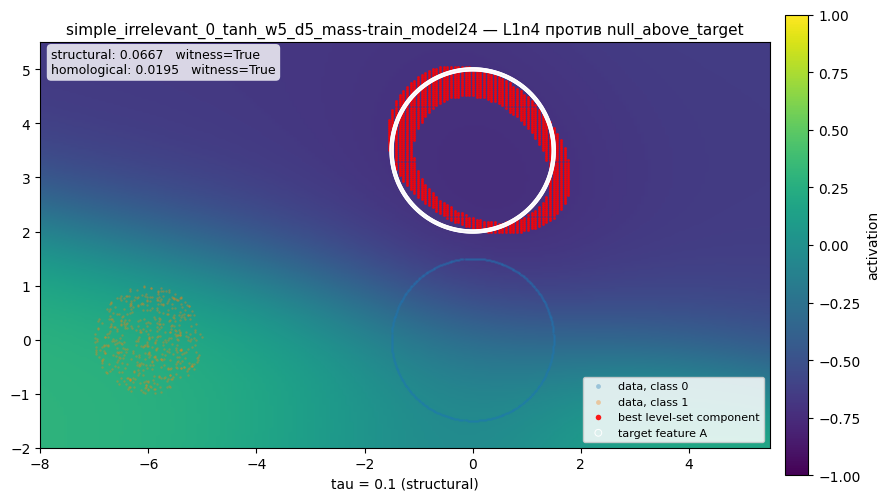

In [37]:
# ── Тот самый нейрон крупно ──────────────────────────────────────────────────
#     Белым — сама null-фича. Нуль это жёсткая копия цели, положенная в другое
#     место, в данных его нет, поэтому без белой окружности картинку не прочесть.
fp_model, _ = load_model_instance(FP_MODEL)
fp_probe = cal.trained_probe(fp_model, FP_L, FP_C, FEATURES["irrelevant"][FP_FEATURE])

_ = plot_probe_field(
    fp_probe, BOUNDS, SANDBOX_RES, criteria_specs=CRITS, threshold=TAU,
    X=DATA["irrelevant"]["X"], y=DATA["irrelevant"]["y"],
    title=f"{FP_MODEL.split('/')[-1]} — L{FP_L}n{FP_C} против {FP_FEATURE}")

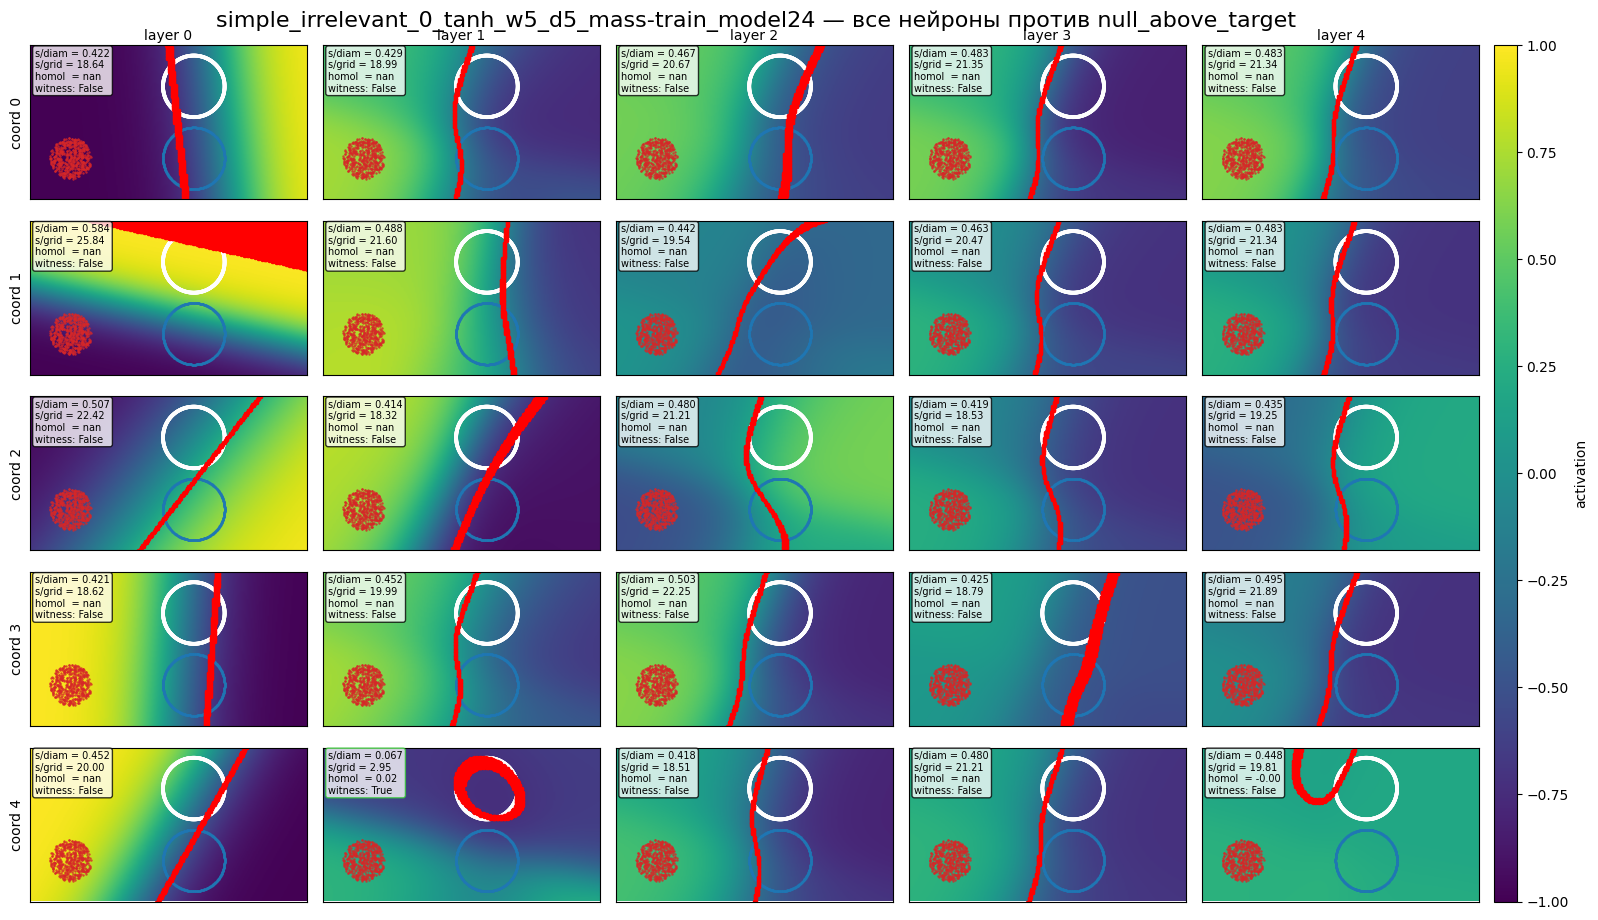

In [38]:
# ── Все нейроны той же модели против того же нуля ────────────────────────────
rows_fp = evaluate_neurons_on_feature(
    model=fp_model,
    feature_points=FEATURES["irrelevant"][FP_FEATURE],
    bounds=BOUNDS,
    resolution=SANDBOX_RES,
    kinds=SPEC.eval.kinds,
    structural_kwargs={**SPEC.eval.structural_kwargs,
                       "return_best_component_points": True},
    run_structural=True,
    run_tubular=False,
    extra_criteria=runner._resolve_extra_criteria(SPEC.eval) or None,
    return_full_result_structural=True,
    verbose=False,
)

_ = plot_all_hidden_neuron_fields_2d_with_criteria(
    fp_model, rows_fp, BOUNDS,
    X=DATA["irrelevant"]["X"], y=DATA["irrelevant"]["y"],
    feature_points=FEATURES["irrelevant"][FP_FEATURE],
    kind=SPEC.eval.kinds[0], resolution=SANDBOX_RES,
    title=f"{FP_MODEL.split('/')[-1]} — все нейроны против {FP_FEATURE}")

#### Откуда у нейрона слоя 1 вообще замкнутая линия уровня

Вопрос законный: у нейрона **слоя 0** замкнутых линий уровня не бывает в принципе. Он
равен $\tanh(a\cdot x+b)$, постоянен на прямых $a\cdot x=\text{const}$, и его множества
уровня — параллельные прямые.

Нейрон **слоя 1** устроен иначе:

$$f(x)=\tanh\big(g(x)\big),\qquad g(x)=\sum_{i=1}^{5} w_i\,\tanh(a_i\cdot x+b_i)+b .$$

Поскольку $\tanh$ строго монотонен, множества уровня $f$ — это в точности множества уровня
$g$. Значит вопрос сводится к тому, может ли **сумма пяти гребневых функций** иметь
замкнутую линию уровня. Может, и по двум независимым причинам.

**Конструктивно.** Пара $\tanh$ с противоположными знаками вдоль одного направления $u$
даёт «полосу»:
$\tanh\!\big(s(u\cdot x+\delta)\big)-\tanh\!\big(s(u\cdot x-\delta)\big)$ — высоко внутри
полосы ширины $2\delta$, низко снаружи. Две такие пары вдоль двух независимых направлений
дают функцию, высокую только в пересечении полос, то есть бугор с замкнутыми линиями
уровня формы скруглённого параллелограмма. На это уходит 4 нейрона слоя 0, при ширине 5
один остаётся в запасе. Это ровно конструкция `plant_radial_neuron`
(`analysis/controls.py:302`), где число направлений $k=3$ при `hidden_dim >= 6` и $k=2$
иначе.

**Теоретически — и это более сильное утверждение.** Гессиан:

$$\nabla^2 g(x)=\sum_i w_i\,\tanh''(a_i\cdot x+b_i)\,a_i a_i^{\mathsf T},
\qquad \tanh''(z)=-2\tanh(z)\,\mathrm{sech}^2(z).$$

Каждое слагаемое — матрица ранга 1 со знаком. Сумма таких матриц вполне может быть
отрицательно определённой: достаточно двух слагаемых с линейно независимыми $a_i$ и
подходящими знаками. Значит у $g$ бывает невырожденный локальный максимум $x^{*}$. А по
лемме Морса рядом с невырожденной критической точкой

$$g(x)\approx g(x^{*})+\tfrac12 (x-x^{*})^{\mathsf T} H\,(x-x^{*}),$$

и множества уровня в окрестности — **эллипсы** с осями по собственным векторам $H$. Круг
получается, только если у $H$ кратное собственное значение, а это условие коразмерности 2:
у обученной сети оно не выполняется никогда.

Правильный ответ поэтому такой: **замкнутая линия уровня у нейрона слоя 1 не просто
возможна — она типична, и типичная её форма именно эллипс, а не круг.** Кругов тут ждать
и не приходится: при ширине 5 в слое 0 набирается максимум 2 независимых направления
бугра, а для изотропии в этой конструкции нужно 3 — только тогда гармоники $\cos 2\theta$
и $\cos 4\theta$ сокращаются и линии уровня становятся кругами с точностью до 6-го
порядка.

**Почему тогда критерий сработал.** Скор — это max-симметризованное среднее расстояние
Чамфера между компонентой и точками фичи, делённое на $\mathrm{diam}(A)\approx 3.0$.
Значение 0.0667 отвечает сырому расстоянию около 0.20 при радиусе окружности 1.5. Эллипс,
у которого полуоси отличаются процентов на десять, уже попадает в этот диапазон — и часть
этого расстояния съедает сама толщина $\varepsilon$-слоя, а не форма. То есть срабатывание
не требует ничего экзотического: достаточно бугра подходящего размера, оказавшегося
примерно в нужном месте.

**И это не дефект критерия.** Он сообщил ровно то, что есть: у этого нейрона
действительно существует линия уровня, обходящая окружность нуля с точностью 6.7 % её
диаметра. Ровно для того, чтобы измерить частоту таких совпадений, и нужен пол A.1 —
измеренная частота равна 1 на 200 единиц.

**Побочное наблюдение с той же картинки.** Нуль лежит в насыщенном плато, где поле почти
постоянно, и адаптивный $\varepsilon$ там 0.0051 против 0.0213 у настоящей цели при том же
разрешении ($\varepsilon\approx|\nabla f|\cdot h$, а $|\nabla f|$ мал). Тонкий слой в почти
плоской области — ровно та ситуация, где связка «уровни ↔ $\varepsilon$» становится
хрупкой; см. `docs/explanation.md`.

---
#### Кривые детекции — вне рамок этого эксперимента

Этот кусок лежит в песочнице сознательно. Он измеряет **как меняется скор при измеряемом
искажении геометрии** — то есть величину эффекта и то, что на неё влияет. Текущий эксперимент
такого вопроса не ставит: он только детектирует, есть фича или нет, и его вердикт бинарен.
Изучение зависимости эффекта от геометрии — предмет отдельного эксперимента, и переносить
отсюда в раздел 3 нечего.

Что здесь всё-таки полезно и почему стоит сохранить: одна из трёх осей вскрыла свойство **самого
критерия**, а не данных, — он инвариантен к тому, на каком уровне сидит фича, и потому не
ограничивает радиус вовсе. Это ограничение инструмента, и его стоит помнить при чтении любого
результата.

Заново ничего не считается: `sanity_detection_curves.csv` уже на диске.


переиспользую analysis/results/calibration/sanity_detection_curves.csv (29 строк)

center_offset_frac (fraction of diam(A)):
   0→0.034  0.05→0.048  0.1→0.075  0.15→0.103  0.2→0.129  0.3→0.172  0.4→0.206  0.6→0.280  0.8→0.315  1→0.395
   пересечение tau: 0.144

radius_scale (planted radius / r_A):
   0.6→0.044  0.7→0.019  0.8→0.013  0.9→0.036  0.95→0.043  1→0.034  1.05→0.024  1.1→0.021  1.2→0.018  1.4→0.015
   пересечение tau: нет внутри диапазона

coverage (fraction of A that remains):
   0.2→0.330  0.3→0.177  0.4→0.144  0.5→0.147  0.6→0.148  0.7→0.098  0.8→0.061  0.9→0.040  1→0.034
   пересечение tau: 0.695


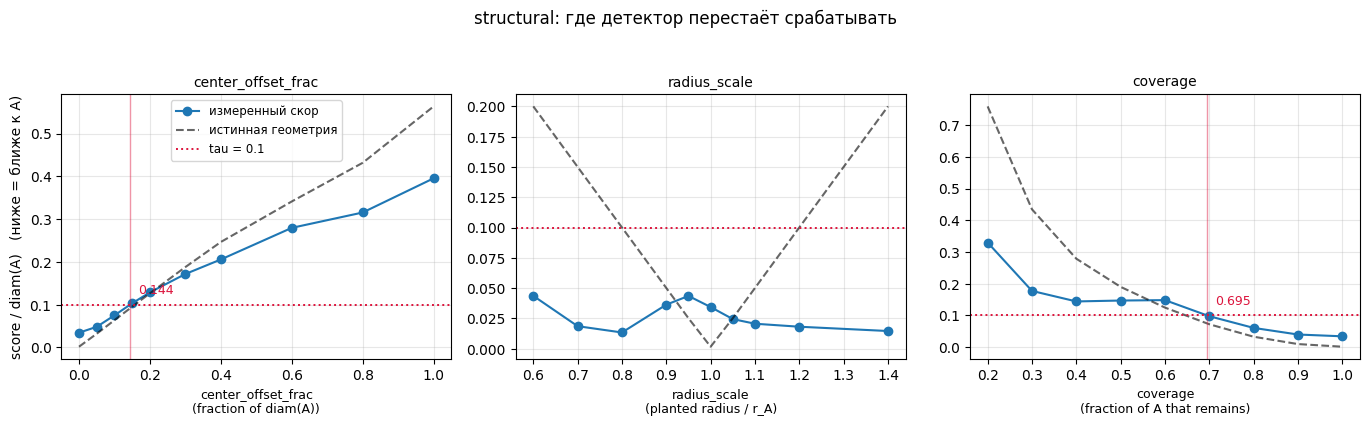

In [27]:
# ── A': кривая детекции — где именно детектор перестаёт срабатывать ──────────
#     Одного положительного примера мало: он показывает, что критерий МОЖЕТ
#     сработать, но не что он срабатывает ТОЛЬКО когда геометрия есть. Здесь
#     геометрия портится на измеренную величину, и мы смотрим, где скор
#     пересекает tau. Считается на ОДНОМ нейроне (подсаженном), не на ансамбле:
#     около 2-3 минут на все три оси. Результат кладётся на диск и
#     переиспользуется.
from visualization.calibration_plots import plot_detection_curves

DETECTION_CSV = Path("analysis/results/calibration/sanity_detection_curves.csv")
DEG_AXES = {
    # ось -> значения; каждая портит окружность своим способом
    "center_offset_frac": [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0],
    "radius_scale":       [0.6, 0.7, 0.8, 0.9, 0.95, 1.0, 1.05, 1.1, 1.2, 1.4],
    "coverage":           [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2],
}

if DETECTION_CSV.exists():
    curves = cal.read_scores_csv(DETECTION_CSV)
    print(f"переиспользую {DETECTION_CSV} ({len(curves)} строк)")
else:
    t0, parts = time.perf_counter(), []
    for axis, values in DEG_AXES.items():
        df = cal.detection_curve(
            probe_model, FEATURES["relevant"]["relevant"], BOUNDS,
            {"structural": CRITS["structural"]}, axis=axis, values=values,
            resolution=REFERENCE_RES, layer_id=3, coord_id=0, verbose=False)
        df["axis"] = axis
        df["value"] = df[axis]
        parts.append(df)
        print(f"  {axis:20s} {len(df)} точек")
    curves = pd.concat(parts, ignore_index=True)
    curves.to_csv(DETECTION_CSV, index=False)
    print(f"готово за {time.perf_counter() - t0:.0f} c → {DETECTION_CSV}")

for axis in DEG_AXES:
    block = curves[curves.axis == axis].sort_values("value")
    x_tau = cal.crossing(block, TAU, x="value", y="score")
    unit = cal.DEGRADATION_AXES[axis][1]
    print(f"\n{axis} ({unit}):")
    print("   " + "  ".join(f"{v:g}→{s:.3f}" for v, s in zip(block.value, block.score)))
    print(f"   пересечение tau: {'нет внутри диапазона' if x_tau is None else f'{x_tau:.3f}'}")

plot_detection_curves(curves, threshold=TAU,
                      save_path=(FIGDIR / "s3_detection_curves.png") if SAVE else None)


**Что показали кривые: детектор срабатывает не на что угодно — и одна ось вскрыла свойство
самого критерия.**

Три способа испортить заведомо правильную геометрию, и три разных ответа.

| ось | что портится | пересечение τ |
|---|---|---|
| `center_offset_frac` | окружность сдвинута | **0.144** доли diam(A) |
| `coverage` | закодирована лишь часть окружности | **0.695** — нужно ≈ 70 % дуги |
| `radius_scale` | не тот радиус | **не пересекает вовсе** в диапазоне 0.6–1.4 |

#### Сдвиг и покрытие: детектор ведёт себя как положено

Скор идёт за истинной геометрией, пока сдвиг мал (0.0343 против 0.0016 при нуле; 0.0749 против
0.0636 при 0.10) и уходит за τ при сдвиге **14.4 % диаметра**. При больших сдвигах измеренный
скор оказывается **ниже** истинного (0.3954 против 0.5636 при сдвиге в целый диаметр) — и это не
ошибка, а проверка на согласованность: скор есть минимум по всем компонентам, поэтому как только
подсаженная окружность уезжает далеко, критерий перестаёт мерить её и начинает мерить пол. 0.3954
лежит ровно в диапазоне пола (0.18–0.37 по размещениям, раздел 4). Кривая упирается в тот же пол,
который мы измерили независимо.

С покрытием то же самое: ниже 0.6 скор выполаживается около 0.145 — снова пол.

#### Радиус: критерий на него не смотрит, и это надо записать

Истинная ошибка растёт буквой V (0.20 при 0.6× и при 1.4×), а измеренный скор всё это время
остаётся между 0.013 и 0.044 — **вердикт «свидетель» на всём диапазоне**. Это не дефект
реализации, а прямое следствие того, как критерий устроен:

`plant_radial_neuron` создаёт **радиально симметричную** функцию, у которой линии уровня — концентрические
окружности **всех** радиусов сразу. Сдвиг радиуса гребня меняет лишь то, **на каком уровне** лежит
окружность радиуса `r_A`, но не убирает её из семейства. А структурный критерий — это минимум
**по уровням**: какой именно уровень несёт фичу, ему безразлично по построению.

Отсюда честная формулировка того, что критерий на самом деле проверяет:

> **«У этого нейрона есть линия уровня, повторяющая A» — а не «гребень этого нейрона и есть A».**
> Критерий инвариантен к тому, на каком уровне сидит фича.

Две оси вместе дают точную границу: **центр локализуется с точностью 14 % диаметра, радиус не
ограничивается вовсе** (в пределах ±40 %). Существенна концентричность, а не размер — потому
сдвиг и деградирует, а масштаб нет. `radius_scale` как ось деградации для этого критерия не
работает и отчитываться по ней нельзя.

#### Что это даёт: τ в физических единицах

Главная польза кривых — они переводят безразмерный скор в понятную величину. Прикладывая
измеренные ранее числа к кривой сдвига и кривой покрытия:

| величина | скор | ≈ сдвиг (доли diam) | ≈ покрытие |
|---|---|---|---|
| подсаженный нейрон | 0.0343 | 0 | 1.00 |
| **медиана task-relevant цели** | 0.0349 | **0.002** | **0.99** |
| **порог τ** | 0.100 | **0.144** | **0.70** |
| `model21` — единственный отказ | 0.1304 | 0.20 | ≈ 0.6 |
| **медиана пола A.1** | 0.1858 | **0.34** | **0.29** |
| медиана task-irrelevant цели | 0.3923 | > 1 | < 0.2 |

Читается это так: **порог τ = 0.1 — это «окружность, сдвинутая на седьмую часть своего диаметра»
или «закодированы 70 % дуги»**. Медианный обученный свидетель на task-relevant задаче
эквивалентен практически идеальной окружности, а пол — окружности, сдвинутой на треть диаметра
или закодированной на 29 %. Это и есть недостающий кусок `CALIBRATION.md` § 1.4: между
подсаженным идеалом и полом теперь есть шкала, а не два числа — но, повторюсь, это заготовка для отдельного эксперимента, а не результат
текущего.

Оговорка: пересчёт сделан по кривой **подсаженной** конструкции, поэтому это интерпретирующая
шкала, а не измерение обученных нейронов. Утверждать «нейрон model21 кодирует окружность,
сдвинутую на 0.20 диаметра» нельзя — можно утверждать, что он набирает столько же, сколько
набрала бы такая окружность.
